# Extracting financial data from Yahoo Finance

## Install libraries

In [2]:
import importlib
import subprocess
import sys

packages = ["yfinance", "numpy", "pandas", "matplotlib", "arch", "statsmodels", "seaborn"]

for pkg in packages:
    try:
        importlib.import_module(pkg)
        print(f"{pkg} is already installed ✅")
    except ImportError:
        print(f"{pkg} not found ❌ Installing...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])

yfinance is already installed ✅
numpy is already installed ✅
pandas is already installed ✅
matplotlib is already installed ✅
arch is already installed ✅
statsmodels is already installed ✅
seaborn is already installed ✅


## Importing essential libraries 

In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from arch import arch_model
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pandas.core import series
import seaborn as sns
from scipy.stats import norm
from scipy.stats import kurtosis

## Importing the stock prices of NVDA, AAPL and MSFT

In [4]:
sp500 = yf.download(
    "^GSPC",
        start="2024-01-01",
        end="2026-07-01",
        auto_adjust=False
    ).reset_index(names = "Date")

[*********************100%***********************]  1 of 1 completed


In [5]:
sp500

Price,Date,Adj Close,Close,High,Low,Open,Volume
Ticker,,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
0,2024-01-02,4742.830078,4742.830078,4754.330078,4722.669922,4745.200195,3743050000
1,2024-01-03,4704.810059,4704.810059,4729.290039,4699.709961,4725.069824,3950760000
2,2024-01-04,4688.680176,4688.680176,4726.779785,4687.529785,4697.419922,3715480000
3,2024-01-05,4697.240234,4697.240234,4721.490234,4682.109863,4690.569824,3844370000
4,2024-01-08,4763.540039,4763.540039,4764.540039,4699.819824,4703.700195,3742320000
...,...,...,...,...,...,...,...
620,2026-06-24,7358.220215,7358.220215,7428.060059,7336.819824,7370.879883,5994860000
621,2026-06-25,7357.490234,7357.490234,7419.080078,7323.500000,7404.910156,5565760000
622,2026-06-26,7354.020020,7354.020020,7392.950195,7294.180176,7312.740234,9105600000


# Splitting the data

In [6]:
def data_split(df, n_train, n_val, n_test=None, date_col=None, verbose=True):
    """Chronological train/val/test split by number of observations.

    n_test=None gives the test set all remaining rows.
    Returns (train, val, test) DataFrames and a dict of positional indices.
    """
    data = df.copy()
    if date_col is not None:
        data[date_col] = pd.to_datetime(data[date_col])
        data = data.sort_values(date_col).set_index(date_col)
    n = len(data)

    if n_test is None:
        n_test = n - n_train - n_val
    if n_test <= 0 or n_train + n_val + n_test != n:
        raise ValueError(f"Counts {n_train}+{n_val}+{n_test} = "
                         f"{n_train + n_val + n_test}, but data has {n} rows.")

    idx = {
        "train": np.arange(0, n_train),
        "val":   np.arange(n_train, n_train + n_val),
        "test":  np.arange(n_train + n_val, n),
    }
    train, val, test = (data.iloc[idx[k]] for k in ("train", "val", "test"))

    if verbose:
        for name, part in zip(("Train", "Val", "Test"), (train, val, test)):
            print(f"{name:5s}: {len(part):4d} obs  {part.index[0]} -> {part.index[-1]}")

    return train, val, test, idx

In [7]:
train_sp500, val_sp500, test_sp500, idx = data_split(sp500, n_train=375, n_val=63,
                                         n_test=187, date_col="Date")

Train:  375 obs  2024-01-02 00:00:00 -> 2025-07-01 00:00:00
Val  :   63 obs  2025-07-02 00:00:00 -> 2025-09-30 00:00:00
Test :  187 obs  2025-10-01 00:00:00 -> 2026-06-30 00:00:00


# Log returns

In [8]:
def transform_to_log_returns(df):
    df = df.copy()
    if "Date" in df.columns:  # already reset_index()'d
        df = df.set_index("Date")
    adj = df["Adj Close"]
    if isinstance(adj, pd.DataFrame):  # yfinance MultiIndex columns
        adj = adj.iloc[:, 0]
    adj = adj.astype(float)
    adj.index = pd.to_datetime(adj.index)
    log_returns = np.log(adj / adj.shift(1)).dropna()
    return pd.DataFrame({"date": log_returns.index, "log_returns": log_returns.values})

In [9]:
sp500_log_returns = transform_to_log_returns(sp500)

In [10]:
sp500_train_lr = transform_to_log_returns(train_sp500)
sp500_val_lr = transform_to_log_returns(val_sp500)
sp500_test_lr = transform_to_log_returns(test_sp500)

In [11]:
sp500_train_lr

,date,log_returns
0,2024-01-03,-0.008049
1,2024-01-04,-0.003434
2,2024-01-05,0.001824
3,2024-01-08,0.014016
4,2024-01-09,-0.001479
...,...,...
369,2025-06-25,-0.000003
370,2025-06-26,0.007988
371,2025-06-27,0.005205
372,2025-06-30,0.005151


In [12]:
sp500_log_returns

,date,log_returns
0,2024-01-03,-0.008049
1,2024-01-04,-0.003434
2,2024-01-05,0.001824
3,2024-01-08,0.014016
4,2024-01-09,-0.001479
...,...,...
619,2026-06-24,-0.000983
620,2026-06-25,-0.000099
621,2026-06-26,-0.000472
622,2026-06-29,0.011682


In [13]:
sp500_train_lr.to_csv("sp500_train_lr.csv")

# Volatility 

In [14]:
def transform_to_log_returns(df):
    # Copy the original dataframe
    result = df.copy()

    # Flatten the column names if using yfinance (MultiIndex)
    result.columns = result.columns.get_level_values(0)

    # Make the index into a column
    result = result.reset_index()

    # Calculate log returns
    result["log_returns"] = np.log(
        result["Adj Close"] / result["Adj Close"].shift(1)
    )

    # Calculate 20-day rolling volatility
    result["volatility"] = (
        result["log_returns"]
        .rolling(window=20)
        .std()
    )

    result["day_of_week"] = result["Date"].dt.weekday

    return result

In [15]:
import pandas_market_calendars as mcal

nyse = mcal.get_calendar("NYSE")

schedule = nyse.schedule(
    start_date="2000-01-01",
    end_date="2026-12-31"
)

In [16]:
sp500_features = transform_to_log_returns(sp500).drop(columns = ["index"])
# aapl_features.to_csv("AAPL_Historical_Cov.csv", index=False)

In [17]:
sp500_features

Price,Date,Adj Close,Close,High,Low,Open,Volume,log_returns,volatility,day_of_week
0,2024-01-02,4742.830078,4742.830078,4754.330078,4722.669922,4745.200195,3743050000,NaN,NaN,1
1,2024-01-03,4704.810059,4704.810059,4729.290039,4699.709961,4725.069824,3950760000,-0.008049,NaN,2
2,2024-01-04,4688.680176,4688.680176,4726.779785,4687.529785,4697.419922,3715480000,-0.003434,NaN,3
3,2024-01-05,4697.240234,4697.240234,4721.490234,4682.109863,4690.569824,3844370000,0.001824,NaN,4
4,2024-01-08,4763.540039,4763.540039,4764.540039,4699.819824,4703.700195,3742320000,0.014016,NaN,0
...,...,...,...,...,...,...,...,...,...,...
620,2026-06-24,7358.220215,7358.220215,7428.060059,7336.819824,7370.879883,5994860000,-0.000983,0.010790,2
621,2026-06-25,7357.490234,7357.490234,7419.080078,7323.500000,7404.910156,5565760000,-0.000099,0.010789,3
622,2026-06-26,7354.020020,7354.020020,7392.950195,7294.180176,7312.740234,9105600000,-0.000472,0.010671,4
623,2026-06-29,7440.430176,7440.430176,7444.319824,7348.879883,7391.879883,5794570000,0.011682,0.011044,0


# Squared Returns 

In [18]:
def squared_returns(log_returns_df):
    date = log_returns_df["date"]
    squared_returns = log_returns_df["log_returns"] ** 2
    squared_returns_df = pd.DataFrame(
        {
            "date": date,
            "squared_returns": squared_returns.squeeze().reset_index(drop=True),
        }
    )
    return squared_returns_df

In [19]:
sp500_sq_returns = squared_returns(sp500_log_returns)

In [20]:
sp500_train_sr = squared_returns(sp500_train_lr)

# Plotting each asset daily adjusted close prices 

In [21]:
def plot_adjusted_close(df, name):
    plt.figure(figsize=(8, 4))
    plt.plot(df.reset_index()["Date"], df["Adj Close"], label=f"{name} Adjusted Close")
    plt.title(f"{name} Adjusted Close Price Over Time")
    plt.xlabel("Date")
    plt.ylabel("Adjusted Close Price")
    plt.legend()
    plt.grid()
    plt.show()

In [22]:
def plot_log_returns(log_returns_df, name):
    plt.figure(figsize=(8, 4))
    plt.plot(log_returns_df["date"], log_returns_df["log_returns"], label=f"{name} Log Returns")
    plt.title(f"{name} Log Returns Over Time")
    plt.xlabel("Date")
    plt.ylabel("Log Returns")
    plt.legend()
    plt.grid()
    plt.show()

In [23]:
def plot_squared_returns(squared_returns_df, name):
    plt.figure(figsize=(8, 4))
    plt.plot(squared_returns_df["date"], squared_returns_df["squared_returns"], label=f"{name} Squared Log Returns")
    plt.title(f"{name} Squared Log Returns Over Time")
    plt.xlabel("Date")
    plt.ylabel("Squared Log Returns")
    plt.legend()
    plt.grid()
    plt.show()

In [24]:
def plot_kurtosis(log_returns_df):
    returns = pd.Series(np.asanyarray(log_returns_df['log_returns']).reshape(-1),
                        index=log_returns_df.index).astype(float)

    plt.figure(figsize=(8,4))
    
    sns.histplot(returns, bins=50, stat="density", label="Log Returns")
    
    # normal curve
    x = np.linspace(returns.min(), returns.max(), 100)
    mean = returns.mean()
    std = returns.std()
    plt.plot(x, norm.pdf(x, mean, std), color='red', label='Normal Distribution')
    
    plt.title("Distribution of Log Returns (Leptokurtosis)")
    plt.legend()
    plt.show()
    
    print("Kurtosis:", kurtosis(returns, fisher=False))

## S&P500

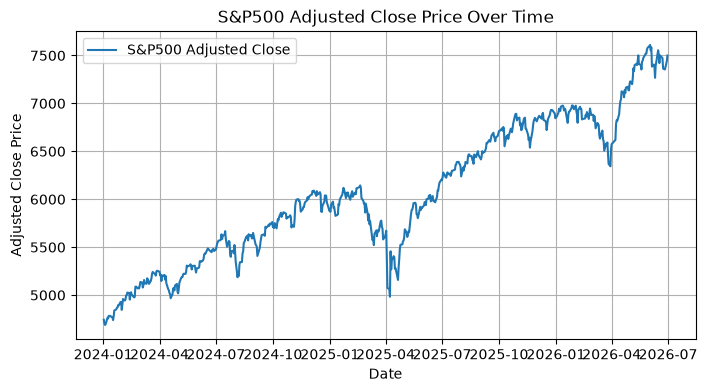

In [25]:
plot_adjusted_close(sp500, "S&P500")

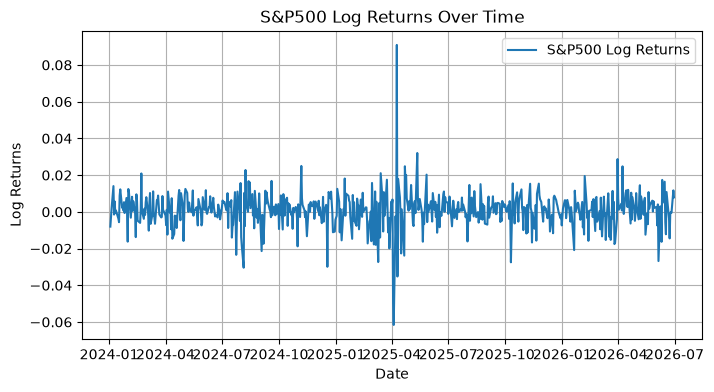

In [26]:
plot_log_returns(sp500_log_returns, "S&P500")

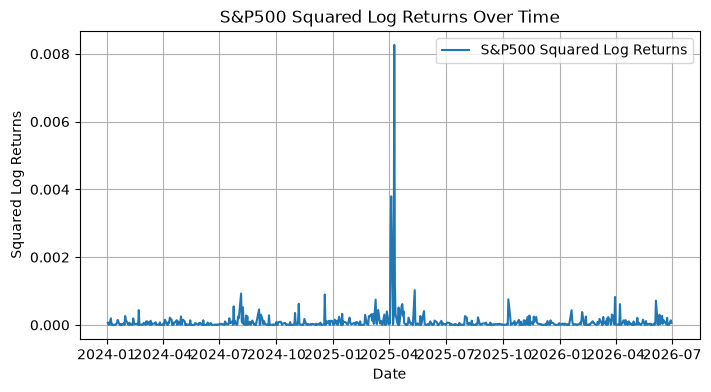

In [27]:
plot_squared_returns(sp500_sq_returns, "S&P500")

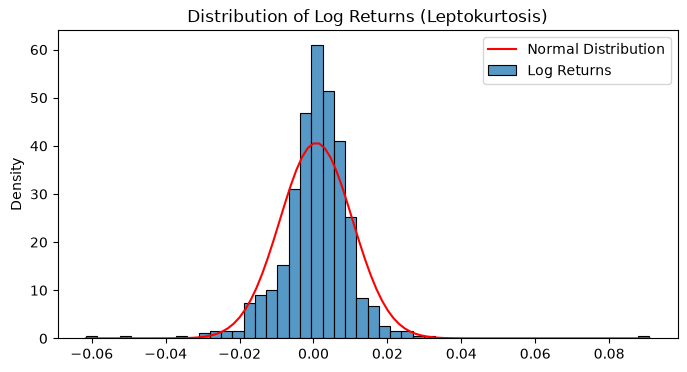

Kurtosis: 17.831277523886907


In [28]:
plot_kurtosis(sp500_log_returns)

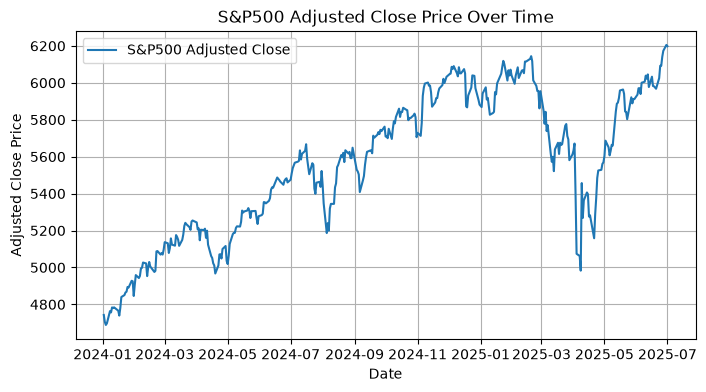

In [29]:
plot_adjusted_close(train_sp500, "S&P500")

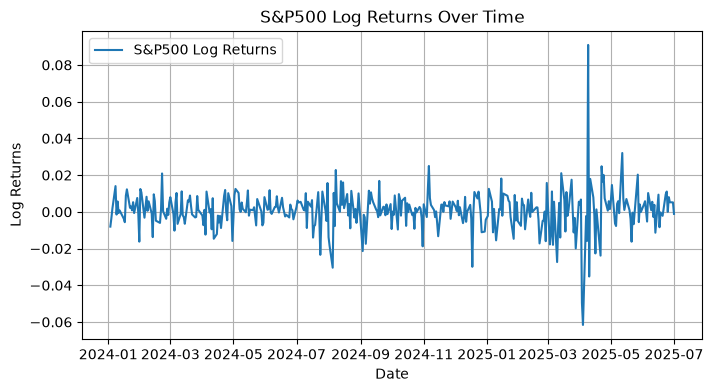

In [30]:
plot_log_returns(sp500_train_lr, "S&P500")

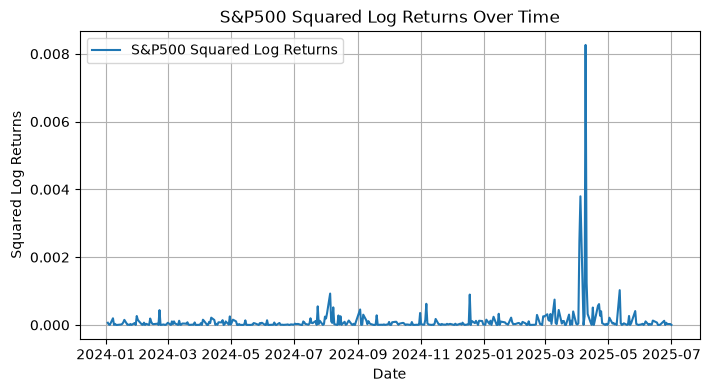

In [31]:
plot_squared_returns(sp500_train_sr, "S&P500")

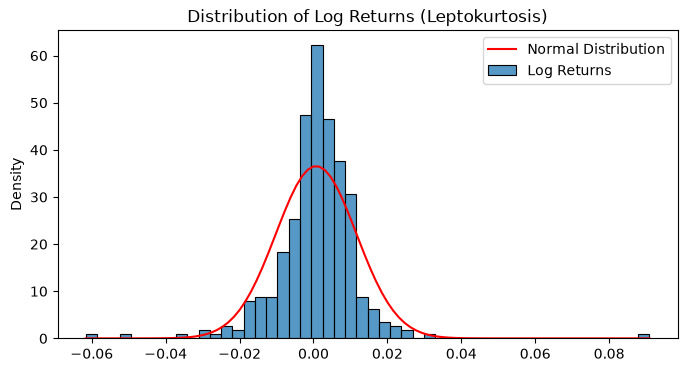

Kurtosis: 18.73935611811504


In [32]:
plot_kurtosis(sp500_train_lr)

# Testing stationarity with Augmented Dickey-Fuller Test 

In [33]:
def stationarity_test(series, name):
    result = adfuller(series)
    print(f"{name}")
    print(f"{name} ADF Statistic: {result[0]:.4f}, p-value: {result[1]:.4f}")
    if result[1] < 0.05:
        print(f"{name} is stationary (reject H0)")
        print("\n")
    else:
        print(f"{name} is not stationary (fail to reject H0)")
        print("\n")

In [34]:
stationarity_test(sp500['Adj Close'], "S&P 500 Adjusted Close")
stationarity_test(sp500_log_returns['log_returns'], "S&P 500 Log Returns")

S&P 500 Adjusted Close
S&P 500 Adjusted Close ADF Statistic: -0.6748, p-value: 0.8532
S&P 500 Adjusted Close is not stationary (fail to reject H0)


S&P 500 Log Returns
S&P 500 Log Returns ADF Statistic: -14.3620, p-value: 0.0000
S&P 500 Log Returns is stationary (reject H0)




In [35]:
stationarity_test(train_sp500['Adj Close'], "S&P 500 Train Adjusted Close")
stationarity_test(sp500_train_lr['log_returns'], "S&P 500 Train Log Returns")

S&P 500 Train Adjusted Close
S&P 500 Train Adjusted Close ADF Statistic: -1.6222, p-value: 0.4716
S&P 500 Train Adjusted Close is not stationary (fail to reject H0)


S&P 500 Train Log Returns
S&P 500 Train Log Returns ADF Statistic: -11.3932, p-value: 0.0000
S&P 500 Train Log Returns is stationary (reject H0)




# Checking PACF and ACF

## S&P 500

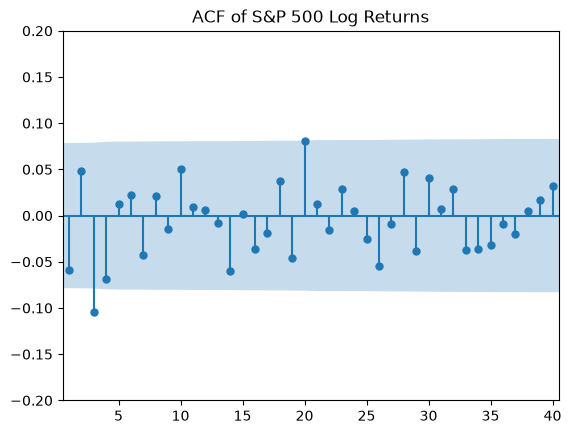

In [36]:
plot_acf(sp500_log_returns['log_returns'], lags=100)
plt.title("ACF of S&P 500 Log Returns")
plt.xlim(0.5, 40.5)
plt.ylim(-0.2, 0.2)
plt.show()

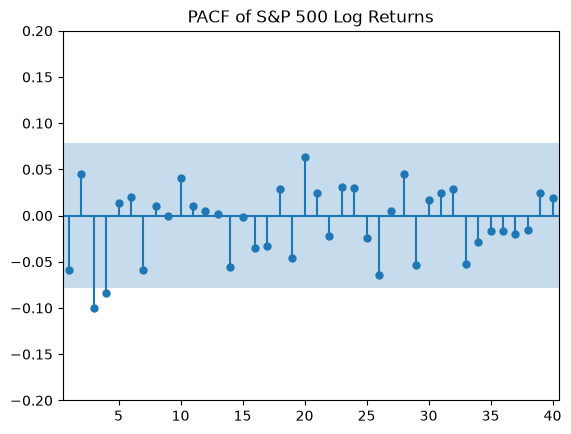

In [37]:
plot_pacf(sp500_log_returns['log_returns'], lags=40)
plt.title("PACF of S&P 500 Log Returns")
plt.xlim(0.5, 40.5)
plt.ylim(-0.2, 0.2)
plt.show()

ACF: Cuts off at lag 3

PACF: Cuts off at lag 4

So we can't conclude a SARIMA Model

No seasonal pattern can be deprived here and both ACF & PACF seem to decay extremely slowly. So, we will just try different combination of ARMA models

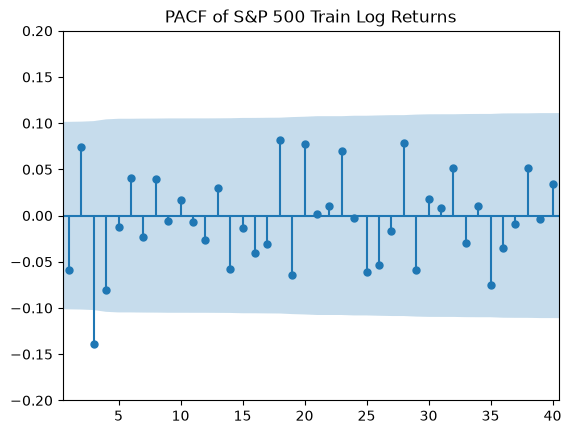

In [38]:
plot_acf(sp500_train_lr['log_returns'], lags=100)
plt.title("PACF of S&P 500 Train Log Returns")
plt.xlim(0.5, 40.5)
plt.ylim(-0.2, 0.2)
plt.show()

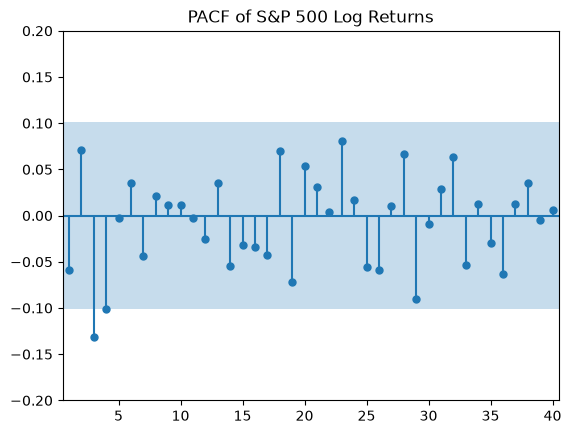

In [39]:
plot_pacf(sp500_train_lr['log_returns'], lags=40)
plt.title("PACF of S&P 500 Log Returns")
plt.xlim(0.5, 40.5)
plt.ylim(-0.2, 0.2)
plt.show()

# Testing combinations of ARMA and SARIMA models

In [40]:
def sarima_diagnostics(series, p_values, q_values, seasonal_pairs, skip_0_0=True, d=0, D=1, s=4):
    y = pd.Series(np.ravel(series)).astype(float).dropna()

    results = []

    for p in p_values:
        for q in q_values:
            if (p, q) == (0, 0) and skip_0_0:
                continue

            for P, Q in seasonal_pairs:
                order = (p, d, q)
                seasonal_order = (P, D, Q, s)
                print(order, seasonal_order)

                try:
                    print(f"Testing SARIMA{order}x{seasonal_order}")

                    model = SARIMAX(
                        y,
                        order=order,
                        seasonal_order=seasonal_order
                    )

                    res = model.fit(disp=False)

                    results.append({
                        "order": order,
                        "seasonal_order": seasonal_order,
                        "AIC": res.aic,
                        "BIC": res.bic
                    })

                    print(res.summary())

                    residuals = res.resid

                    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

                    axes[0, 0].plot(residuals)
                    axes[0, 0].set_title(f"Residuals SARIMA{order}x{seasonal_order}")

                    plot_acf(residuals, lags=20, ax=axes[0, 1], zero=False)
                    axes[0, 1].set_title("ACF of Residuals")
                    axes[0, 1].set_ylim(-0.25, 0.25)

                    plot_pacf(residuals, lags=20, ax=axes[1, 0], zero=False)
                    axes[1, 0].set_title("PACF of Residuals")
                    axes[1, 0].set_ylim(-0.25, 0.25)

                    lb_test = acorr_ljungbox(residuals, lags=10, return_df=True)
                    lags = range(1, 11)

                    axes[1, 1].scatter(lags, lb_test["lb_pvalue"], color="black")
                    axes[1, 1].axhline(y=0.05, color="blue", linestyle="--")
                    axes[1, 1].set_title("Ljung-Box p-values")
                    axes[1, 1].set_xlabel("Lag")
                    axes[1, 1].set_ylabel("p-value")

                    plt.tight_layout()
                    plt.show()

                except Exception as e:
                    print(f"Failed SARIMA{order}x{seasonal_order}: {e}")

    return pd.DataFrame(results).sort_values("AIC")

In [41]:
def arma_diagnostics(series, p_max=3, q_max=3):
    
    # ensure 1D numeric series
    y = pd.Series(np.ravel(series)).astype(float).dropna()
    
    results = []                                   # one row per fitted model
    best_aic = {"order": None, "AIC": np.inf}      # running best by AIC
    best_bic = {"order": None, "BIC": np.inf}      # running best by BIC
    
    for p in range(0, p_max + 1):
        for q in range(0, q_max + 1):
            
            print(f"Testing ARMA({p}, {q})")
            
            try:
                model = ARIMA(y, order=(p, 0, q))
                model_fit = model.fit()
                
                print(model_fit.summary())
                
                residuals = model_fit.resid
                
                # Create subplot grid
                fig, axes = plt.subplots(2, 2, figsize=(12, 8))
                
                # 1. Residuals
                axes[0, 0].plot(residuals)
                axes[0, 0].set_title(f"Residuals (ARMA({p},{q}))")
                
                # 2. ACF
                plot_acf(residuals, lags=20, ax=axes[0, 1], zero=False)
                axes[0, 1].set_title("ACF of Residuals")
                axes[0, 1].set_ylim(-0.1, 0.1)
                
                # 3. PACF
                plot_pacf(residuals, lags=20, ax=axes[1, 0], zero=False)
                axes[1, 0].set_title("PACF of Residuals")
                axes[1, 0].set_ylim(-0.1, 0.1)
                
                # 4. Ljung-Box p-values
                lb_test = acorr_ljungbox(residuals, lags=10, return_df=True)
                lags = range(1, 11)
                
                axes[1, 1].scatter(lags, lb_test['lb_pvalue'], color='black')
                axes[1, 1].axhline(y=0.05, color='blue', linestyle='--')
                axes[1, 1].set_title("Ljung-Box p-values")
                axes[1, 1].set_xlabel("Lag")
                axes[1, 1].set_ylabel("p-value")
                
                plt.tight_layout()
                plt.show()
                
                # Record this model
                adequate = bool((lb_test['lb_pvalue'] > 0.05).all())
                results.append({
                    "order": (p, 0, q),
                    "AIC": model_fit.aic,
                    "BIC": model_fit.bic,
                    "adequate": adequate,
                })
                
                # Update running bests
                if model_fit.aic < best_aic["AIC"]:
                    best_aic = {"order": (p, 0, q), "AIC": model_fit.aic}
                if model_fit.bic < best_bic["BIC"]:
                    best_bic = {"order": (p, 0, q), "BIC": model_fit.bic}
                
            except Exception as e:
                print(f"ARMA({p}, {q}) failed:", e)
                print("\n")
    
    results_df = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
    
    print("\n===== Summary =====")
    print(f"Lowest AIC overall: ARMA{best_aic['order'][0], best_aic['order'][2]}  AIC = {best_aic['AIC']:.3f}")
    print(f"Lowest BIC overall: ARMA{best_bic['order'][0], best_bic['order'][2]}  BIC = {best_bic['BIC']:.3f}")
    
    # Best among models that pass Ljung-Box at all 10 lags (your selection rule)
    adequate_df = results_df[results_df["adequate"]]
    if not adequate_df.empty:
        a = adequate_df.loc[adequate_df["AIC"].idxmin()]
        b = adequate_df.loc[adequate_df["BIC"].idxmin()]
        print(f"Lowest AIC (adequate only): ARMA{a['order'][0], a['order'][2]}  AIC = {a['AIC']:.3f}")
        print(f"Lowest BIC (adequate only): ARMA{b['order'][0], b['order'][2]}  BIC = {b['BIC']:.3f}")
    else:
        print("No model passed Ljung-Box at all 10 lags.")
    
    return results_df, best_aic, best_bic

## S&P 500

### ARMA models

Testing ARMA(0, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                          ARIMA   Log Likelihood                2000.146
Date:                Mon, 16 Nov 2026   AIC                          -3996.292
Time:                        17:31:01   BIC                          -3987.420
Sample:                             0   HQIC                         -3992.844
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.852      0.064   -4.25e-05       0.002
sigma2      9.616e-05   1.88e-06     51.106      0.000    9.25e-05    9.99e-05
Ljung-Box (L1) (Q):              

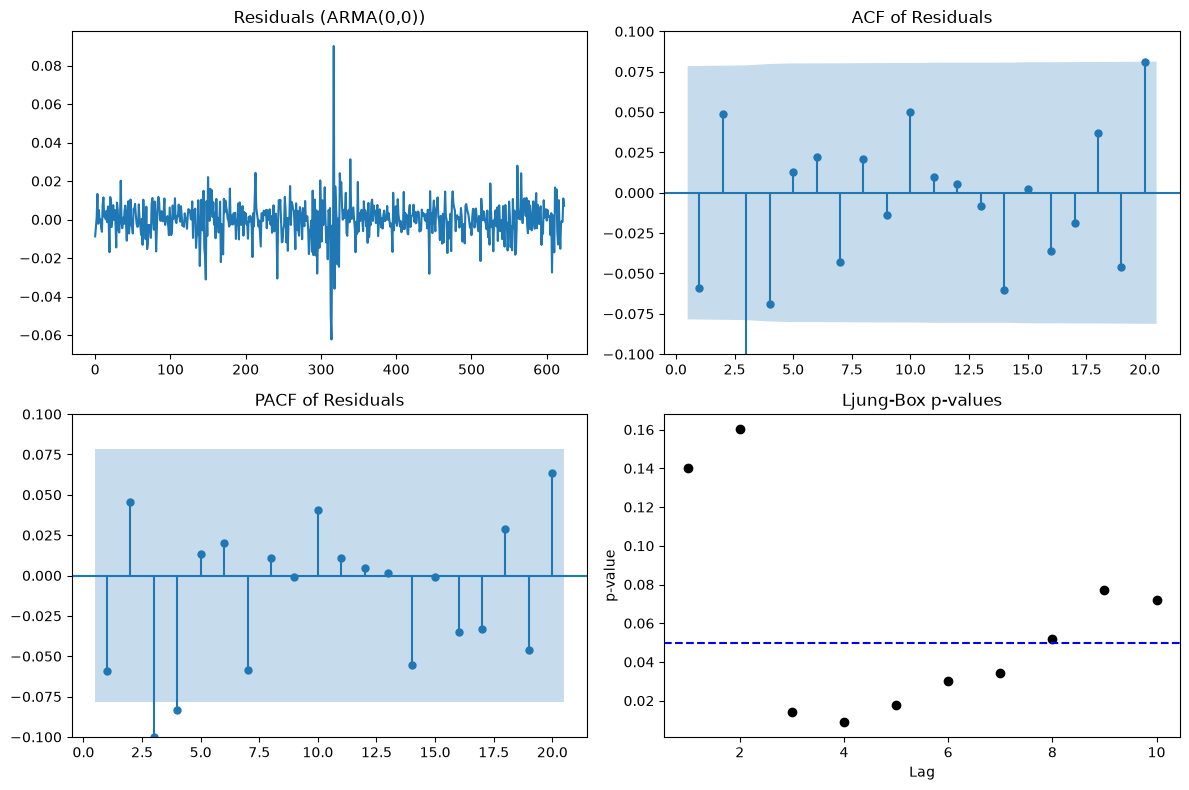

Testing ARMA(0, 1)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(0, 0, 1)   Log Likelihood                2001.147
Date:                Mon, 16 Nov 2026   AIC                          -3996.294
Time:                        17:31:02   BIC                          -3982.986
Sample:                             0   HQIC                         -3991.123
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.889      0.059   -2.75e-05       0.001
ma.L1         -0.0523      0.020     -2.606      0.009      -0.092      -0.013
sigma2      9.584e-05   1.87e-06 

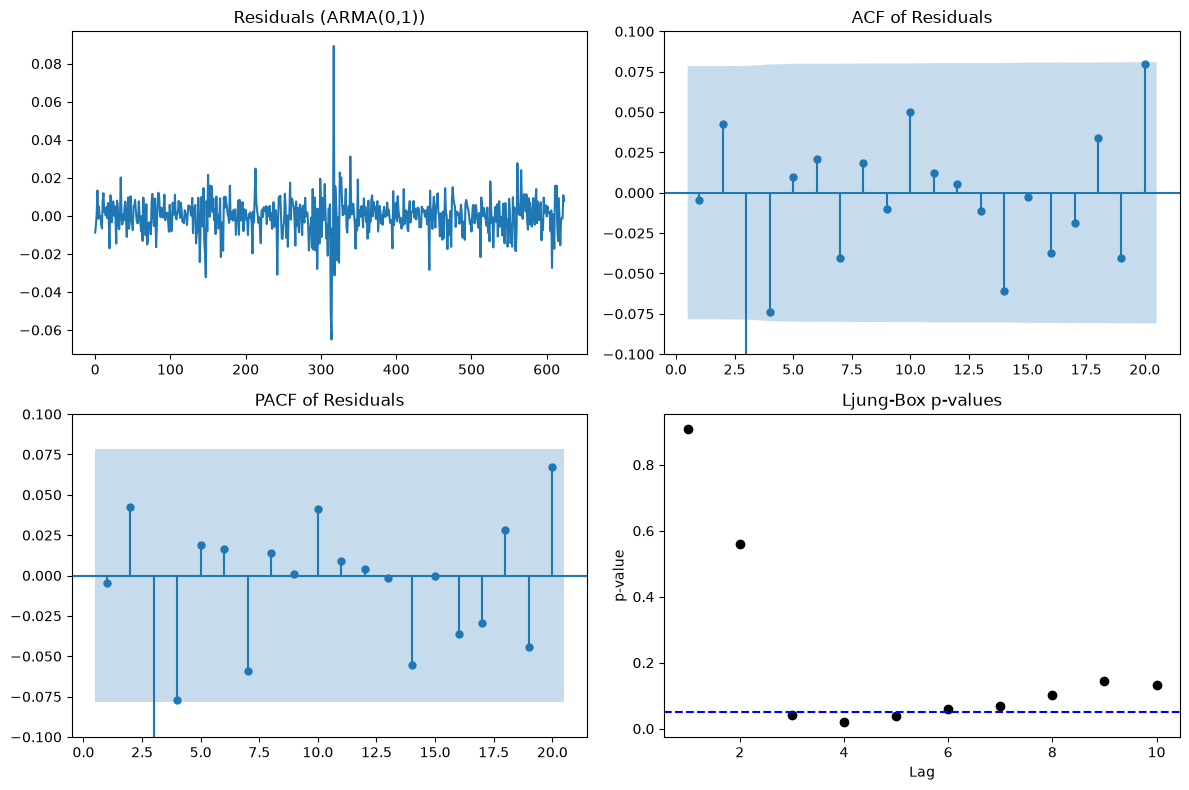

Testing ARMA(0, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(0, 0, 2)   Log Likelihood                2001.593
Date:                Mon, 16 Nov 2026   AIC                          -3995.186
Time:                        17:31:03   BIC                          -3977.441
Sample:                             0   HQIC                         -3988.290
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.804      0.071   -6.32e-05       0.002
ma.L1         -0.0591      0.021     -2.821      0.005      -0.100      -0.018
ma.L2          0.0501      0.039 

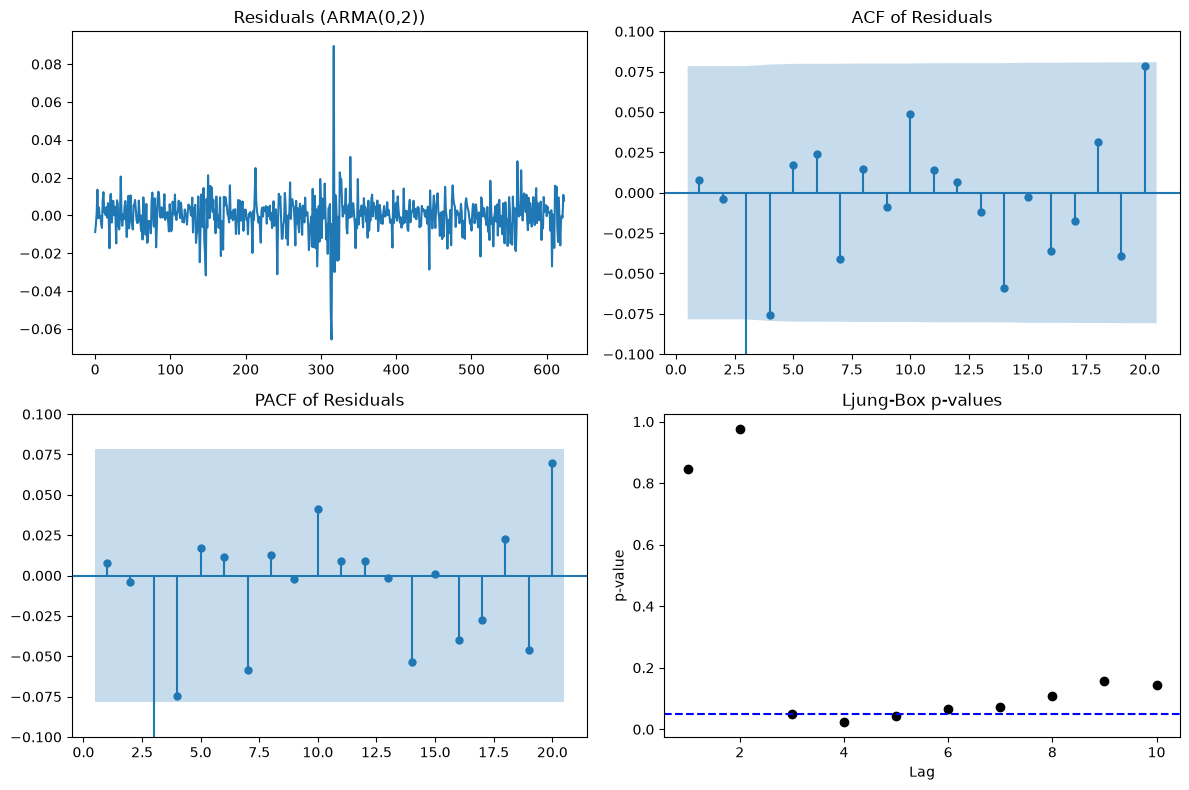

Testing ARMA(0, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(0, 0, 3)   Log Likelihood                2005.714
Date:                Mon, 16 Nov 2026   AIC                          -4001.428
Time:                        17:31:03   BIC                          -3979.247
Sample:                             0   HQIC                         -3992.809
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.825      0.068   -5.41e-05       0.002
ma.L1         -0.0581      0.022     -2.612      0.009      -0.102      -0.014
ma.L2          0.0507      0.035 

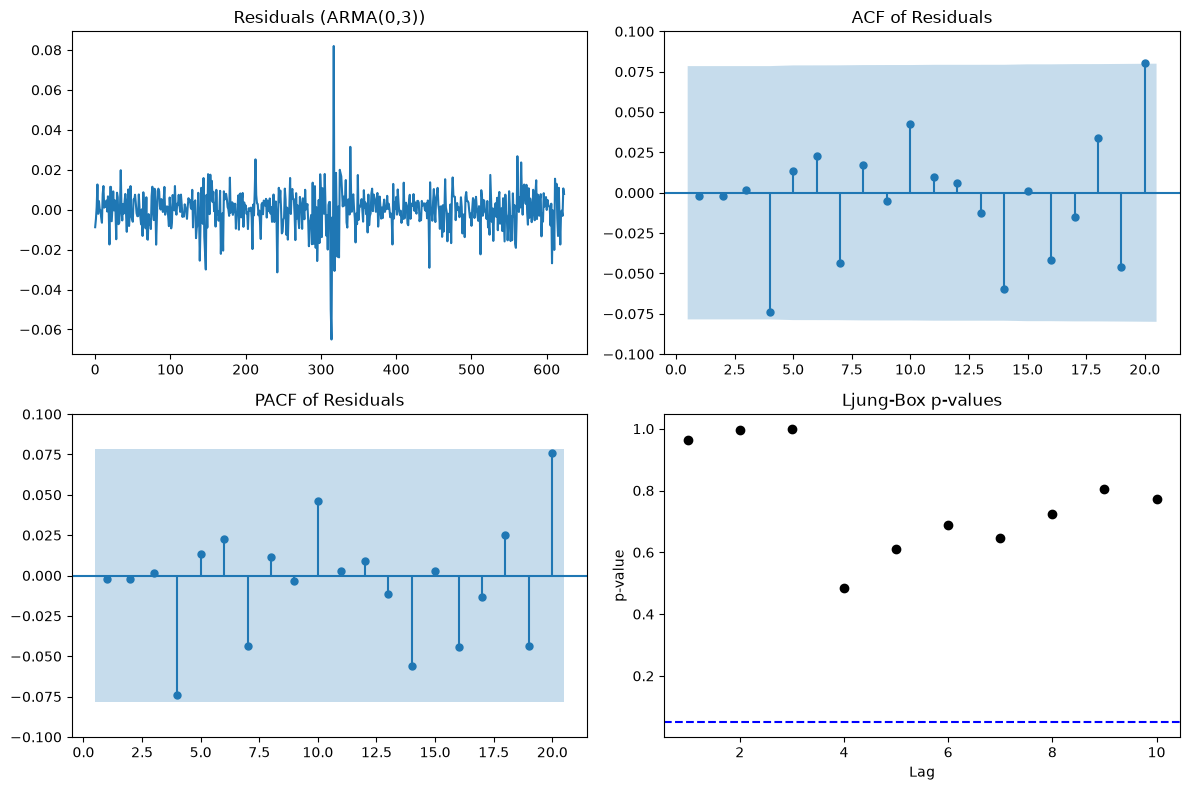

Testing ARMA(0, 4)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(0, 0, 4)   Log Likelihood                2007.556
Date:                Mon, 16 Nov 2026   AIC                          -4003.112
Time:                        17:31:04   BIC                          -3976.495
Sample:                             0   HQIC                         -3992.769
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.872      0.061   -3.43e-05       0.001
ma.L1         -0.0587      0.022     -2.650      0.008      -0.102      -0.015
ma.L2          0.0519      0.035 

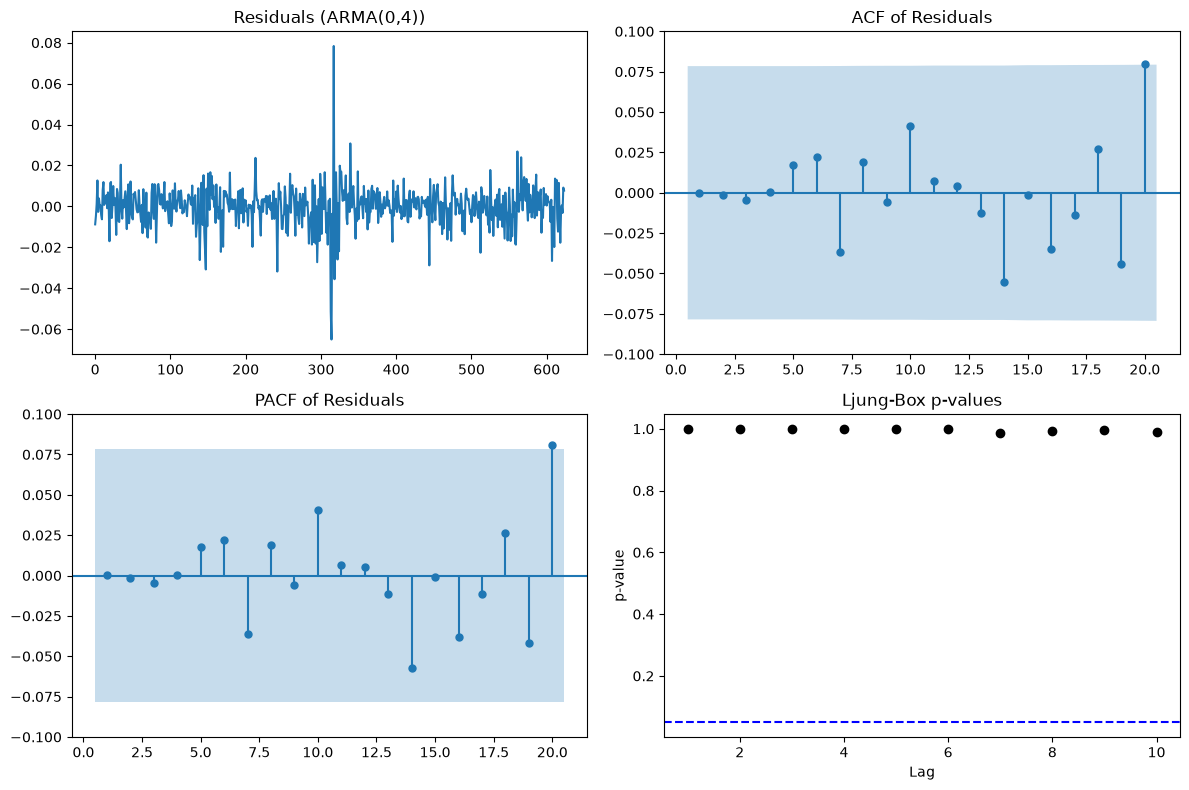

Testing ARMA(1, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(1, 0, 0)   Log Likelihood                2001.232
Date:                Mon, 16 Nov 2026   AIC                          -3996.463
Time:                        17:31:05   BIC                          -3983.155
Sample:                             0   HQIC                         -3991.292
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.906      0.057   -2.07e-05       0.001
ar.L1         -0.0590      0.020     -2.953      0.003      -0.098      -0.020
sigma2      9.592e-05   1.87e-06 

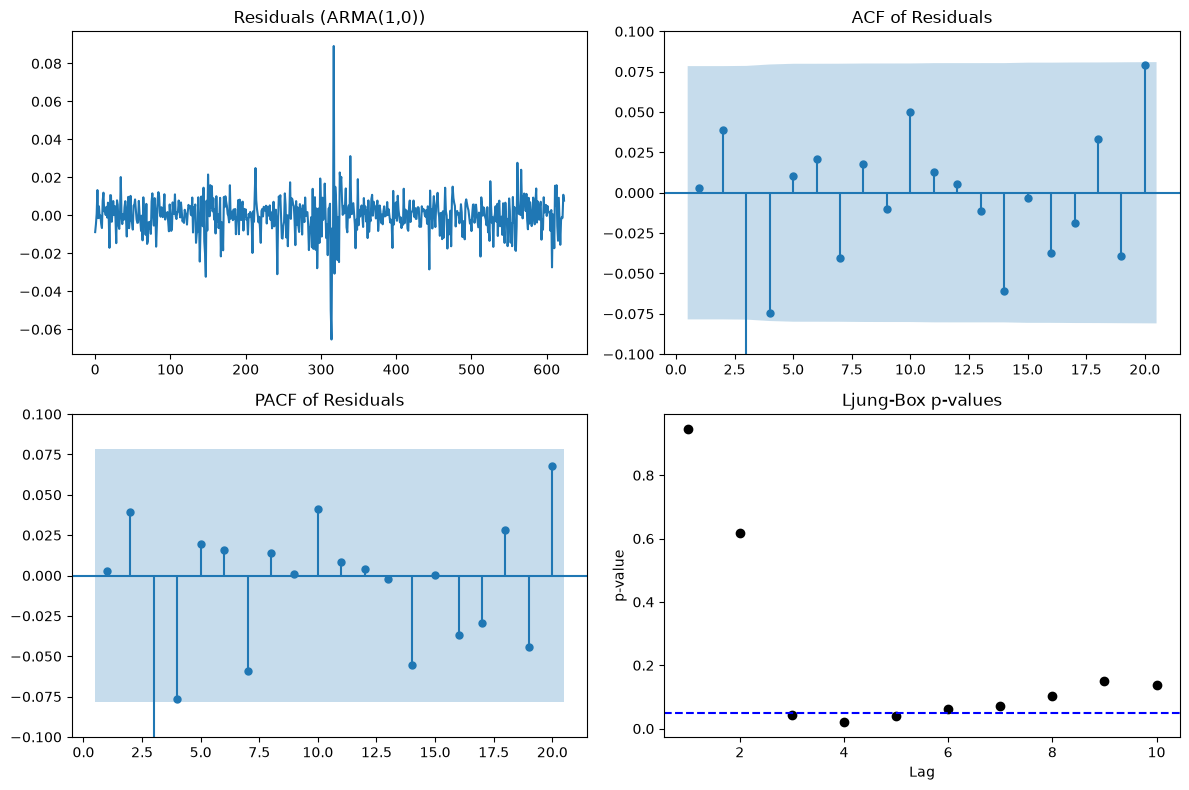

Testing ARMA(1, 1)


c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(1, 0, 1)   Log Likelihood                2002.457
Date:                Mon, 16 Nov 2026   AIC                          -3996.914
Time:                        17:31:06   BIC                          -3979.170
Sample:                             0   HQIC                         -3990.019
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.850      0.064   -4.35e-05       0.002
ar.L1         -0.7082      0.196     -3.612      0.000      -1.092      -0.324
ma.L1          0.6474      0.206      3.146      0.0

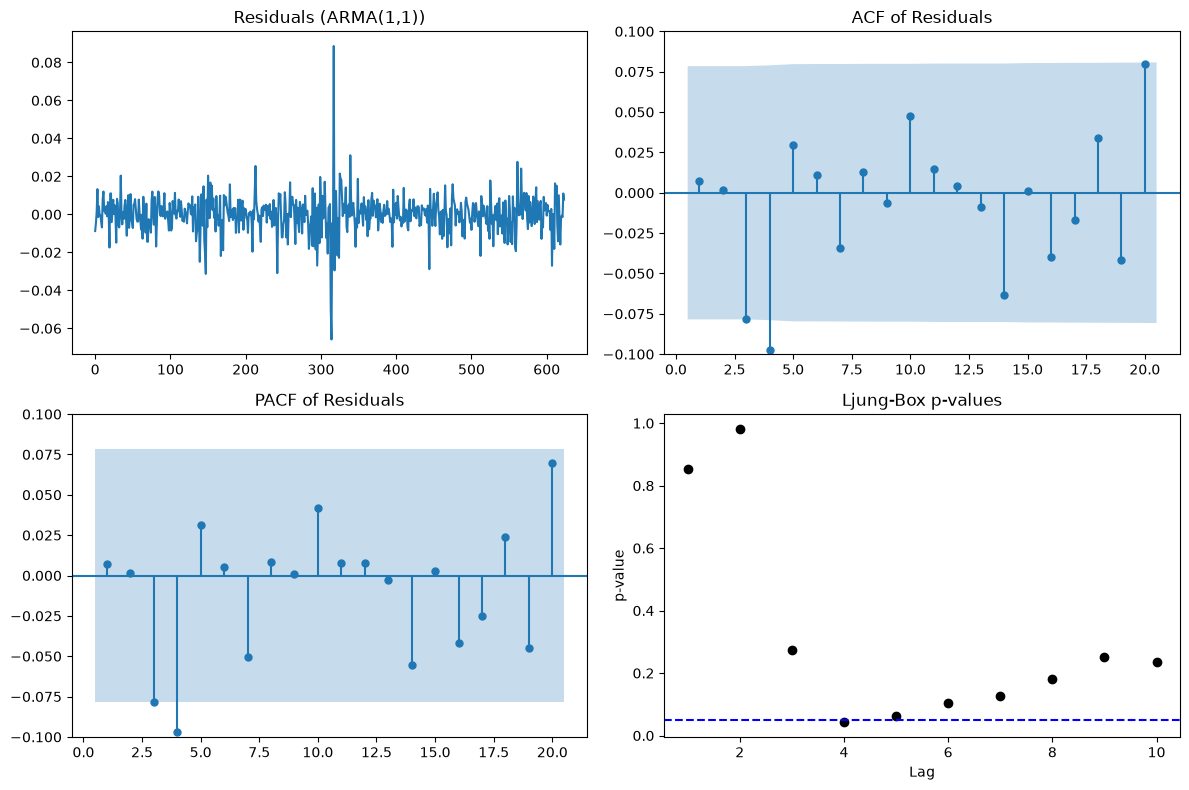

Testing ARMA(1, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(1, 0, 2)   Log Likelihood                2001.299
Date:                Mon, 16 Nov 2026   AIC                          -3992.598
Time:                        17:31:08   BIC                          -3970.418
Sample:                             0   HQIC                         -3983.979
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.534      0.125      -0.000       0.002
ar.L1          0.0755      0.526      0.144      0.886      -0.955       1.106
ma.L1         -0.1346      0.531 

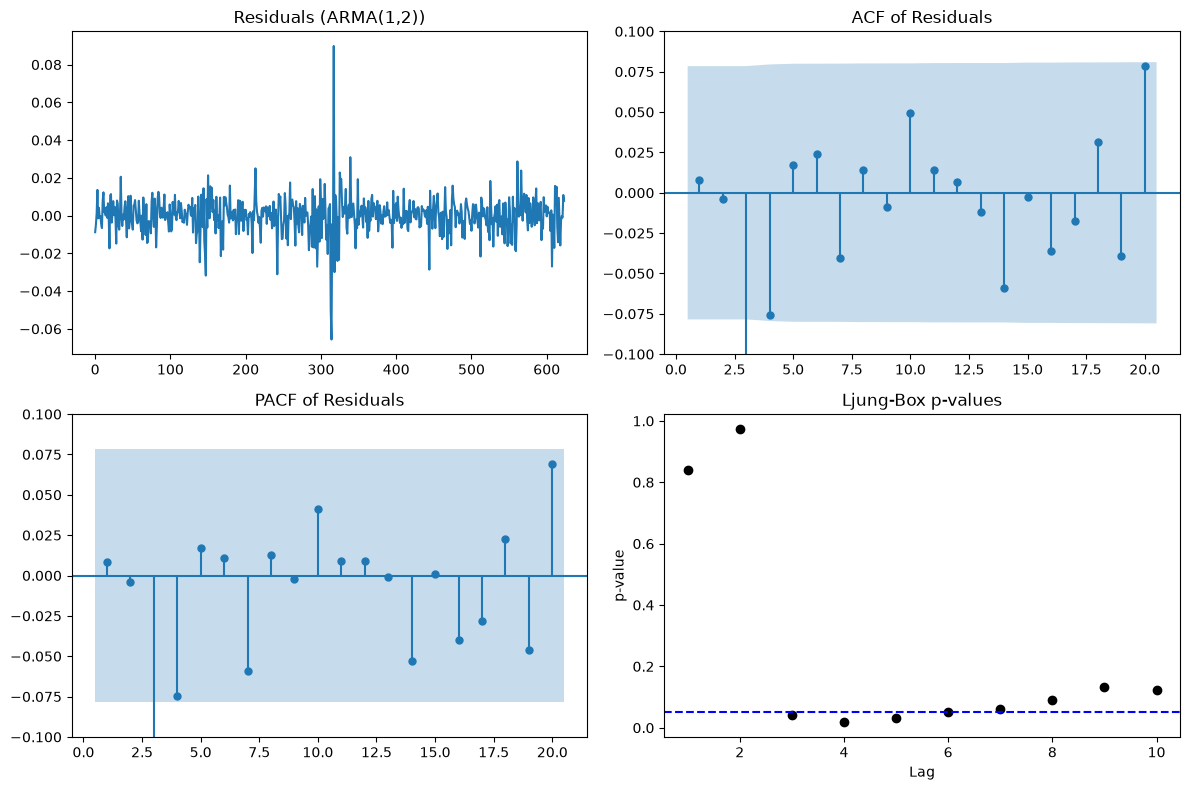

Testing ARMA(1, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(1, 0, 3)   Log Likelihood                2006.857
Date:                Mon, 16 Nov 2026   AIC                          -4001.714
Time:                        17:31:10   BIC                          -3975.097
Sample:                             0   HQIC                         -3991.371
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.859      0.063   -3.95e-05       0.001
ar.L1          0.3570      0.214      1.667      0.096      -0.063       0.777
ma.L1         -0.4151      0.220 

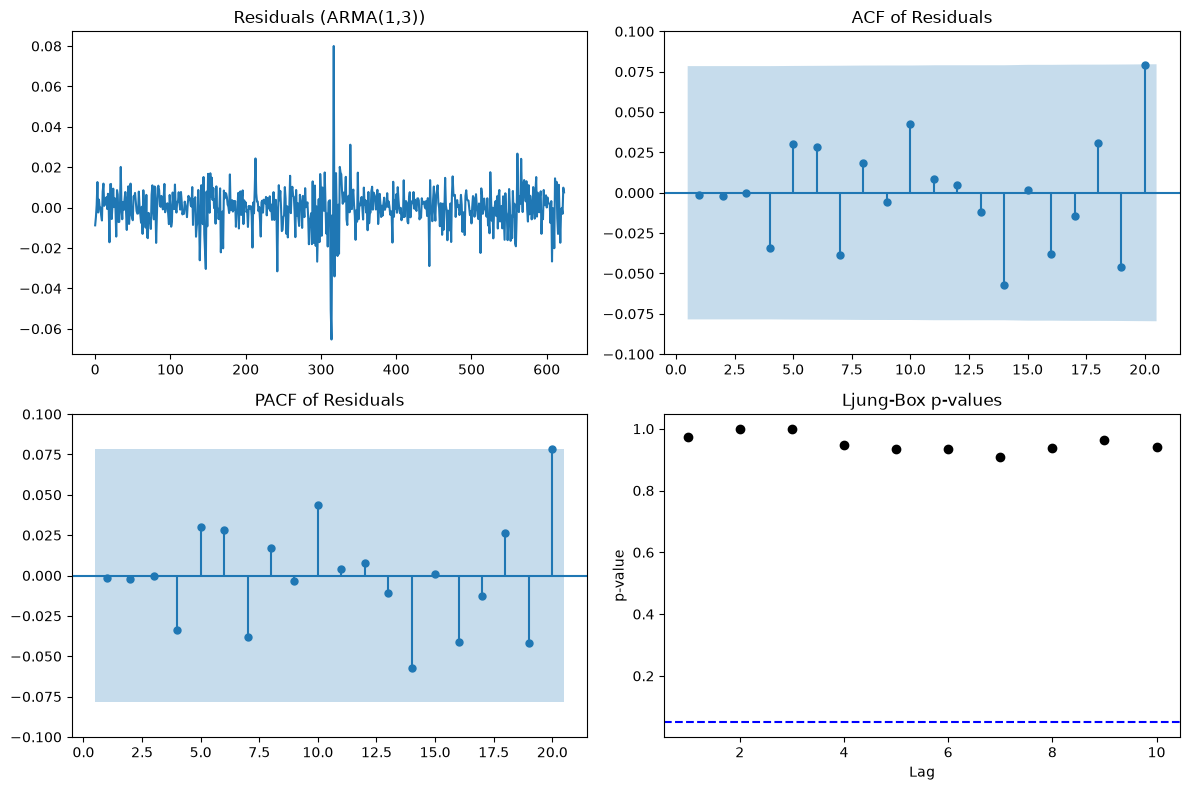

Testing ARMA(1, 4)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(1, 0, 4)   Log Likelihood                2007.452
Date:                Mon, 16 Nov 2026   AIC                          -4000.904
Time:                        17:31:11   BIC                          -3969.851
Sample:                             0   HQIC                         -3988.837
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.834      0.067   -4.99e-05       0.002
ar.L1         -0.3568      0.301     -1.186      0.235      -0.946       0.233
ma.L1          0.2982      0.301 

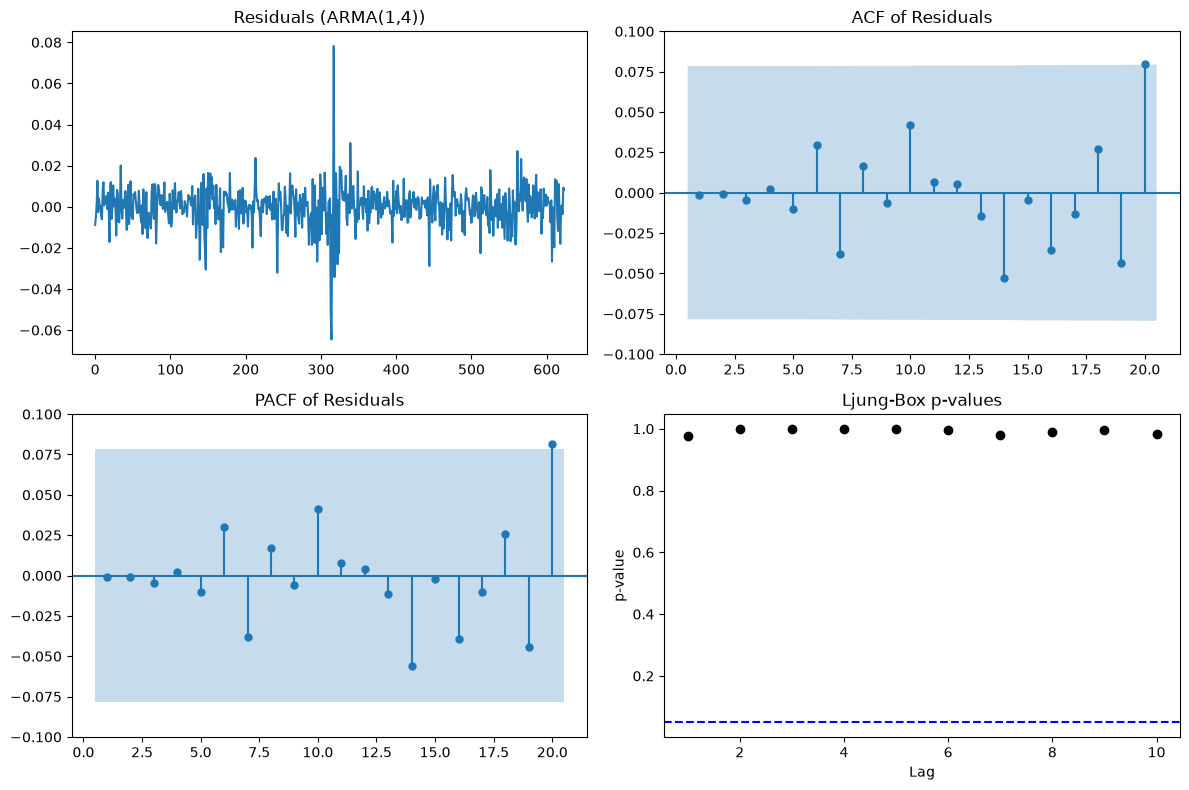

Testing ARMA(2, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(2, 0, 0)   Log Likelihood                2001.870
Date:                Mon, 16 Nov 2026   AIC                          -3995.739
Time:                        17:31:13   BIC                          -3977.994
Sample:                             0   HQIC                         -3988.844
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.789      0.074   -6.99e-05       0.002
ar.L1         -0.0569      0.021     -2.732      0.006      -0.098      -0.016
ar.L2          0.0453      0.040 

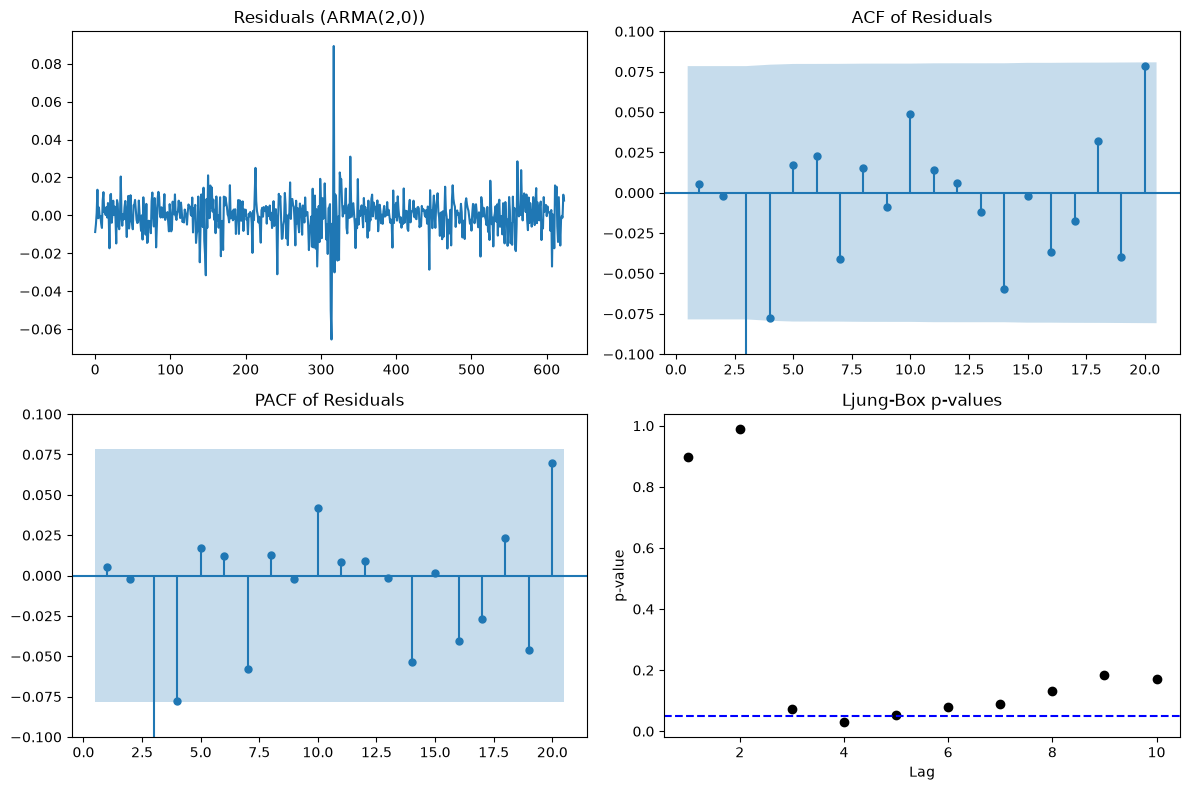

Testing ARMA(2, 1)


c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(2, 0, 1)   Log Likelihood                2002.589
Date:                Mon, 16 Nov 2026   AIC                          -3995.177
Time:                        17:31:14   BIC                          -3972.997
Sample:                             0   HQIC                         -3986.558
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.816      0.069   -5.78e-05       0.002
ar.L1         -0.4781      0.446     -1.073      0.283      -1.351       0.395
ar.L2          0.0312      0.055      0.570      0.5

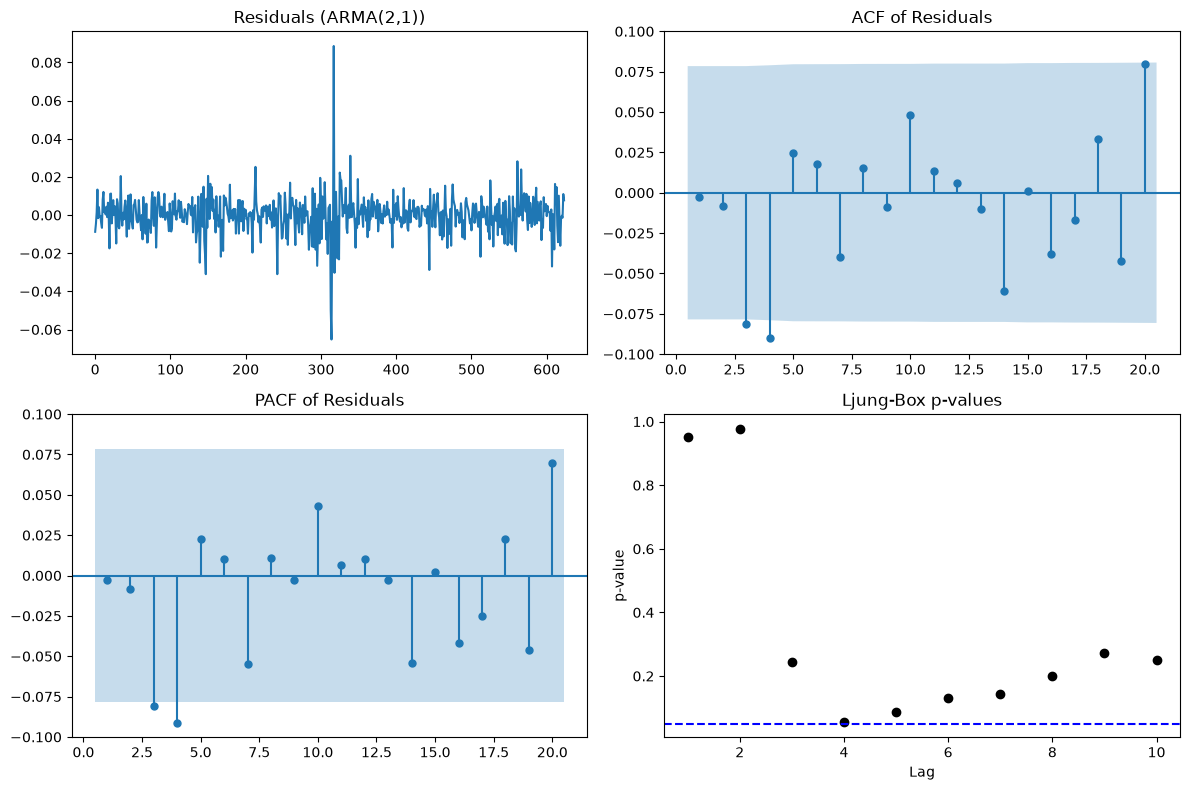

Testing ARMA(2, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(2, 0, 2)   Log Likelihood                2001.297
Date:                Mon, 16 Nov 2026   AIC                          -3990.595
Time:                        17:31:15   BIC                          -3963.978
Sample:                             0   HQIC                         -3980.252
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.489      0.136      -0.000       0.002
ar.L1          0.0755      0.583      0.129      0.897      -1.067       1.218
ar.L2         -0.0008      0.611 

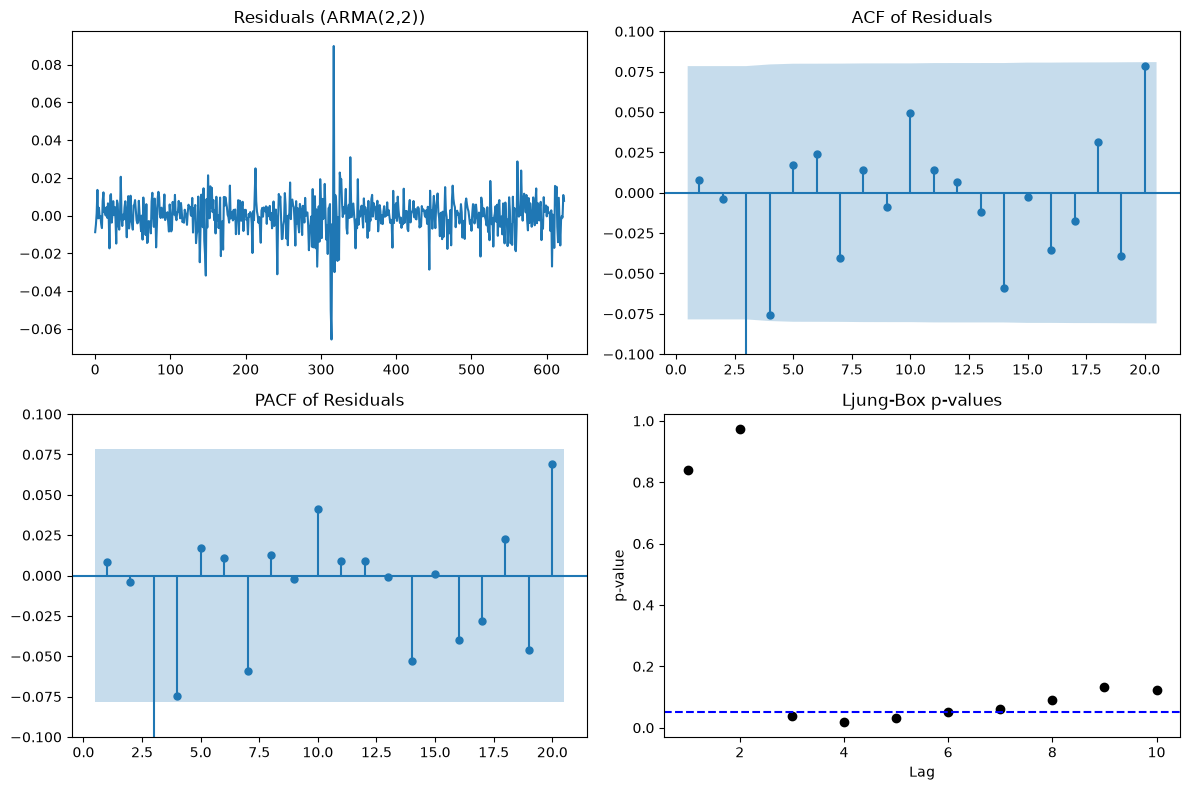

Testing ARMA(2, 3)


c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(2, 0, 3)   Log Likelihood                2007.506
Date:                Mon, 16 Nov 2026   AIC                          -4001.012
Time:                        17:31:16   BIC                          -3969.959
Sample:                             0   HQIC                         -3988.945
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.826      0.068   -5.37e-05       0.002
ar.L1          0.3991      0.174      2.288      0.022       0.057       0.741
ar.L2         -0.4106      0.190     -2.162      0.0

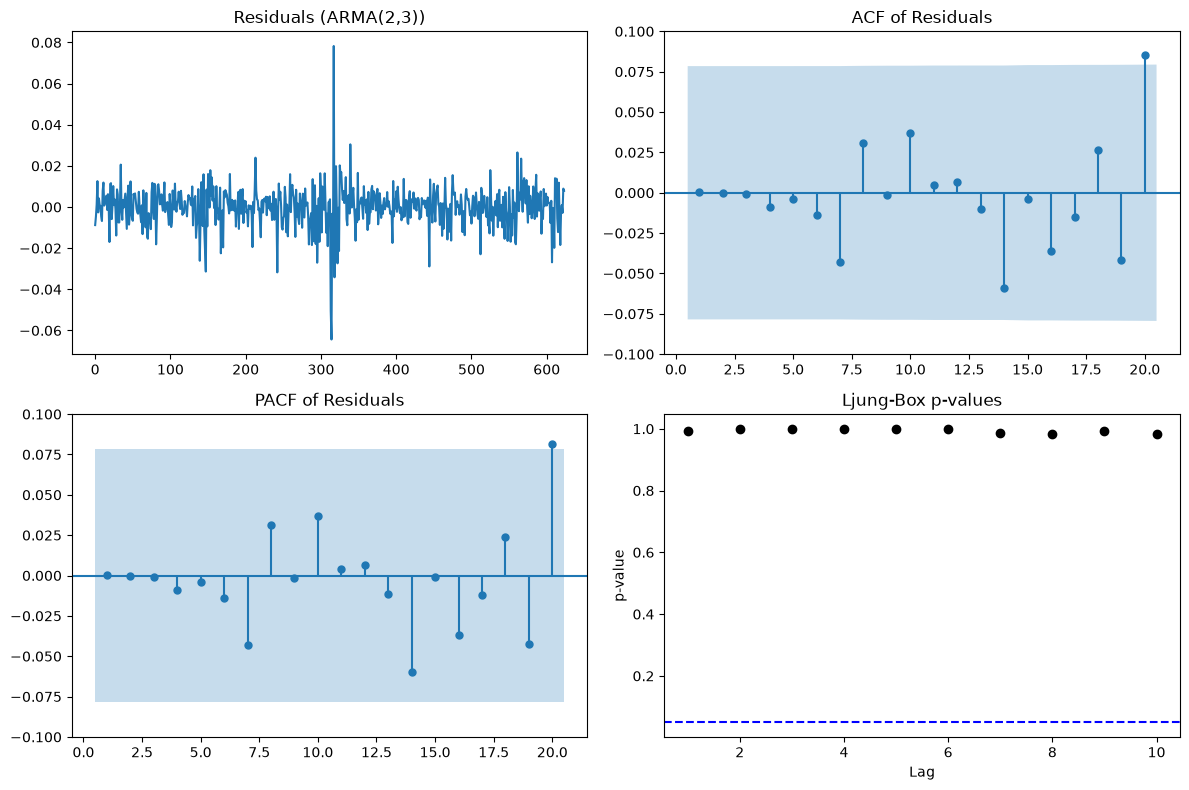

Testing ARMA(2, 4)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(2, 0, 4)   Log Likelihood                2007.539
Date:                Mon, 16 Nov 2026   AIC                          -3999.078
Time:                        17:31:17   BIC                          -3963.589
Sample:                             0   HQIC                         -3985.287
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.820      0.069   -5.61e-05       0.002
ar.L1         -0.3351      0.368     -0.910      0.363      -1.057       0.387
ar.L2         -0.0348      0.308 

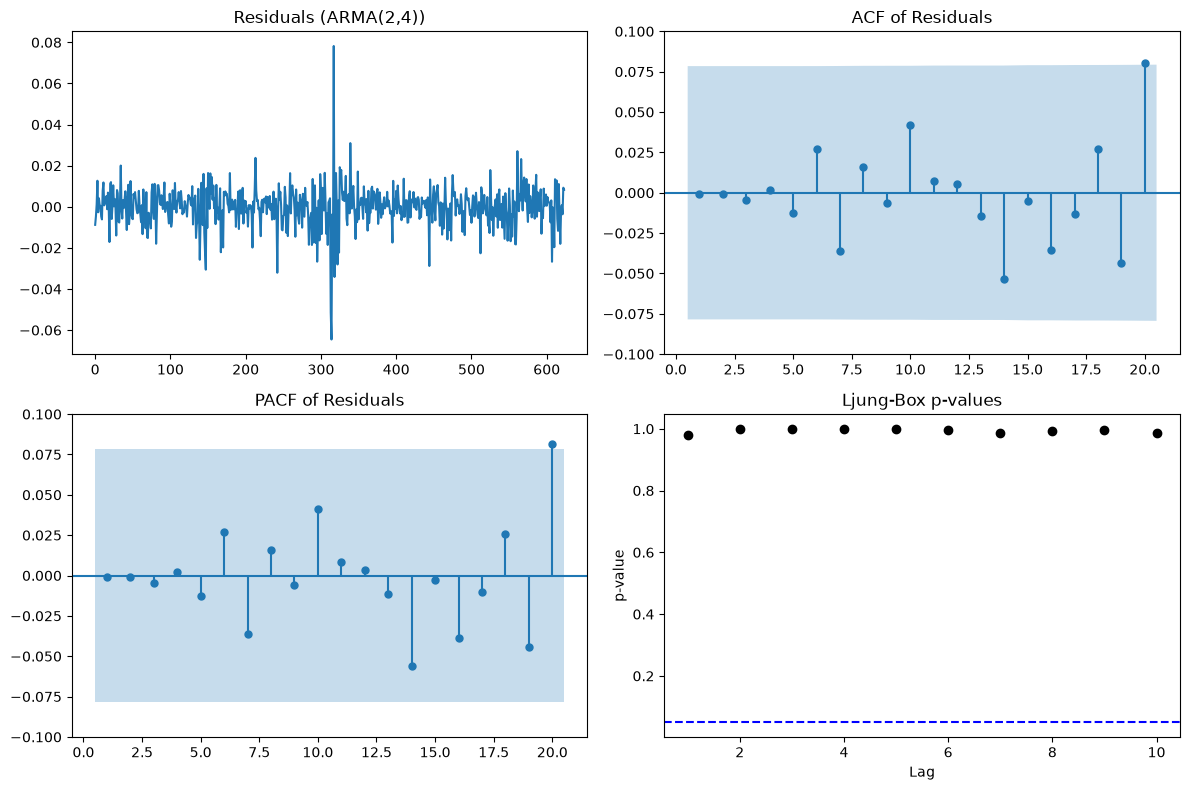

Testing ARMA(3, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(3, 0, 0)   Log Likelihood                2005.000
Date:                Mon, 16 Nov 2026   AIC                          -4000.001
Time:                        17:31:18   BIC                          -3977.820
Sample:                             0   HQIC                         -3991.381
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.840      0.066   -4.77e-05       0.002
ar.L1         -0.0523      0.022     -2.430      0.015      -0.094      -0.010
ar.L2          0.0397      0.037 

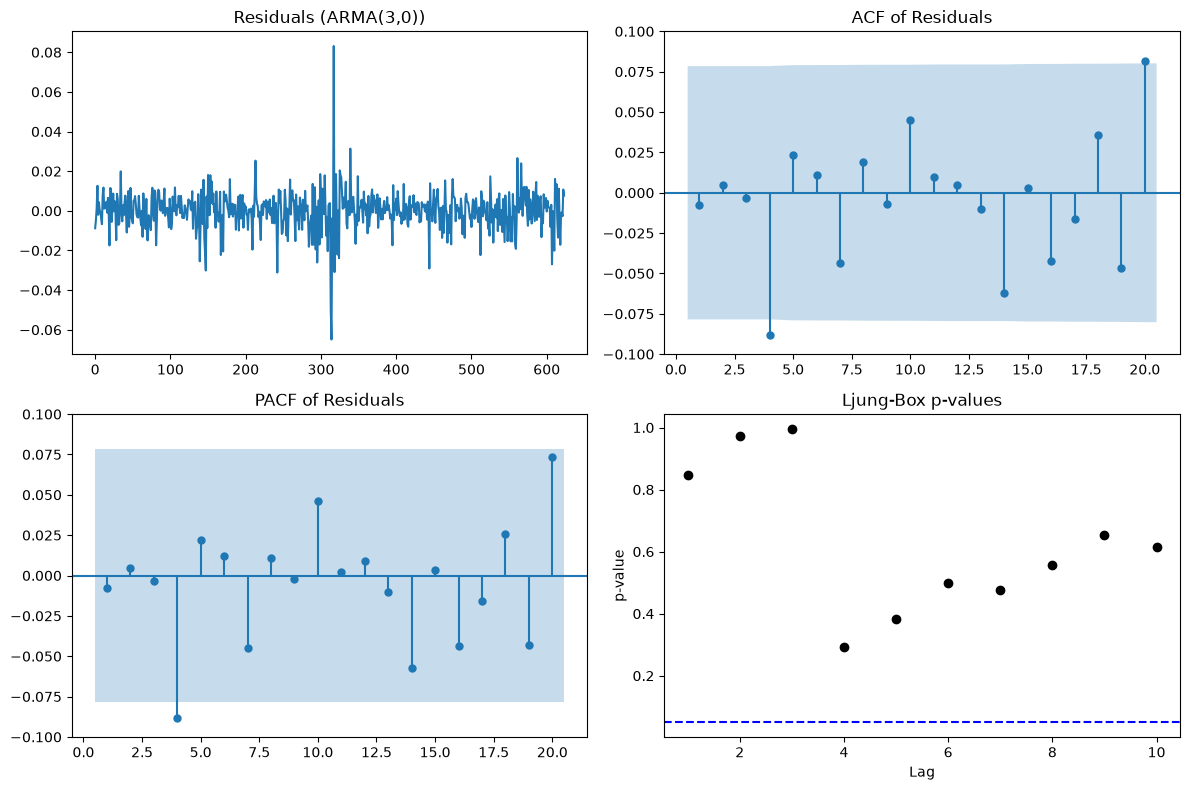

Testing ARMA(3, 1)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(3, 0, 1)   Log Likelihood                2005.116
Date:                Mon, 16 Nov 2026   AIC                          -3998.233
Time:                        17:31:19   BIC                          -3971.616
Sample:                             0   HQIC                         -3987.890
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.691      0.091      -0.000       0.002
ar.L1         -0.0296      0.270     -0.110      0.913      -0.558       0.499
ar.L2          0.0410      0.040 

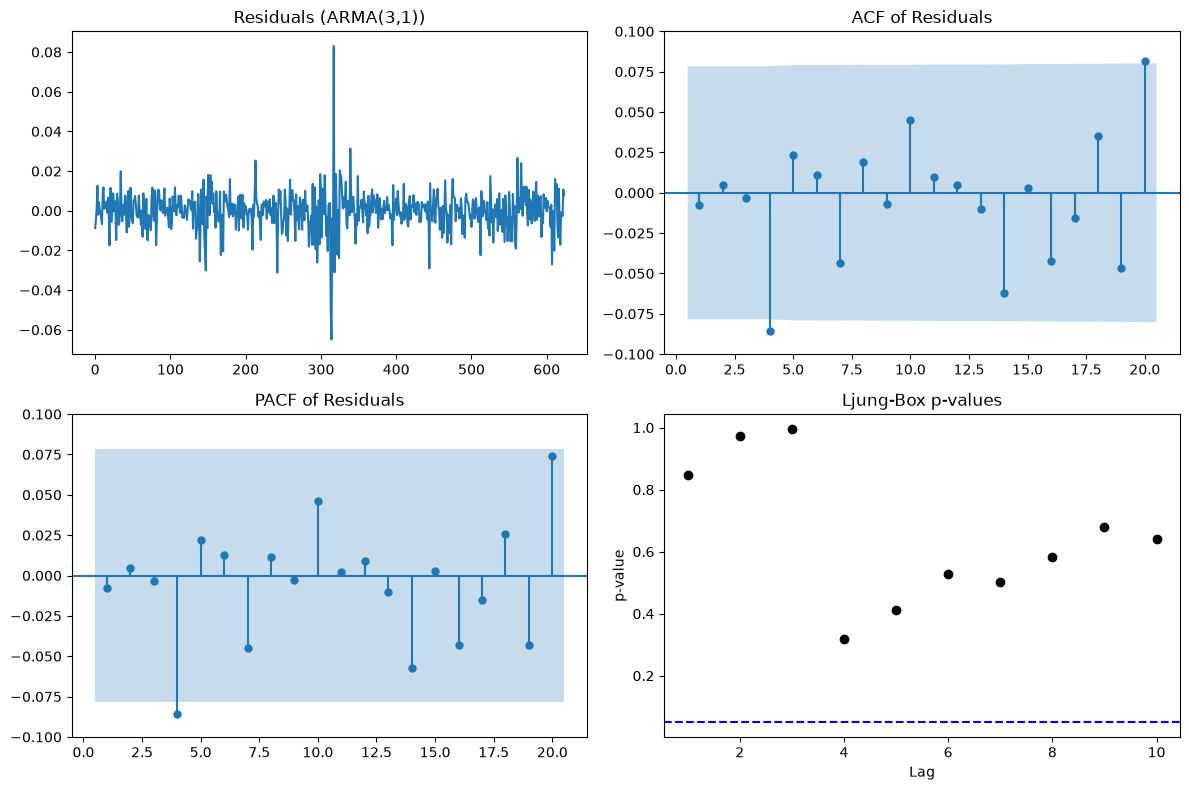

Testing ARMA(3, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(3, 0, 2)   Log Likelihood                2006.374
Date:                Mon, 16 Nov 2026   AIC                          -3998.748
Time:                        17:31:20   BIC                          -3967.695
Sample:                             0   HQIC                         -3986.681
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.842      0.066   -4.68e-05       0.002
ar.L1          0.4691      0.181      2.597      0.009       0.115       0.823
ar.L2         -0.3988      0.199 

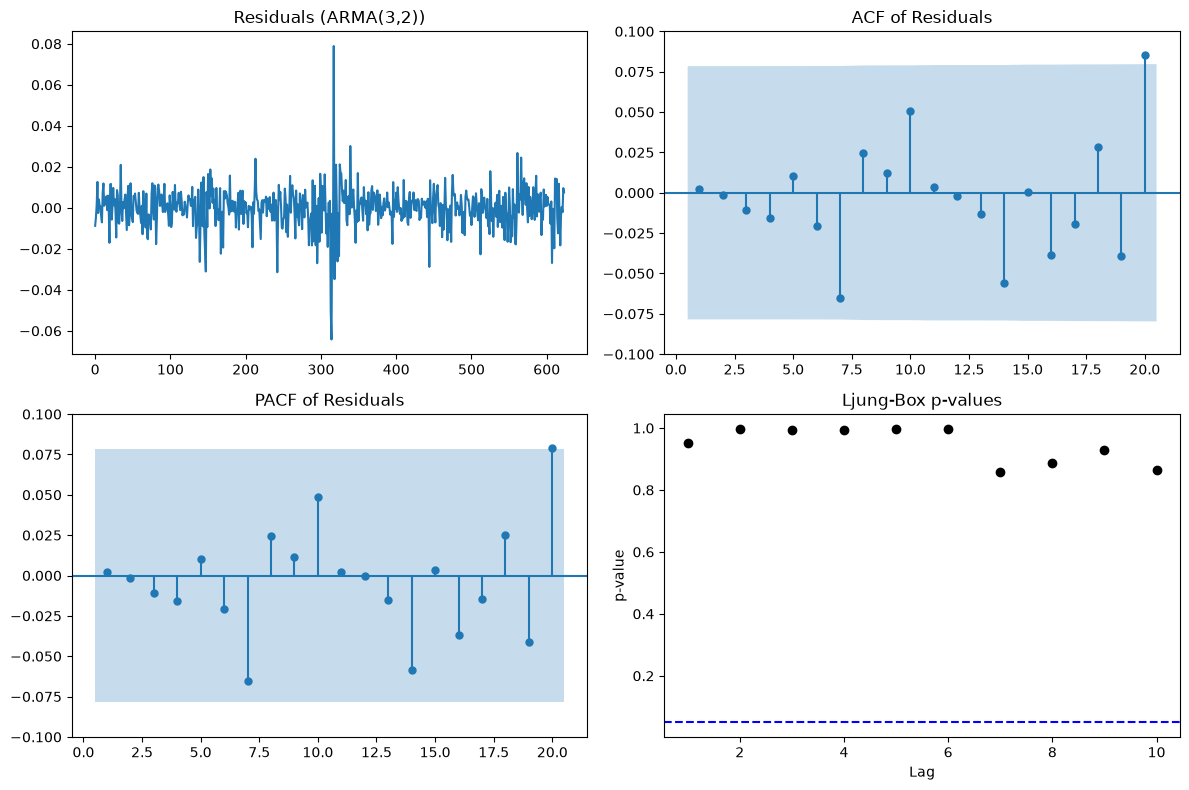

Testing ARMA(3, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(3, 0, 3)   Log Likelihood                2007.893
Date:                Mon, 16 Nov 2026   AIC                          -3999.786
Time:                        17:31:21   BIC                          -3964.297
Sample:                             0   HQIC                         -3985.995
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.872      0.061   -3.43e-05       0.001
ar.L1          0.3972      0.147      2.704      0.007       0.109       0.685
ar.L2         -0.3948      0.211 

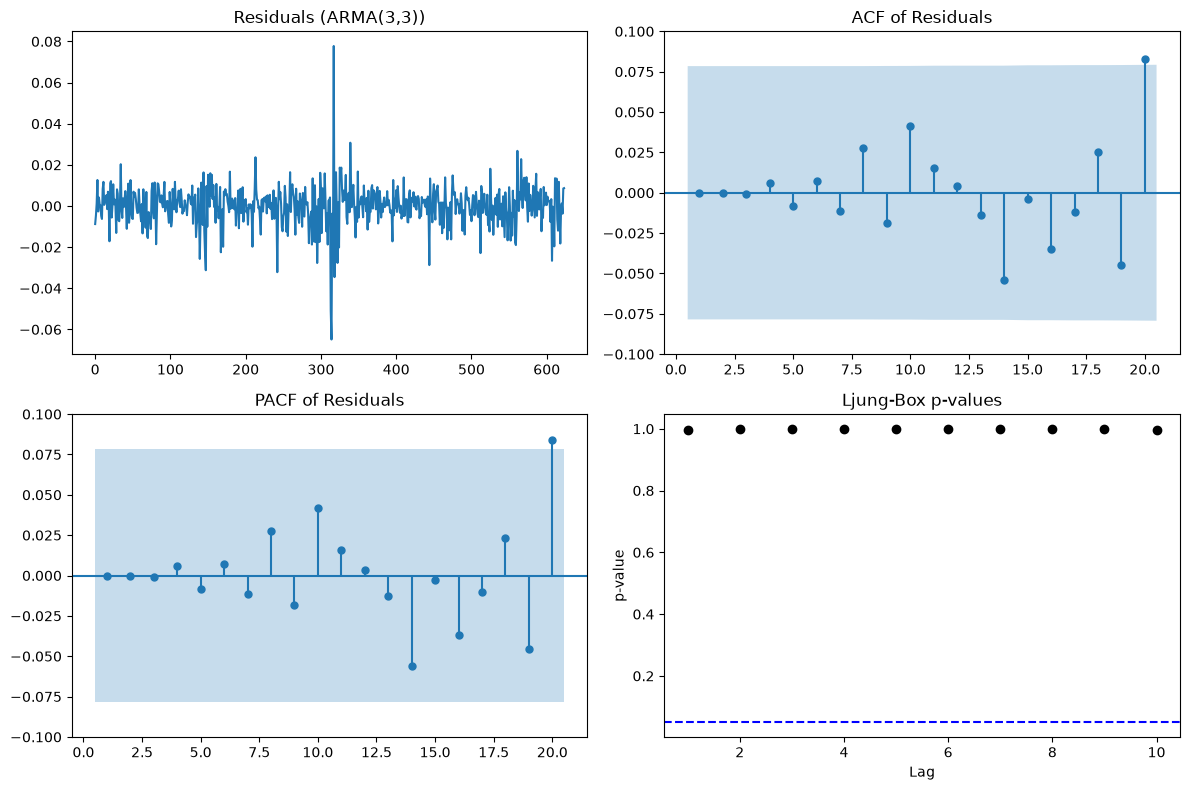

Testing ARMA(3, 4)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(3, 0, 4)   Log Likelihood                2007.256
Date:                Mon, 16 Nov 2026   AIC                          -3996.512
Time:                        17:31:22   BIC                          -3956.587
Sample:                             0   HQIC                         -3980.997
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.781      0.075   -7.33e-05       0.002
ar.L1         -0.4982      0.374     -1.331      0.183      -1.232       0.235
ar.L2          0.0028      0.270 

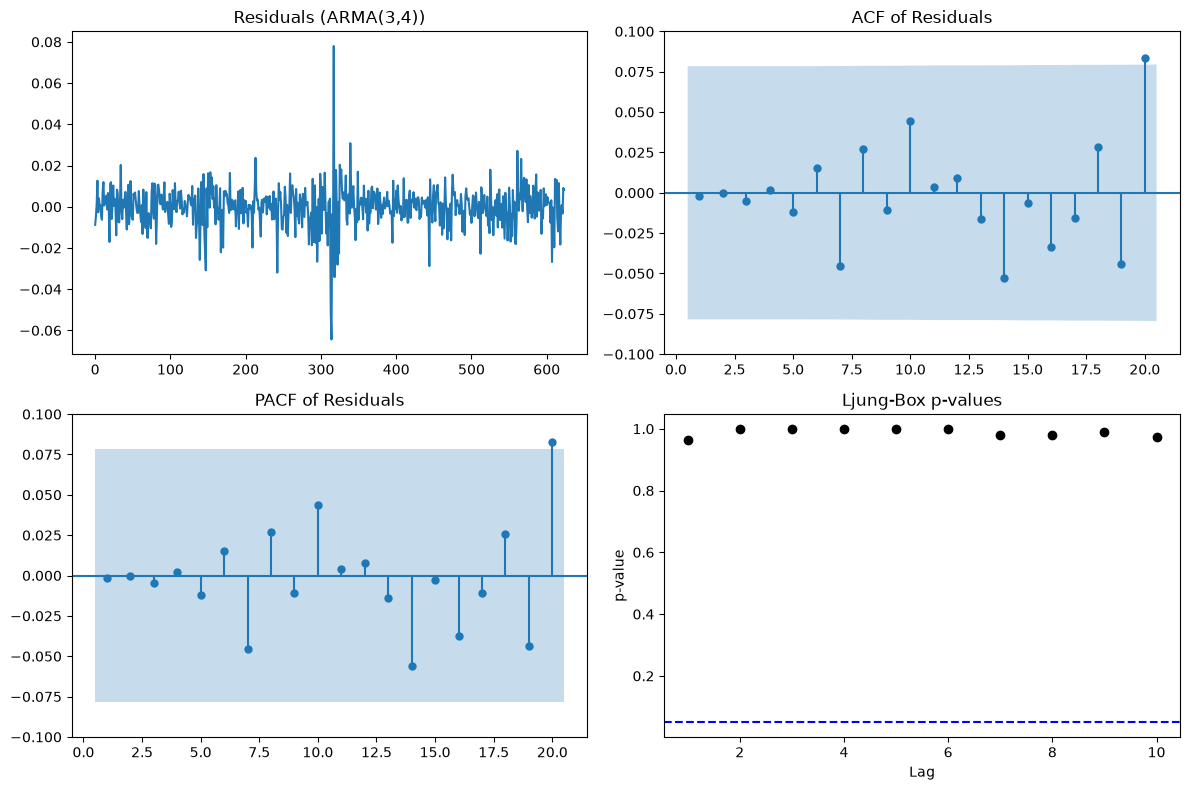

Testing ARMA(4, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(4, 0, 0)   Log Likelihood                2007.180
Date:                Mon, 16 Nov 2026   AIC                          -4002.361
Time:                        17:31:23   BIC                          -3975.744
Sample:                             0   HQIC                         -3992.018
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.832      0.067   -5.07e-05       0.002
ar.L1         -0.0609      0.022     -2.812      0.005      -0.103      -0.018
ar.L2          0.0440      0.038 

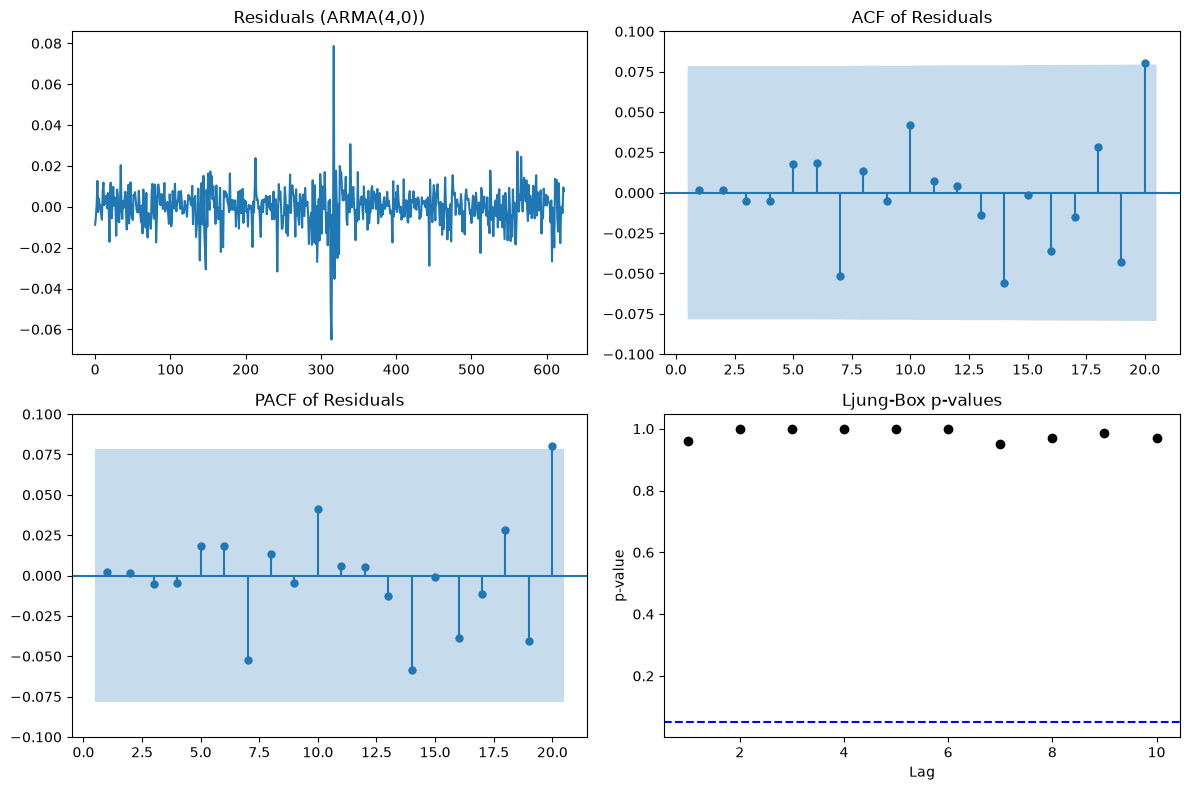

Testing ARMA(4, 1)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(4, 0, 1)   Log Likelihood                2007.156
Date:                Mon, 16 Nov 2026   AIC                          -4000.313
Time:                        17:31:23   BIC                          -3969.260
Sample:                             0   HQIC                         -3988.246
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.842      0.066   -4.69e-05       0.002
ar.L1         -0.0341      0.316     -0.108      0.914      -0.653       0.585
ar.L2          0.0456      0.043 

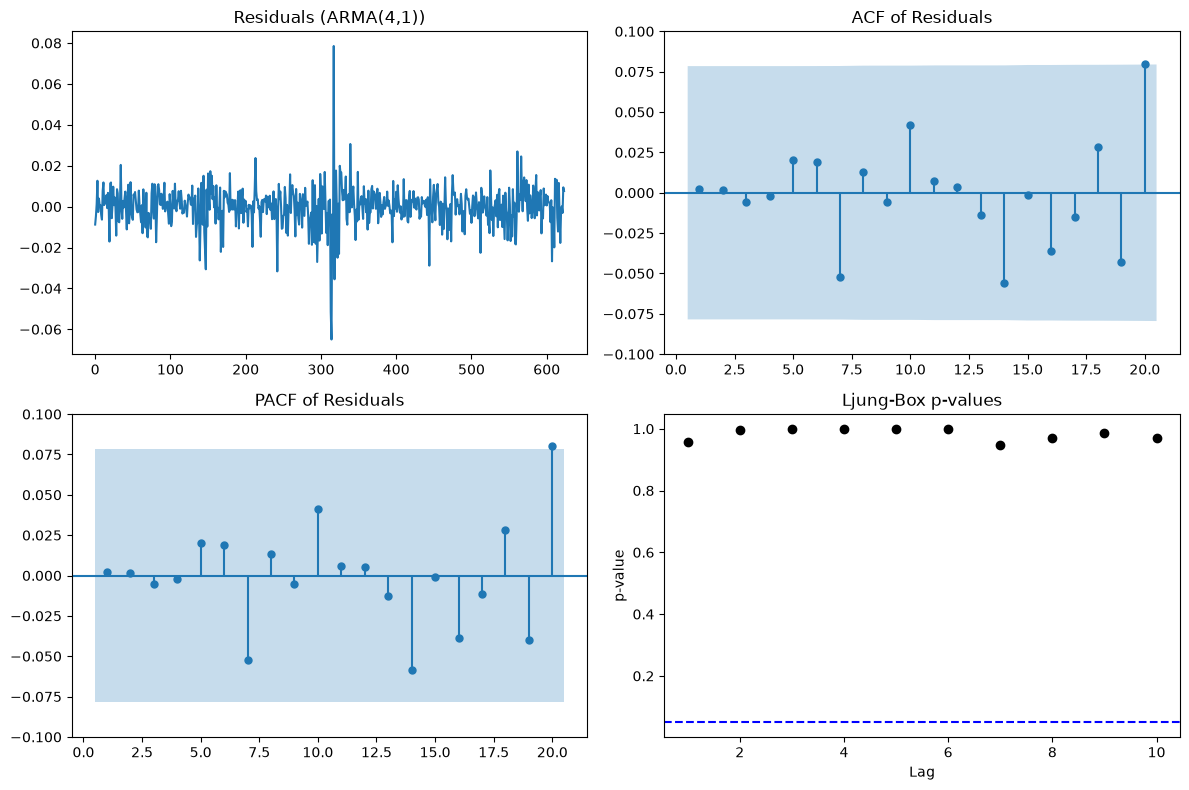

Testing ARMA(4, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(4, 0, 2)   Log Likelihood                2007.384
Date:                Mon, 16 Nov 2026   AIC                          -3998.769
Time:                        17:31:24   BIC                          -3963.279
Sample:                             0   HQIC                         -3984.978
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.772      0.076   -7.73e-05       0.002
ar.L1          0.0599      0.494      0.121      0.903      -0.909       1.029
ar.L2         -0.1929      0.305 

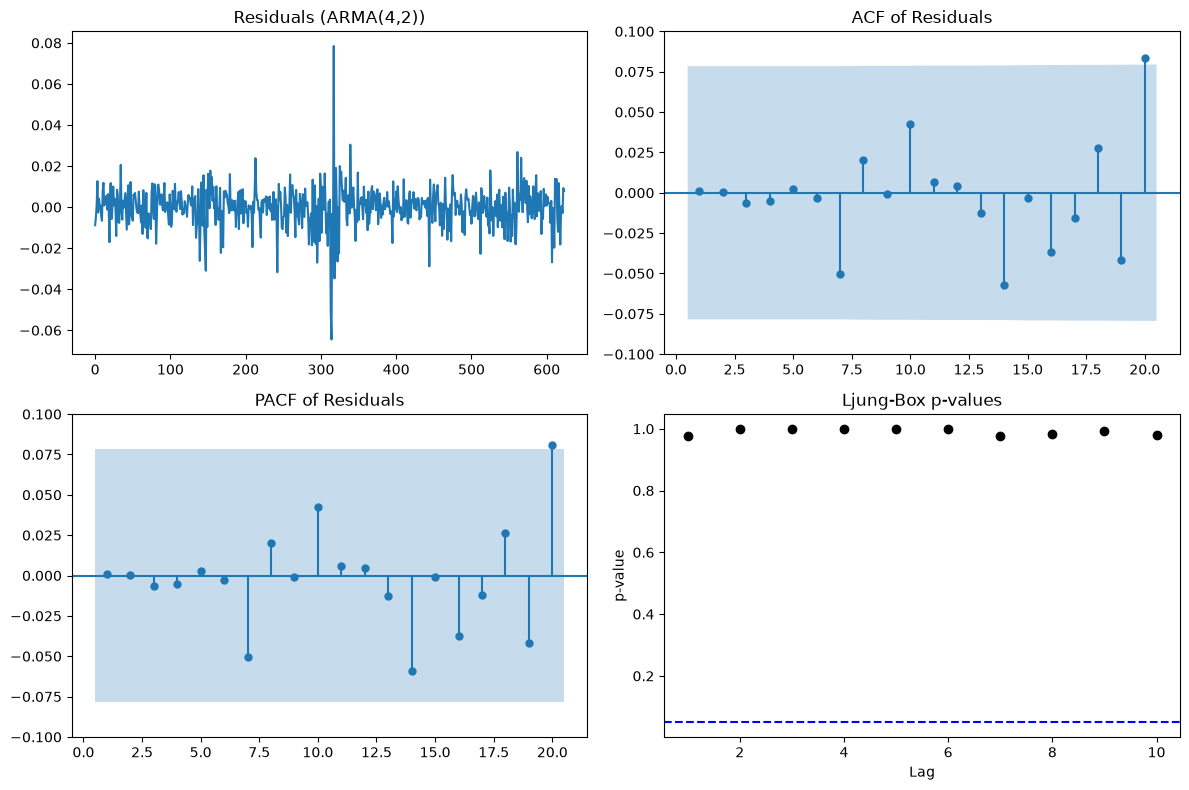

Testing ARMA(4, 3)


c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(4, 0, 3)   Log Likelihood                2007.318
Date:                Mon, 16 Nov 2026   AIC                          -3996.636
Time:                        17:31:25   BIC                          -3956.710
Sample:                             0   HQIC                         -3981.121
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.833      0.067   -5.02e-05       0.002
ar.L1         -0.0283      0.778     -0.036      0.971      -1.553       1.496
ar.L2          0.0196      0.494      0.040      0.9

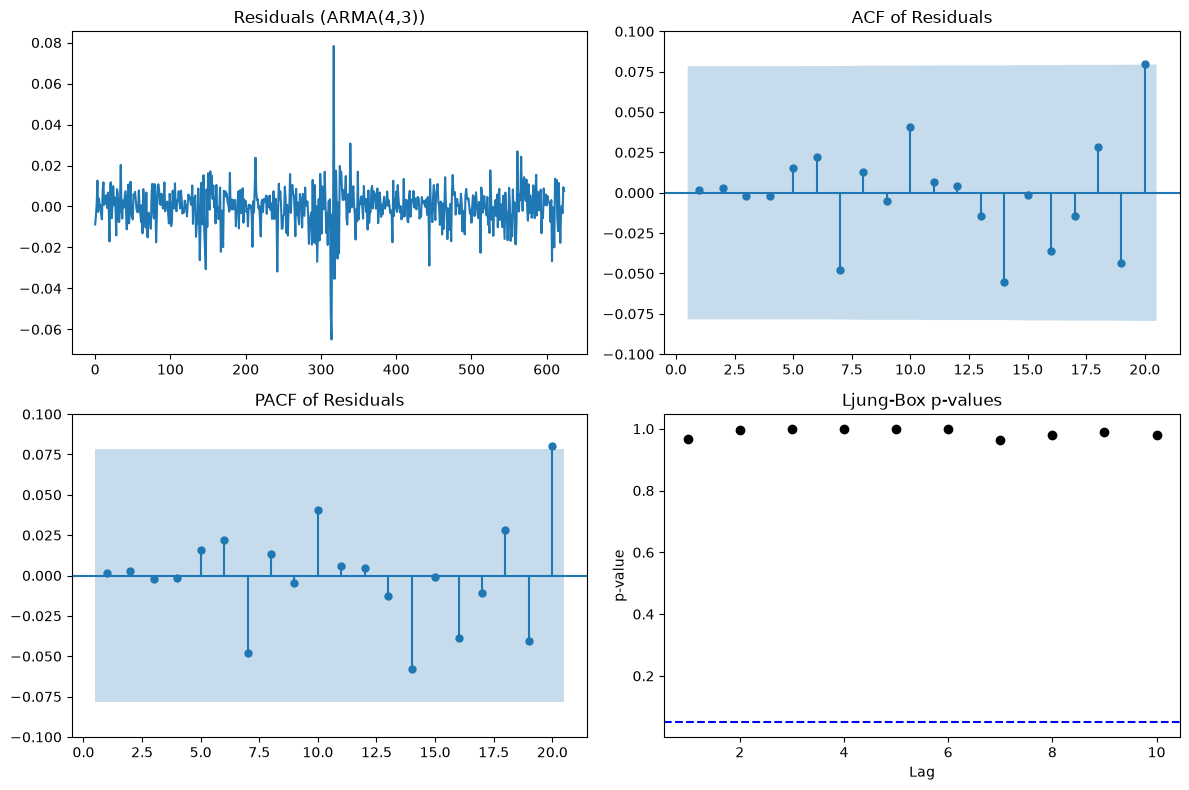

Testing ARMA(4, 4)


c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  624
Model:                 ARIMA(4, 0, 4)   Log Likelihood                2007.416
Date:                Mon, 16 Nov 2026   AIC                          -3994.832
Time:                        17:31:27   BIC                          -3950.470
Sample:                             0   HQIC                         -3977.593
                                - 624                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.000      1.853      0.064   -4.21e-05       0.002
ar.L1         -0.0297      1.922     -0.015      0.988      -3.797       3.738
ar.L2          0.0222      1.033      0.022      0.9

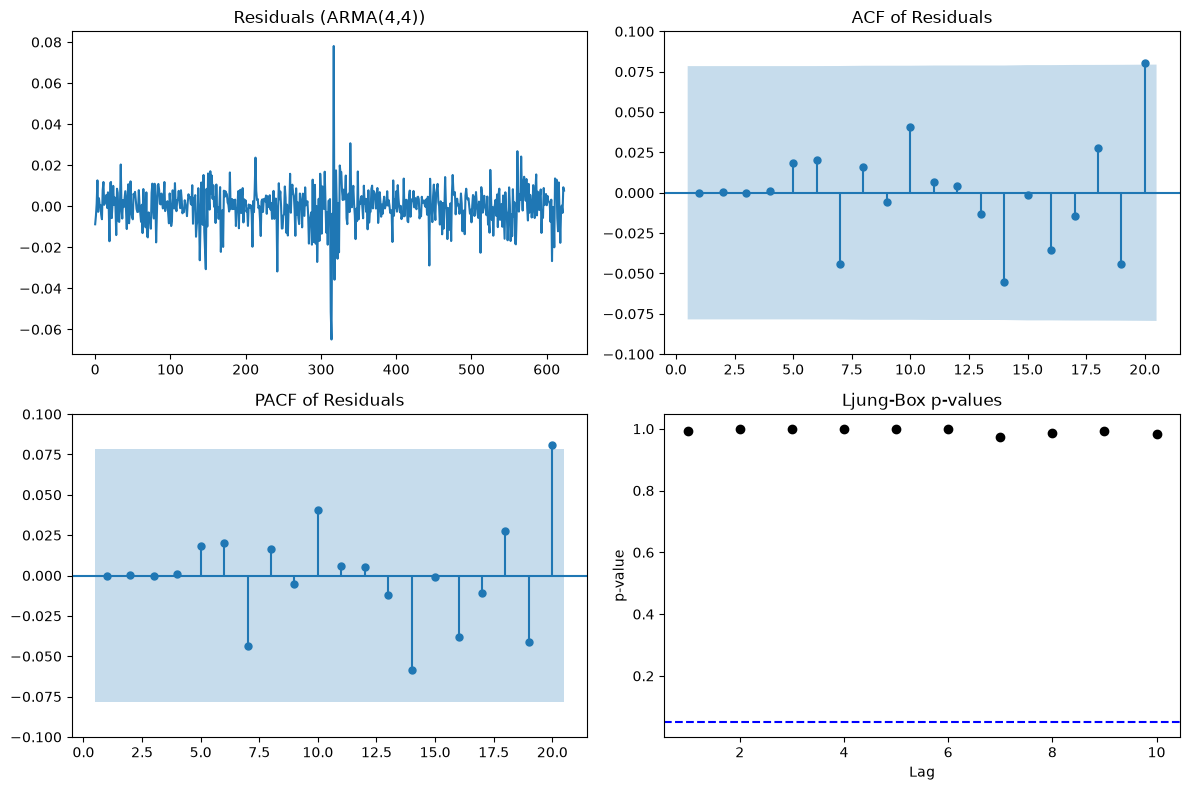


===== Summary =====
Lowest AIC overall: ARMA(0, 4)  AIC = -4003.112
Lowest BIC overall: ARMA(0, 0)  BIC = -3987.420
Lowest AIC (adequate only): ARMA(0, 4)  AIC = -4003.112
Lowest BIC (adequate only): ARMA(0, 3)  BIC = -3979.247


,order,AIC,BIC,adequate
0,"(0, 0, 4)",-4003.111686,-3976.494784,True
1,"(4, 0, 0)",-4002.360750,-3975.743848,True
2,"(1, 0, 3)",-4001.713848,-3975.096946,True
3,"(0, 0, 3)",-4001.428153,-3979.247401,True
4,"(2, 0, 3)",-4001.011651,-3969.958599,True
5,"(1, 0, 4)",-4000.904205,-3969.851152,True
6,"(4, 0, 1)",-4000.312976,-3969.259923,True
7,"(3, 0, 0)",-4000.000612,-3977.819860,True
8,"(3, 0, 3)",-3999.785753,-3964.296550,True
9,"(2, 0, 4)",-3999.078284,-3963.589081,True


In [42]:
sp500_arma_results, sp500_best_aic, sp500_best_bic = arma_diagnostics(sp500_log_returns['log_returns'], p_max=4, q_max=4)
sp500_arma_results   # full table, sorted by AIC

## S&P 500 Train

Testing ARMA(0, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                          ARIMA   Log Likelihood                1159.567
Date:                Mon, 16 Nov 2026   AIC                          -2315.135
Time:                        17:31:27   BIC                          -2307.286
Sample:                             0   HQIC                         -2312.019
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.253      0.210      -0.000       0.002
sigma2         0.0001   2.93e-06     40.462      0.000       0.000       0.000
Ljung-Box (L1) (Q):              

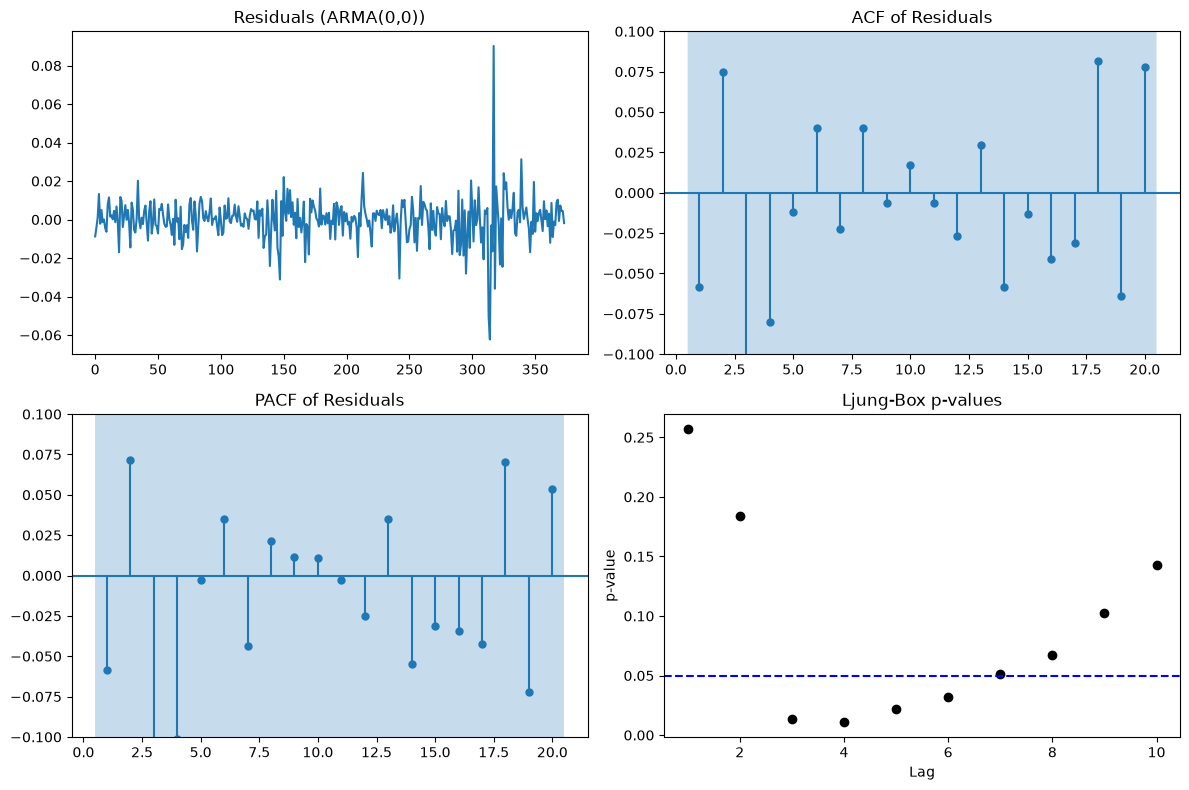

Testing ARMA(0, 1)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(0, 0, 1)   Log Likelihood                1160.122
Date:                Mon, 16 Nov 2026   AIC                          -2314.245
Time:                        17:31:28   BIC                          -2302.472
Sample:                             0   HQIC                         -2309.571
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.268      0.205      -0.000       0.002
ma.L1         -0.0456      0.025     -1.798      0.072      -0.095       0.004
sigma2         0.0001   2.92e-06 

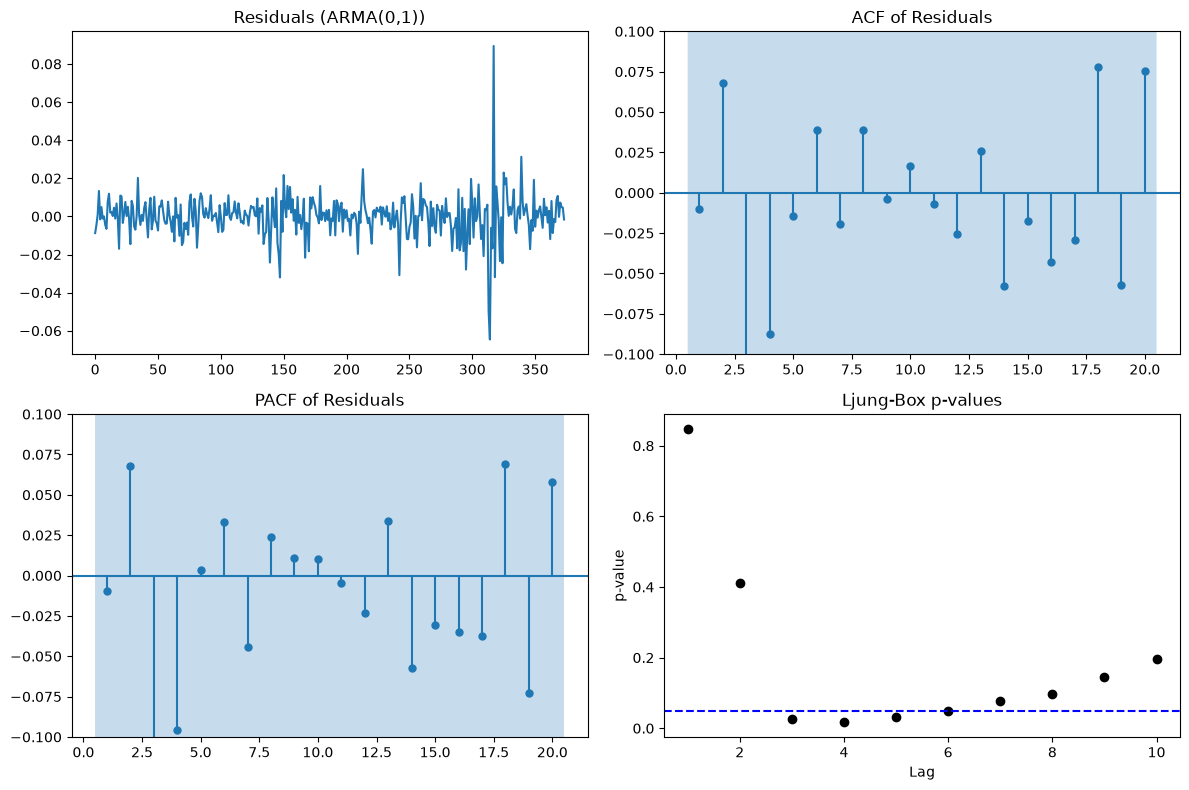

Testing ARMA(0, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(0, 0, 2)   Log Likelihood                1160.888
Date:                Mon, 16 Nov 2026   AIC                          -2313.776
Time:                        17:31:29   BIC                          -2298.079
Sample:                             0   HQIC                         -2307.544
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.199      0.231      -0.000       0.002
ma.L1         -0.0585      0.027     -2.174      0.030      -0.111      -0.006
ma.L2          0.0783      0.057 

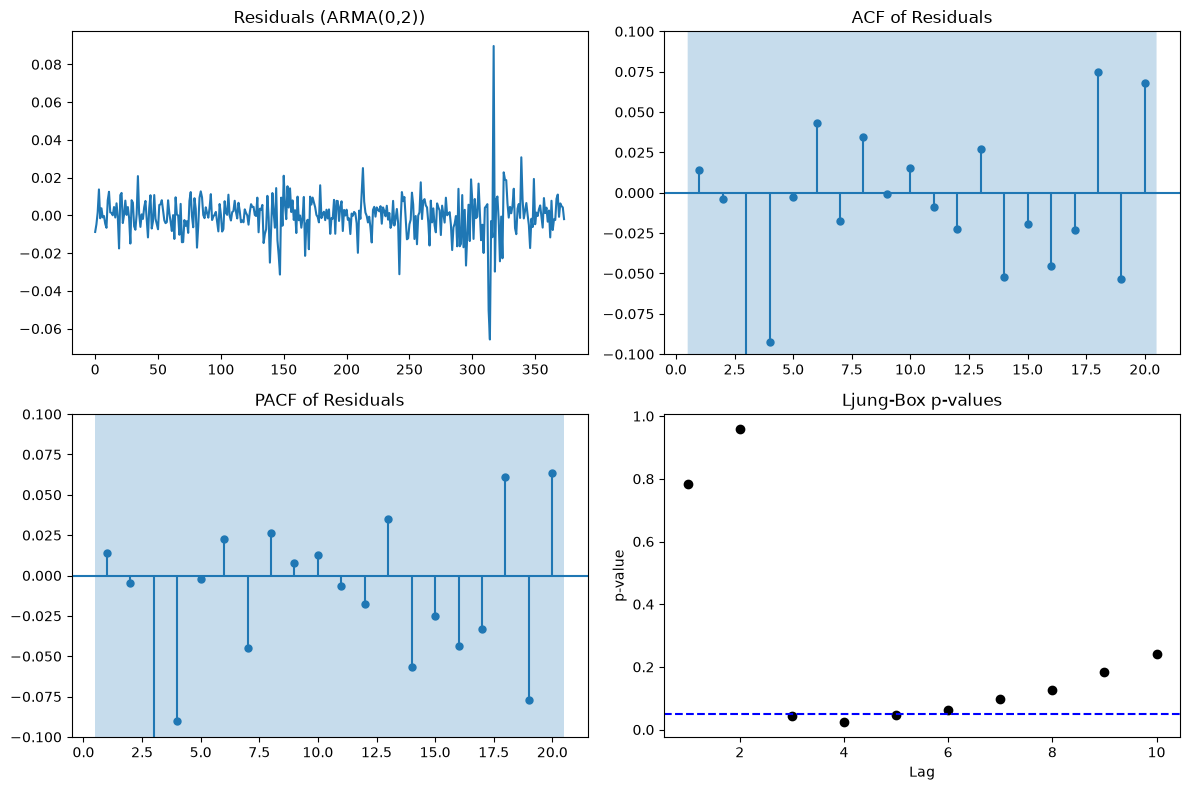

Testing ARMA(0, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(0, 0, 3)   Log Likelihood                1164.904
Date:                Mon, 16 Nov 2026   AIC                          -2319.808
Time:                        17:31:30   BIC                          -2300.187
Sample:                             0   HQIC                         -2312.017
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.228      0.219      -0.000       0.002
ma.L1         -0.0571      0.029     -1.994      0.046      -0.113      -0.001
ma.L2          0.0776      0.046 

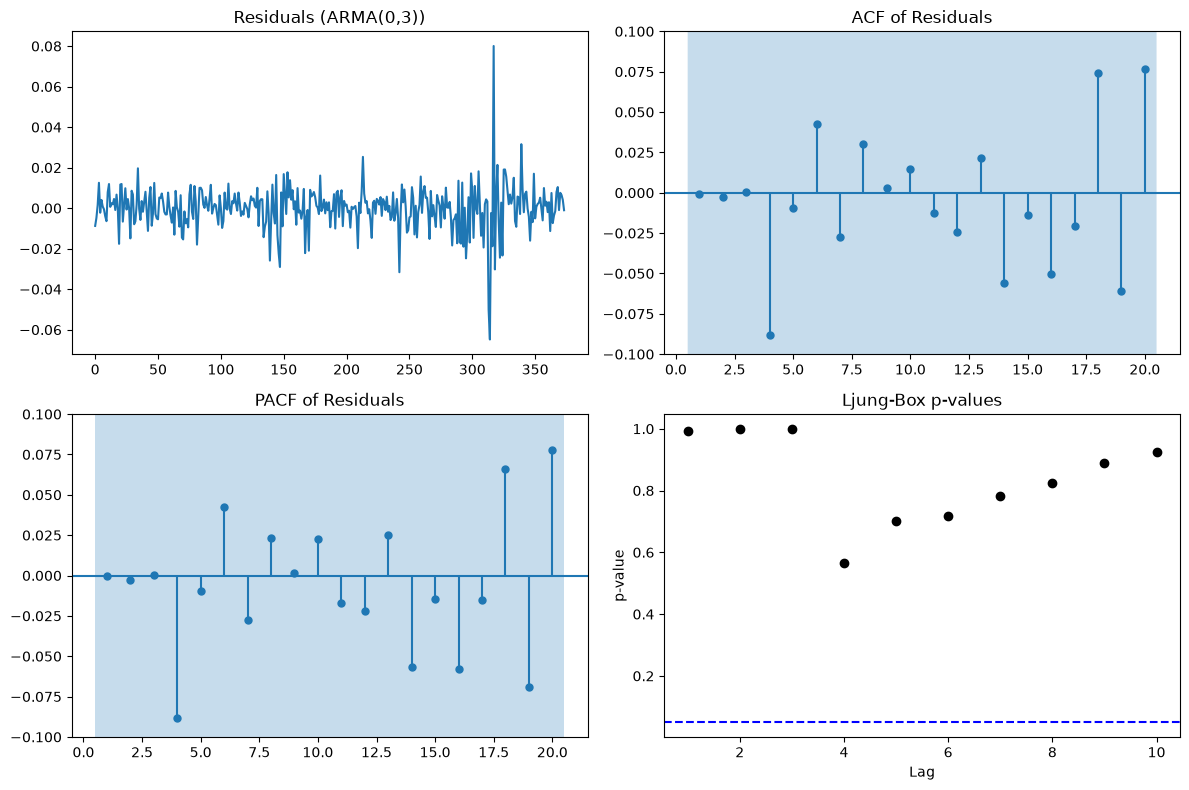

Testing ARMA(0, 4)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(0, 0, 4)   Log Likelihood                1166.504
Date:                Mon, 16 Nov 2026   AIC                          -2321.009
Time:                        17:31:31   BIC                          -2297.463
Sample:                             0   HQIC                         -2311.660
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.219      0.223      -0.000       0.002
ma.L1         -0.0579      0.029     -2.028      0.043      -0.114      -0.002
ma.L2          0.0802      0.046 

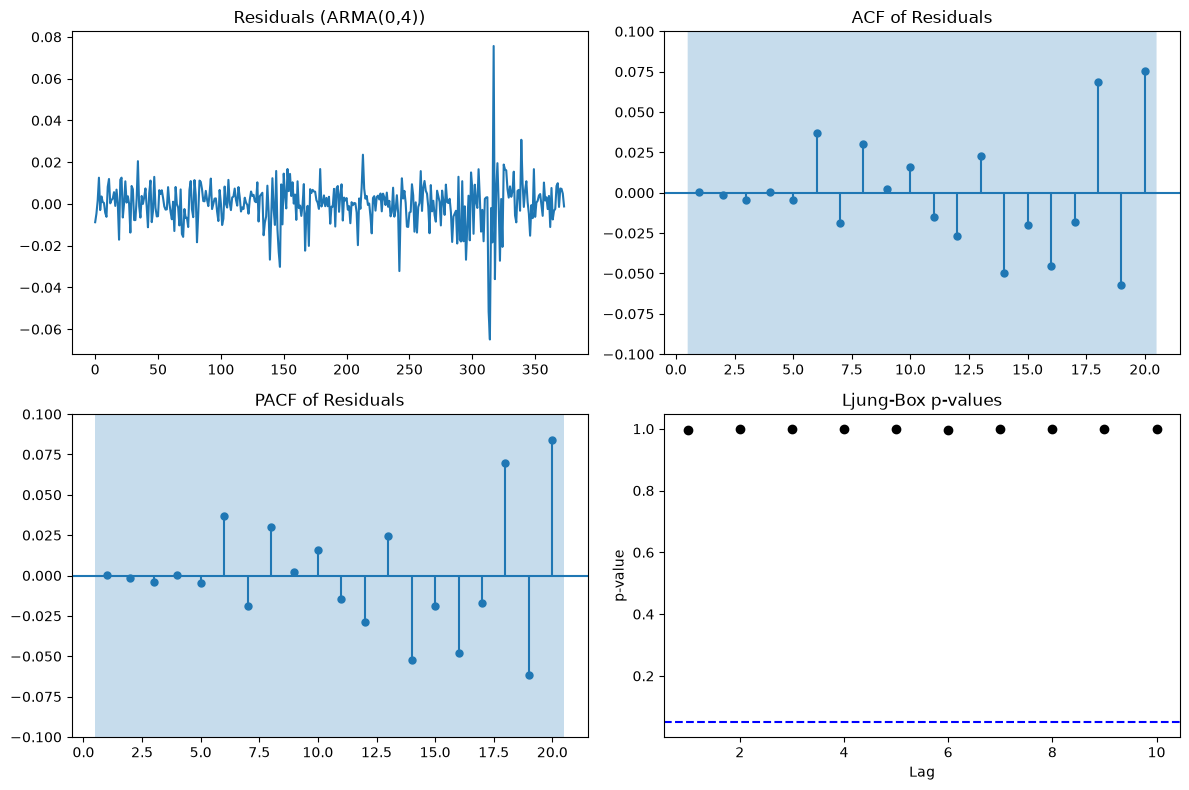

Testing ARMA(1, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(1, 0, 0)   Log Likelihood                1160.205
Date:                Mon, 16 Nov 2026   AIC                          -2314.410
Time:                        17:31:32   BIC                          -2302.637
Sample:                             0   HQIC                         -2309.735
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.280      0.200      -0.000       0.002
ar.L1         -0.0584      0.025     -2.307      0.021      -0.108      -0.009
sigma2         0.0001   2.91e-06 

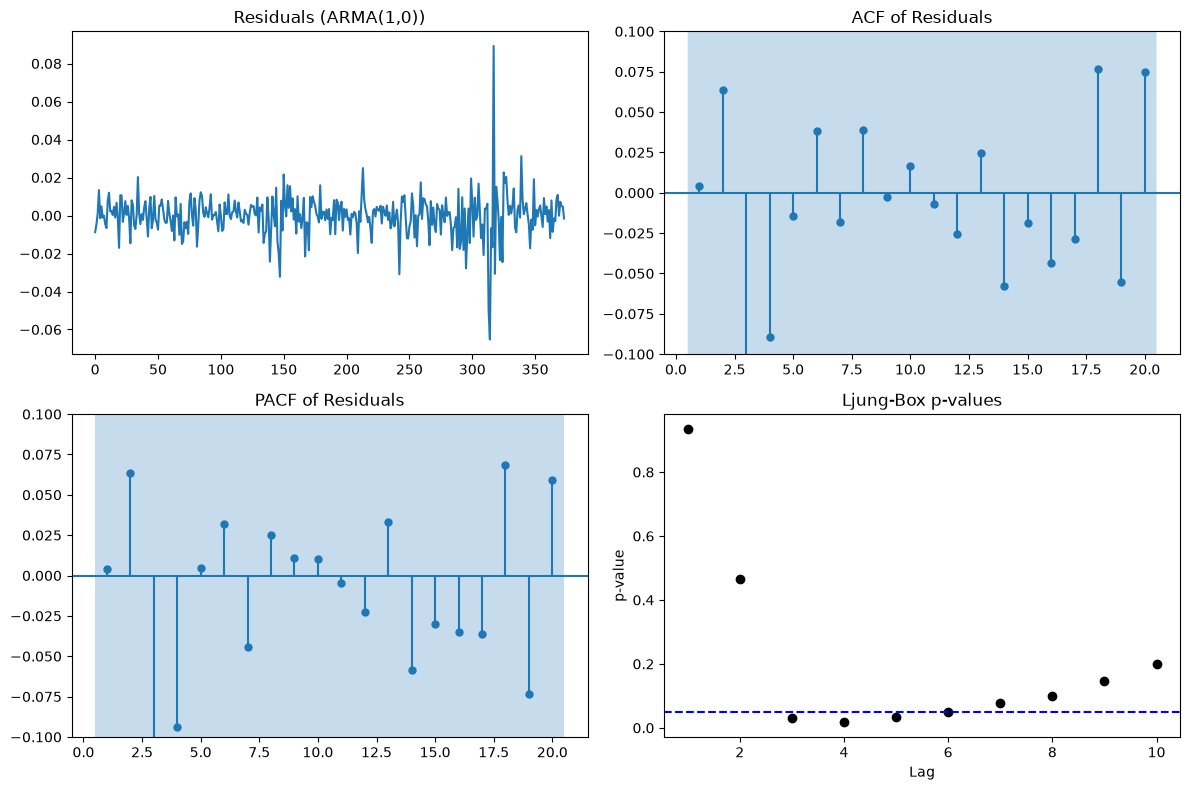

Testing ARMA(1, 1)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(1, 0, 1)   Log Likelihood                1160.164
Date:                Mon, 16 Nov 2026   AIC                          -2312.328
Time:                        17:31:33   BIC                          -2296.631
Sample:                             0   HQIC                         -2306.095
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.254      0.210      -0.000       0.002
ar.L1         -0.0274      0.863     -0.032      0.975      -1.720       1.665
ma.L1         -0.0274      0.869 

c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


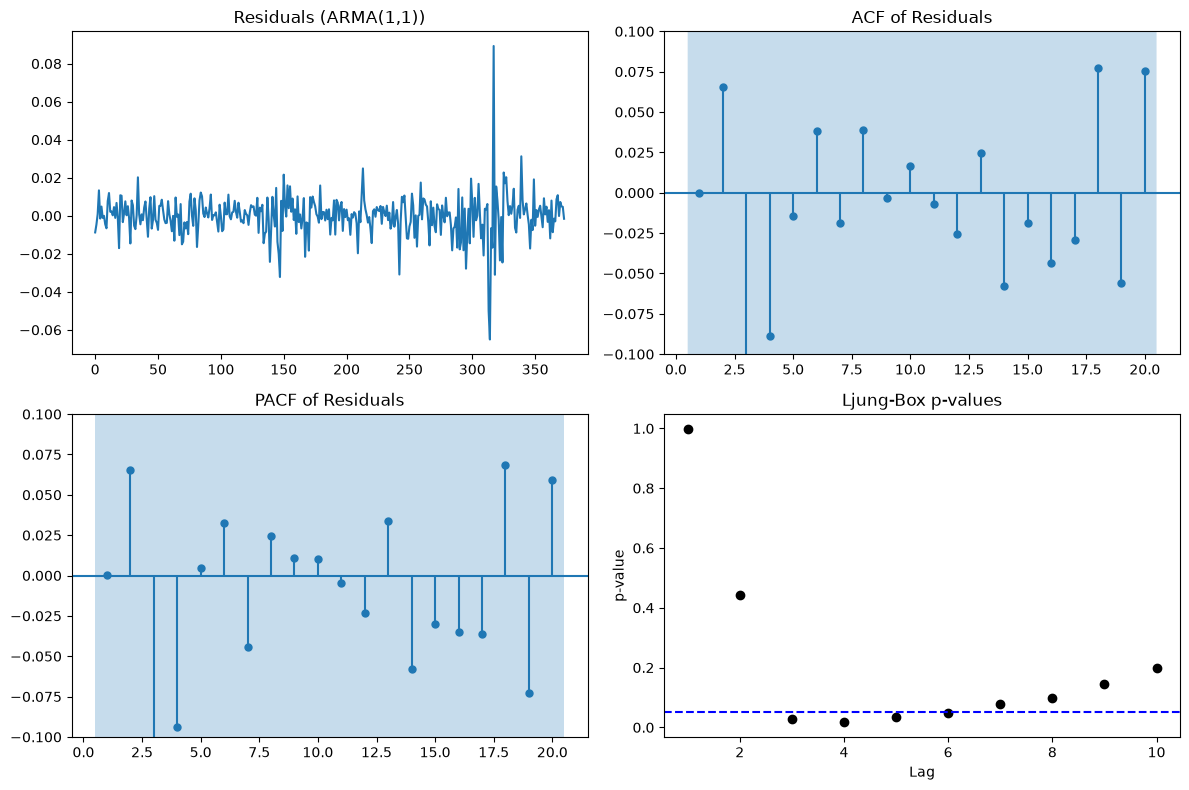

Testing ARMA(1, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(1, 0, 2)   Log Likelihood                1160.595
Date:                Mon, 16 Nov 2026   AIC                          -2311.190
Time:                        17:31:33   BIC                          -2291.569
Sample:                             0   HQIC                         -2303.400
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      0.966      0.334      -0.001       0.002
ar.L1          0.0628      0.475      0.132      0.895      -0.867       0.993
ma.L1         -0.1213      0.480 

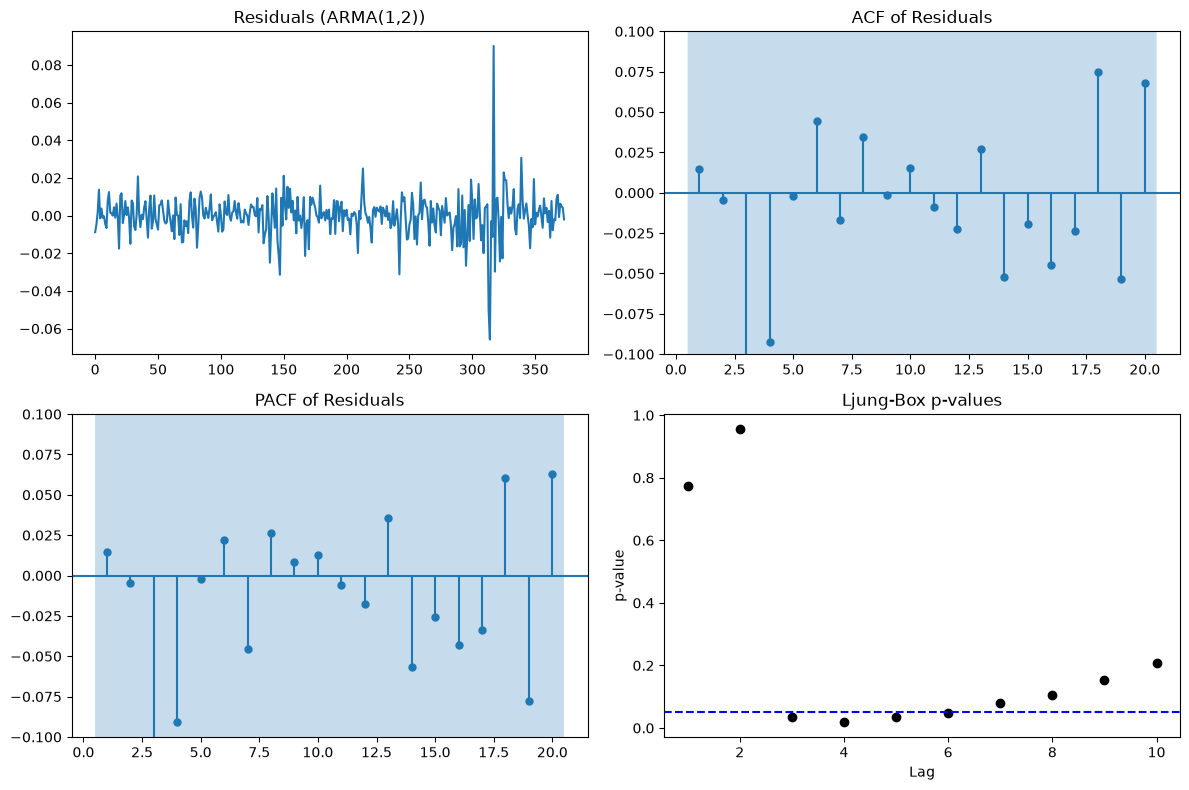

Testing ARMA(1, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(1, 0, 3)   Log Likelihood                1166.040
Date:                Mon, 16 Nov 2026   AIC                          -2320.080
Time:                        17:31:34   BIC                          -2296.534
Sample:                             0   HQIC                         -2310.731
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.244      0.213      -0.000       0.002
ar.L1          0.4115      0.207      1.991      0.046       0.006       0.817
ma.L1         -0.4687      0.215 

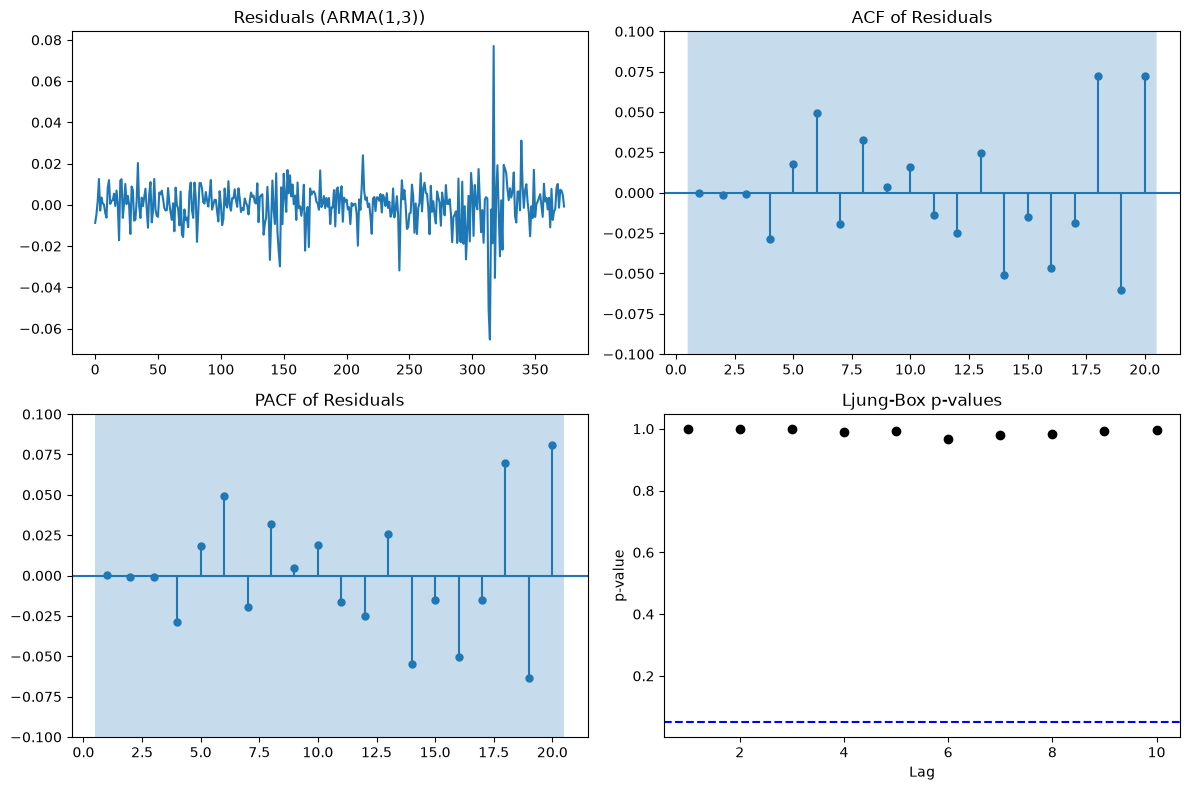

Testing ARMA(1, 4)


c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(1, 0, 4)   Log Likelihood                1166.438
Date:                Mon, 16 Nov 2026   AIC                          -2318.876
Time:                        17:31:35   BIC                          -2291.406
Sample:                             0   HQIC                         -2307.969
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.205      0.228      -0.000       0.002
ar.L1         -0.1675      0.419     -0.400      0.689      -0.988       0.653
ma.L1          0.1096      0.419      0.261      0.7

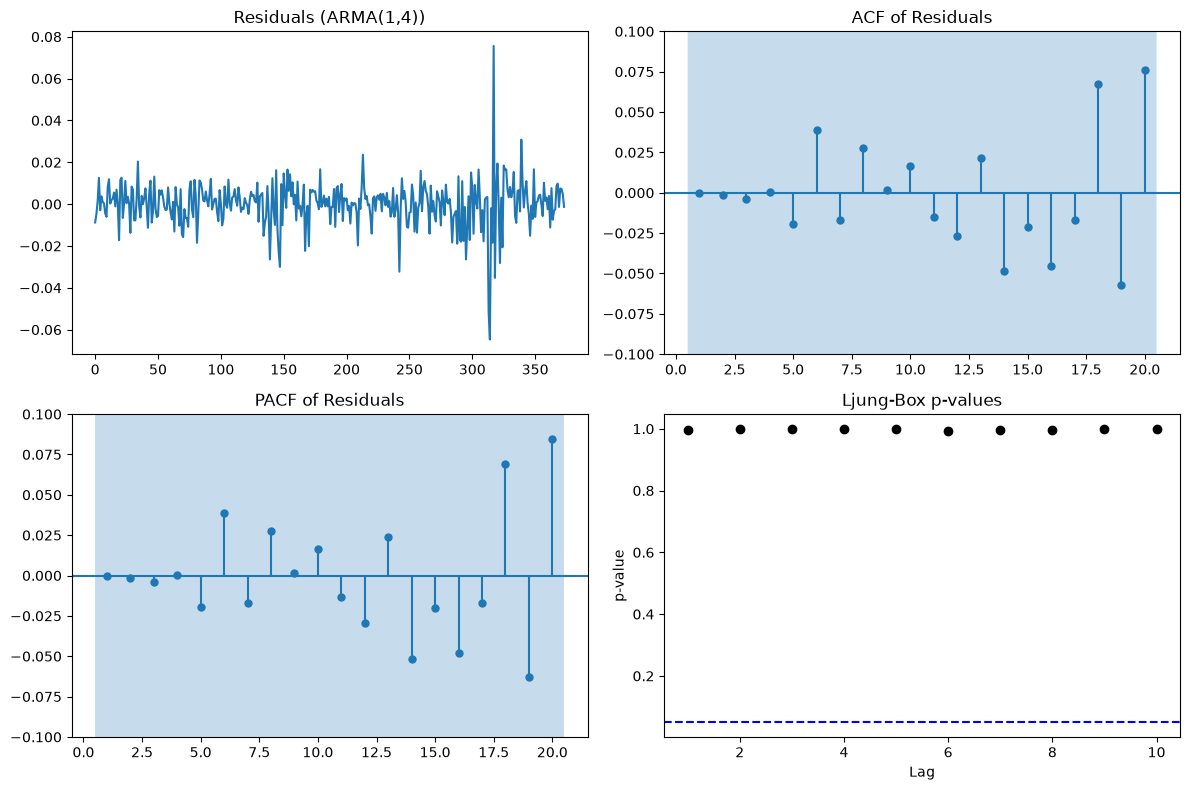

Testing ARMA(2, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(2, 0, 0)   Log Likelihood                1161.157
Date:                Mon, 16 Nov 2026   AIC                          -2314.315
Time:                        17:31:36   BIC                          -2298.618
Sample:                             0   HQIC                         -2308.082
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.168      0.243      -0.000       0.002
ar.L1         -0.0551      0.027     -2.059      0.039      -0.108      -0.003
ar.L2          0.0714      0.057 

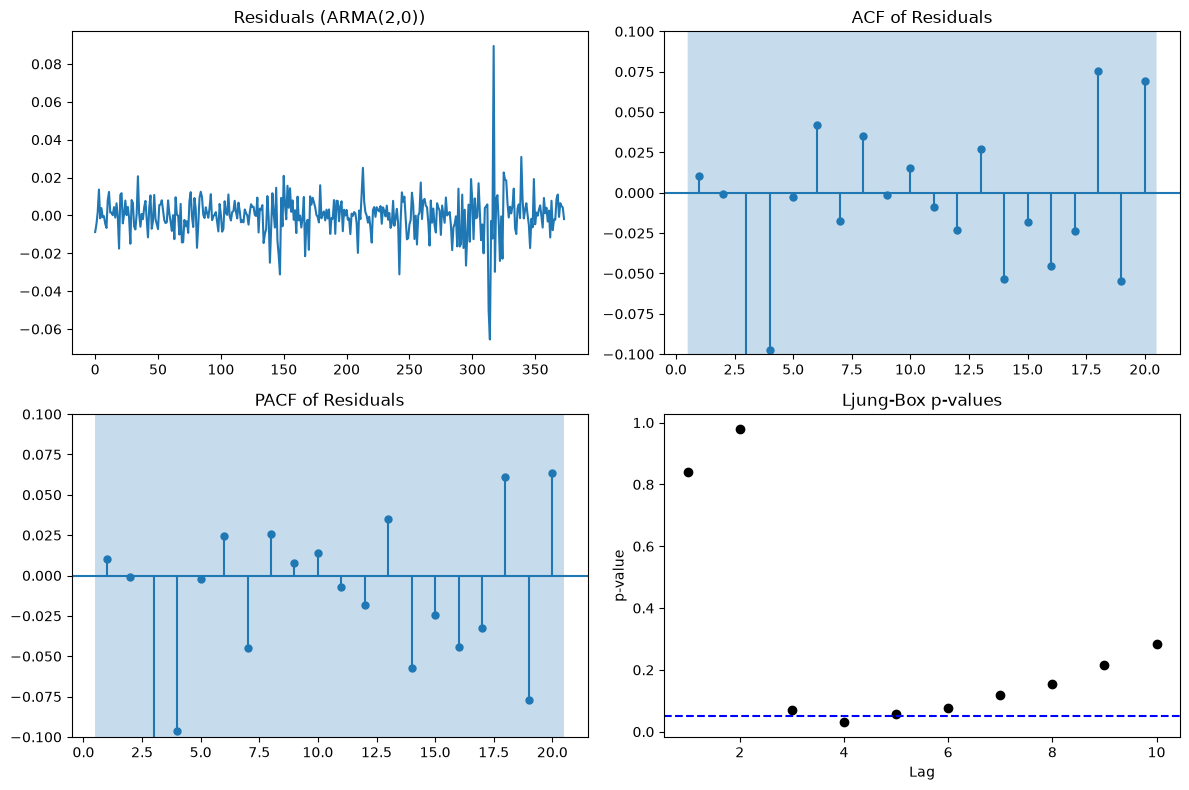

Testing ARMA(2, 1)


c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(2, 0, 1)   Log Likelihood                1162.098
Date:                Mon, 16 Nov 2026   AIC                          -2314.195
Time:                        17:31:37   BIC                          -2294.574
Sample:                             0   HQIC                         -2306.405
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.190      0.234      -0.000       0.002
ar.L1         -0.5057      0.358     -1.412      0.158      -1.208       0.196
ar.L2          0.0629      0.070      0.902      0.3

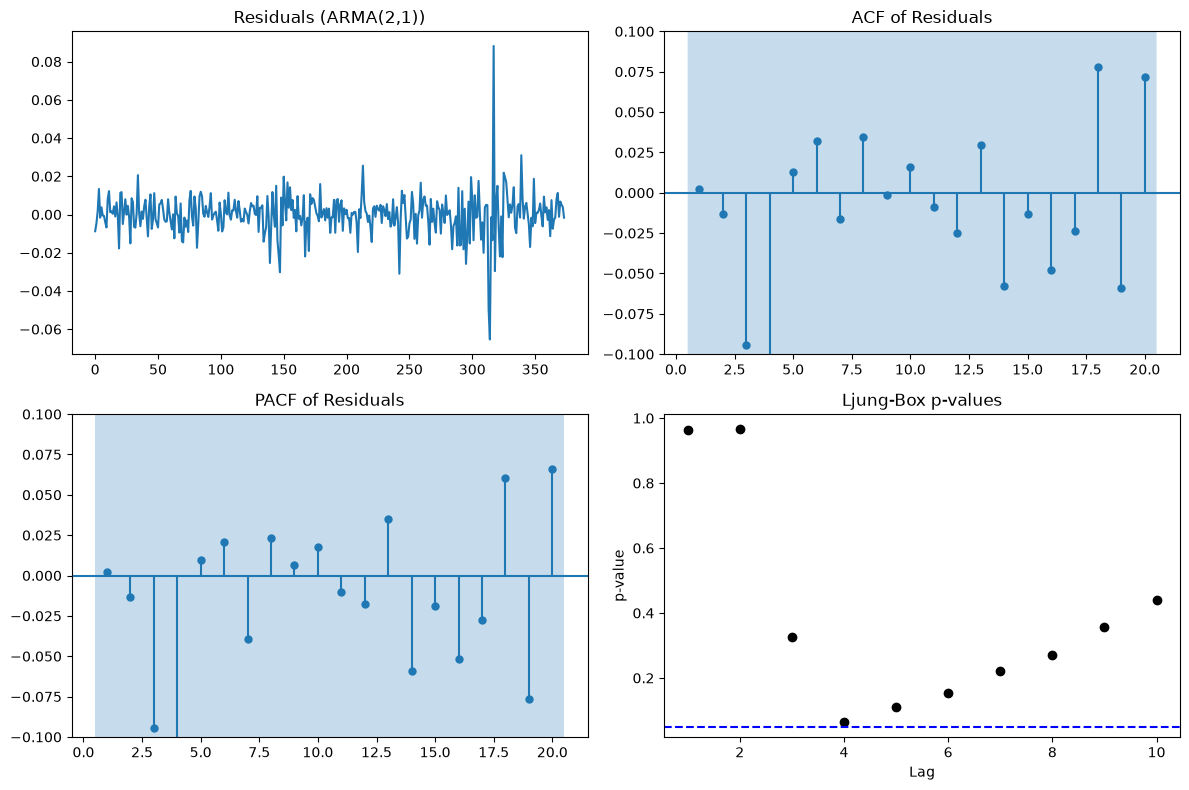

Testing ARMA(2, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(2, 0, 2)   Log Likelihood                1160.594
Date:                Mon, 16 Nov 2026   AIC                          -2309.187
Time:                        17:31:37   BIC                          -2285.642
Sample:                             0   HQIC                         -2299.839
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      0.898      0.369      -0.001       0.002
ar.L1          0.0624      0.474      0.132      0.895      -0.866       0.991
ar.L2         -0.0047      0.572 

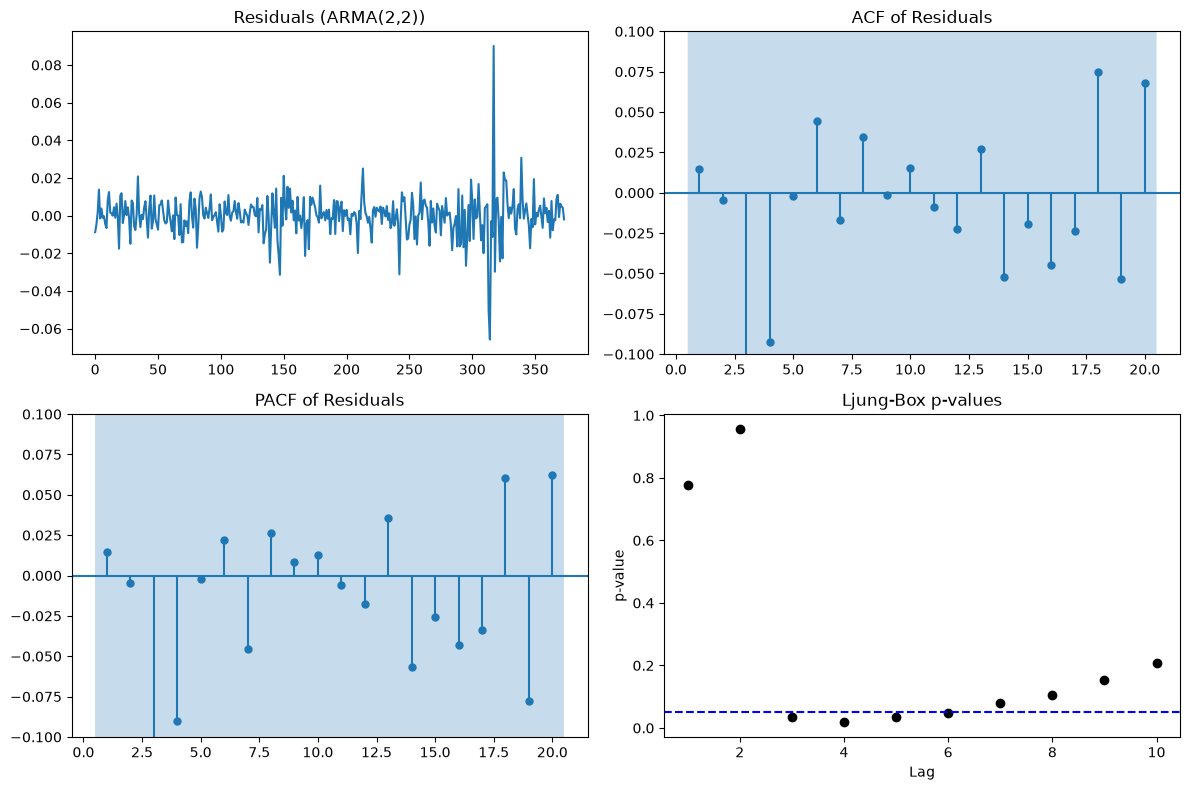

Testing ARMA(2, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(2, 0, 3)   Log Likelihood                1166.599
Date:                Mon, 16 Nov 2026   AIC                          -2319.198
Time:                        17:31:38   BIC                          -2291.728
Sample:                             0   HQIC                         -2308.291
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.216      0.224      -0.000       0.002
ar.L1          0.4313      0.186      2.317      0.021       0.066       0.796
ar.L2         -0.2605      0.258 

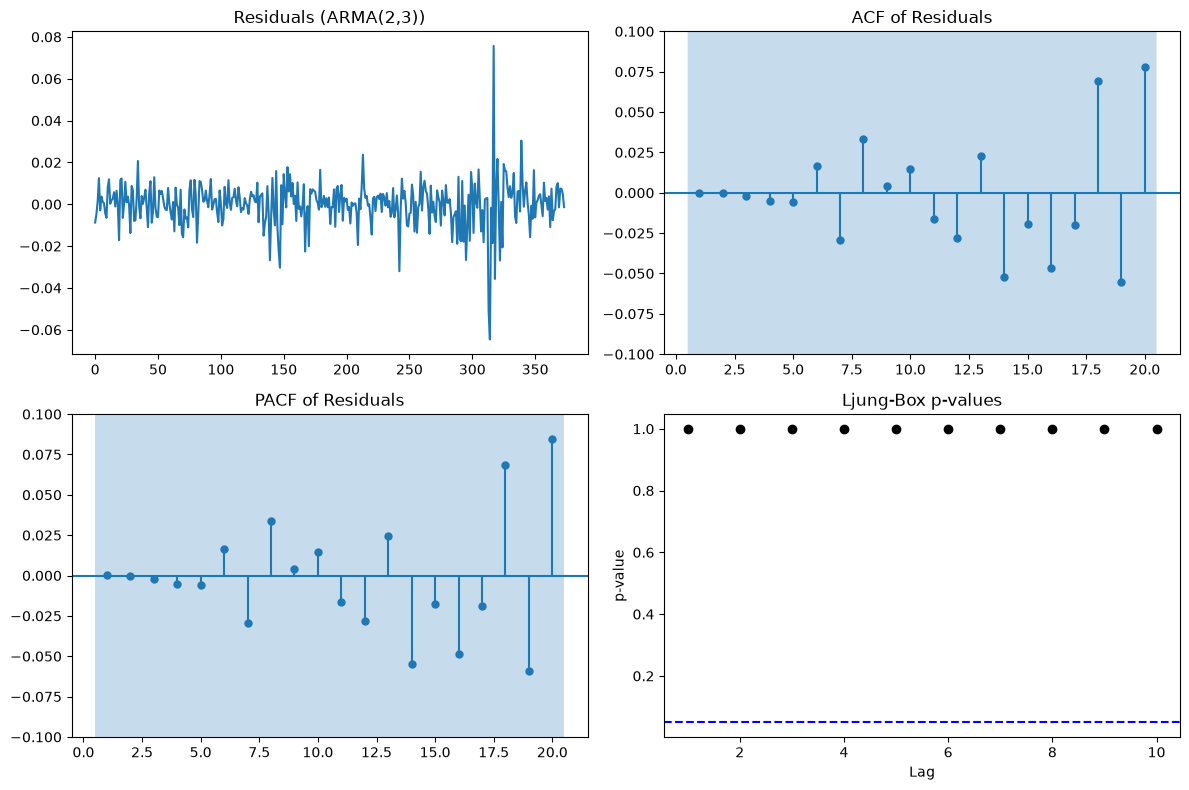

Testing ARMA(2, 4)


c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(2, 0, 4)   Log Likelihood                1166.380
Date:                Mon, 16 Nov 2026   AIC                          -2316.759
Time:                        17:31:39   BIC                          -2285.365
Sample:                             0   HQIC                         -2304.295
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.198      0.231      -0.000       0.002
ar.L1         -0.2063      0.656     -0.315      0.753      -1.492       1.079
ar.L2          0.0422      0.467      0.090      0.9

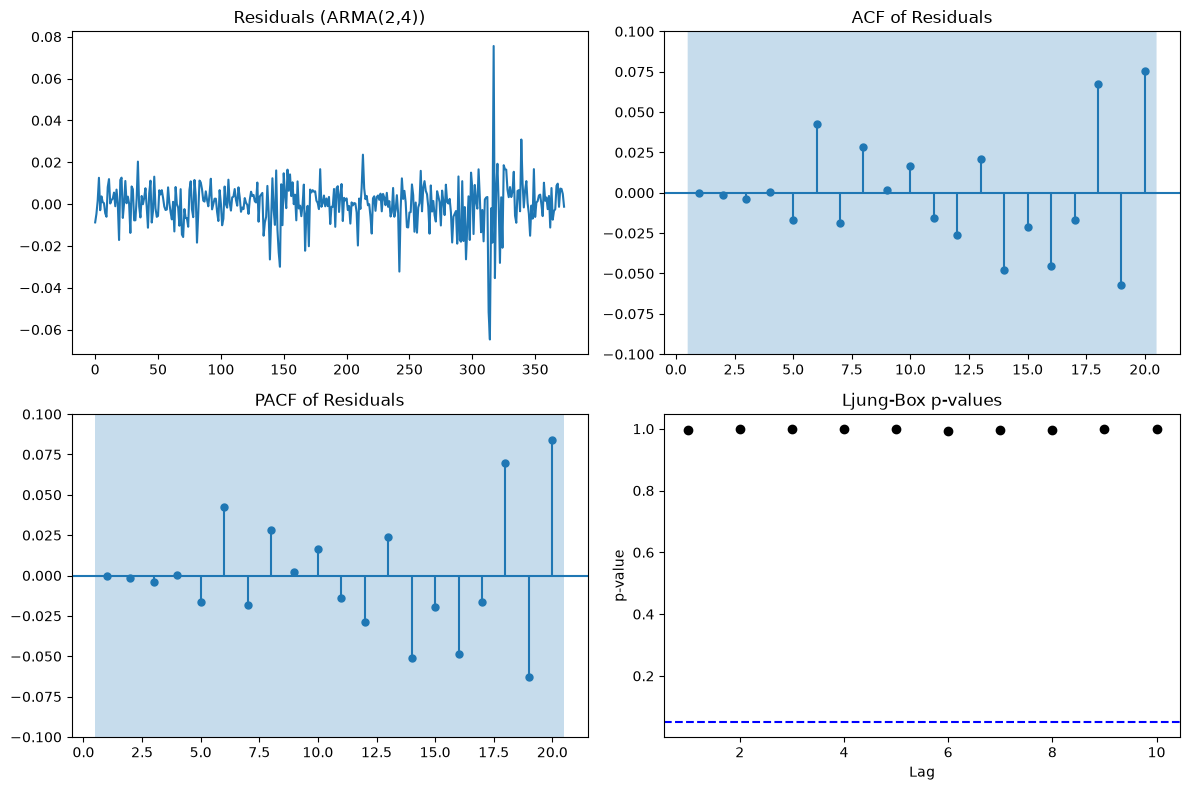

Testing ARMA(3, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(3, 0, 0)   Log Likelihood                1164.392
Date:                Mon, 16 Nov 2026   AIC                          -2318.783
Time:                        17:31:40   BIC                          -2299.162
Sample:                             0   HQIC                         -2310.993
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.253      0.210      -0.000       0.002
ar.L1         -0.0455      0.027     -1.675      0.094      -0.099       0.008
ar.L2          0.0646      0.051 

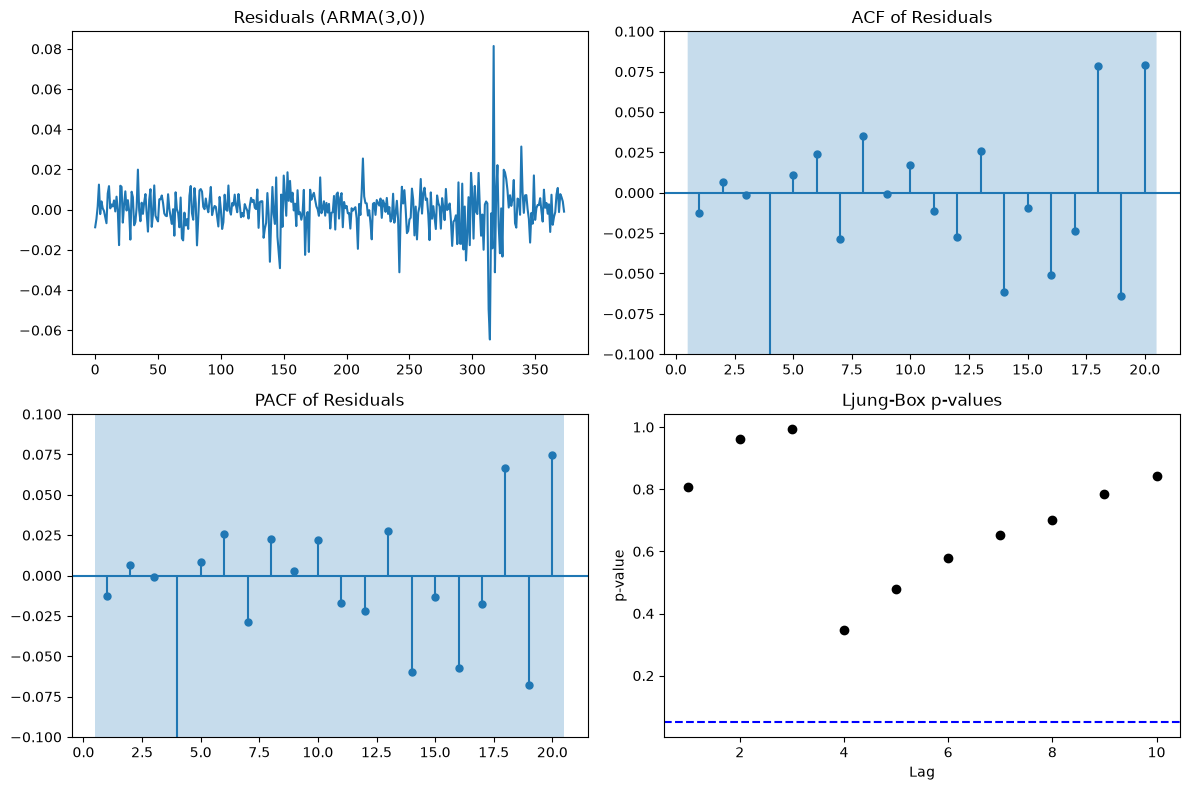

Testing ARMA(3, 1)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(3, 0, 1)   Log Likelihood                1164.472
Date:                Mon, 16 Nov 2026   AIC                          -2316.944
Time:                        17:31:40   BIC                          -2293.398
Sample:                             0   HQIC                         -2307.595
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.084      0.278      -0.001       0.002
ar.L1         -0.0293      0.274     -0.107      0.915      -0.567       0.508
ar.L2          0.0655      0.052 

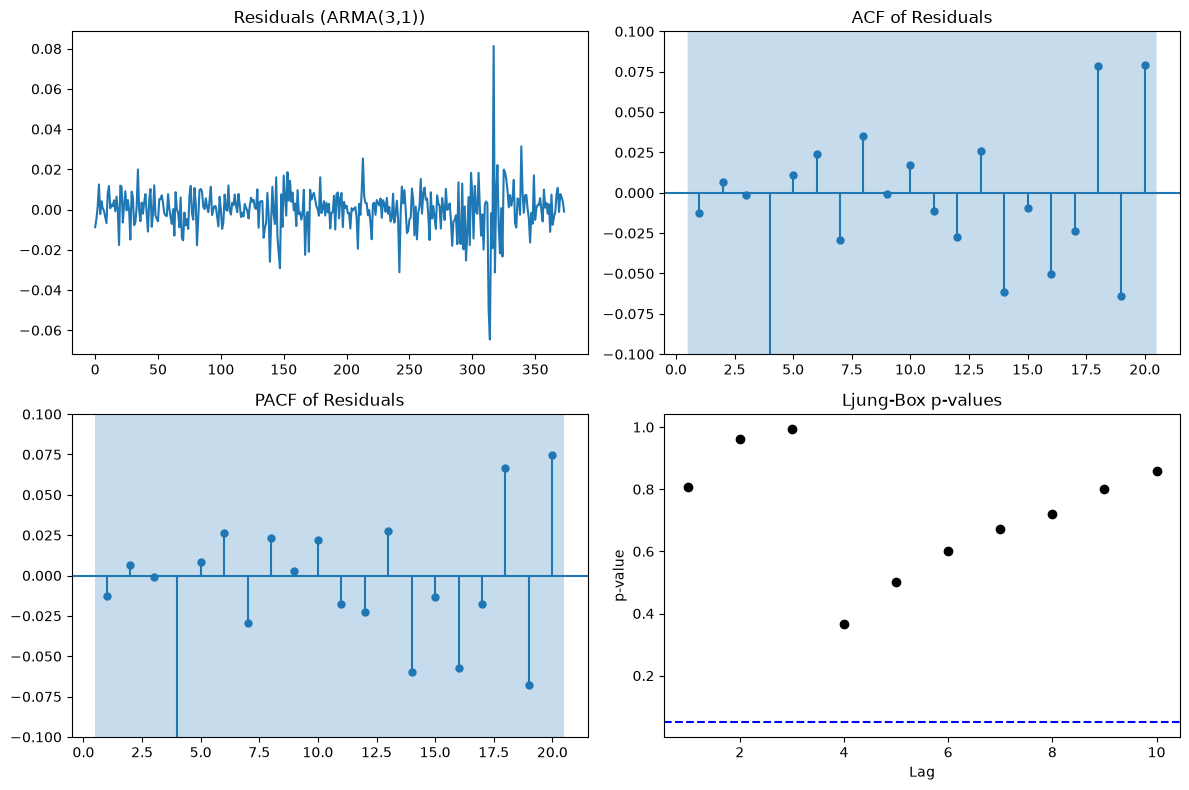

Testing ARMA(3, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(3, 0, 2)   Log Likelihood                1165.983
Date:                Mon, 16 Nov 2026   AIC                          -2317.966
Time:                        17:31:41   BIC                          -2290.496
Sample:                             0   HQIC                         -2307.059
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.238      0.216      -0.000       0.002
ar.L1          0.4943      0.190      2.596      0.009       0.121       0.868
ar.L2         -0.2930      0.241 

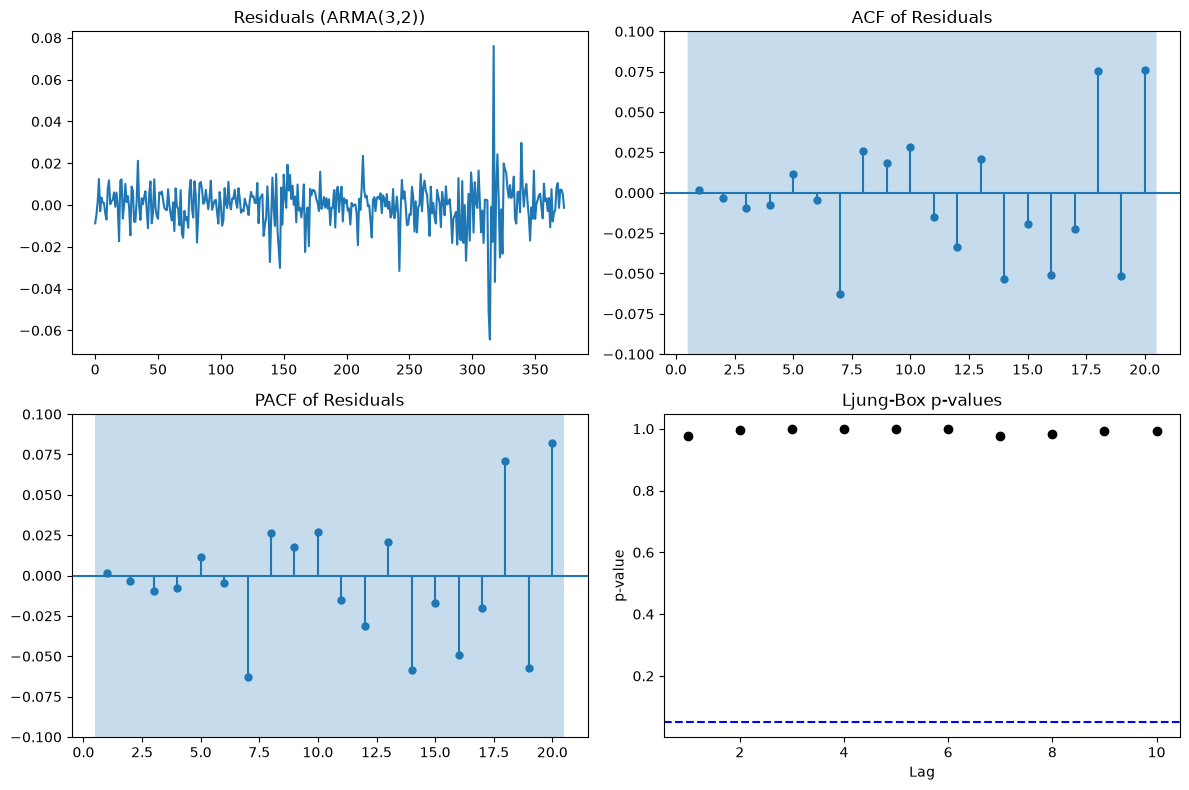

Testing ARMA(3, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(3, 0, 3)   Log Likelihood                1166.618
Date:                Mon, 16 Nov 2026   AIC                          -2317.236
Time:                        17:31:42   BIC                          -2285.841
Sample:                             0   HQIC                         -2304.771
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.195      0.232      -0.000       0.002
ar.L1          0.4314      0.184      2.341      0.019       0.070       0.793
ar.L2         -0.2590      0.262 

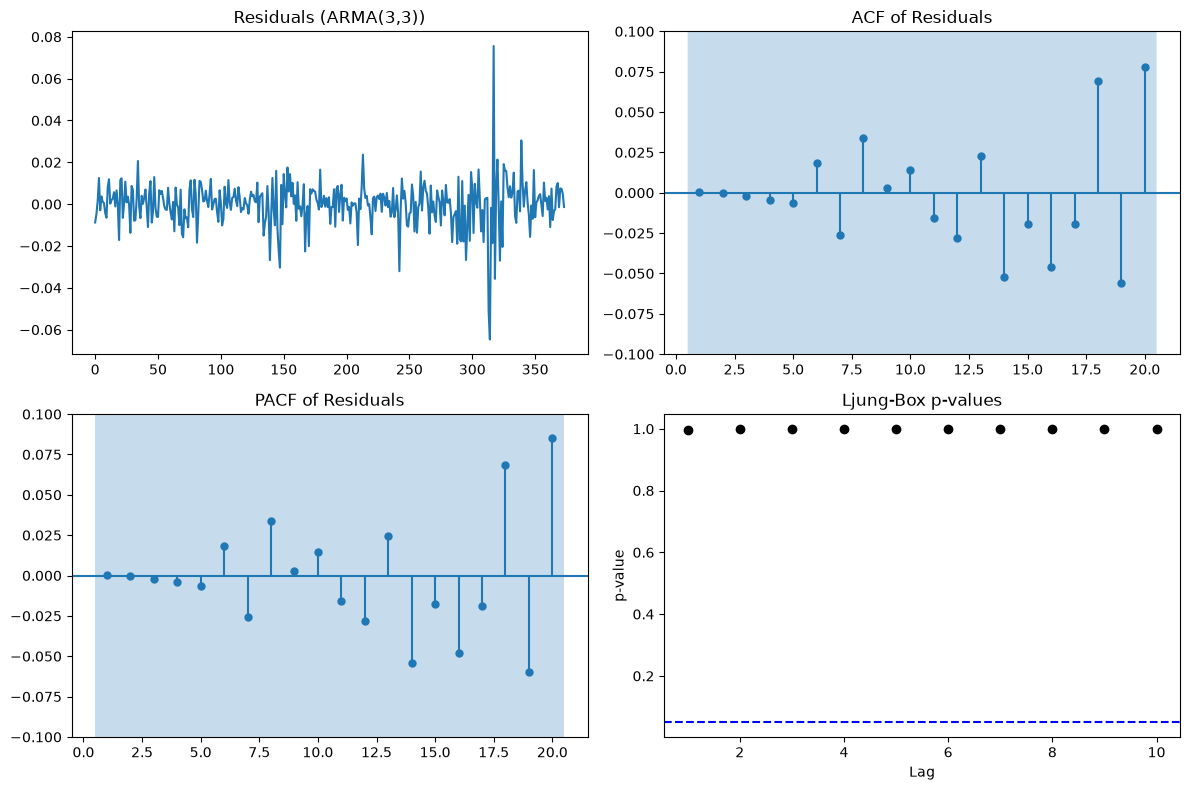

Testing ARMA(3, 4)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(3, 0, 4)   Log Likelihood                1166.569
Date:                Mon, 16 Nov 2026   AIC                          -2315.139
Time:                        17:31:42   BIC                          -2279.821
Sample:                             0   HQIC                         -2301.116
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.162      0.245      -0.000       0.002
ar.L1         -0.3832      3.529     -0.109      0.914      -7.299       6.533
ar.L2          0.0950      1.608 

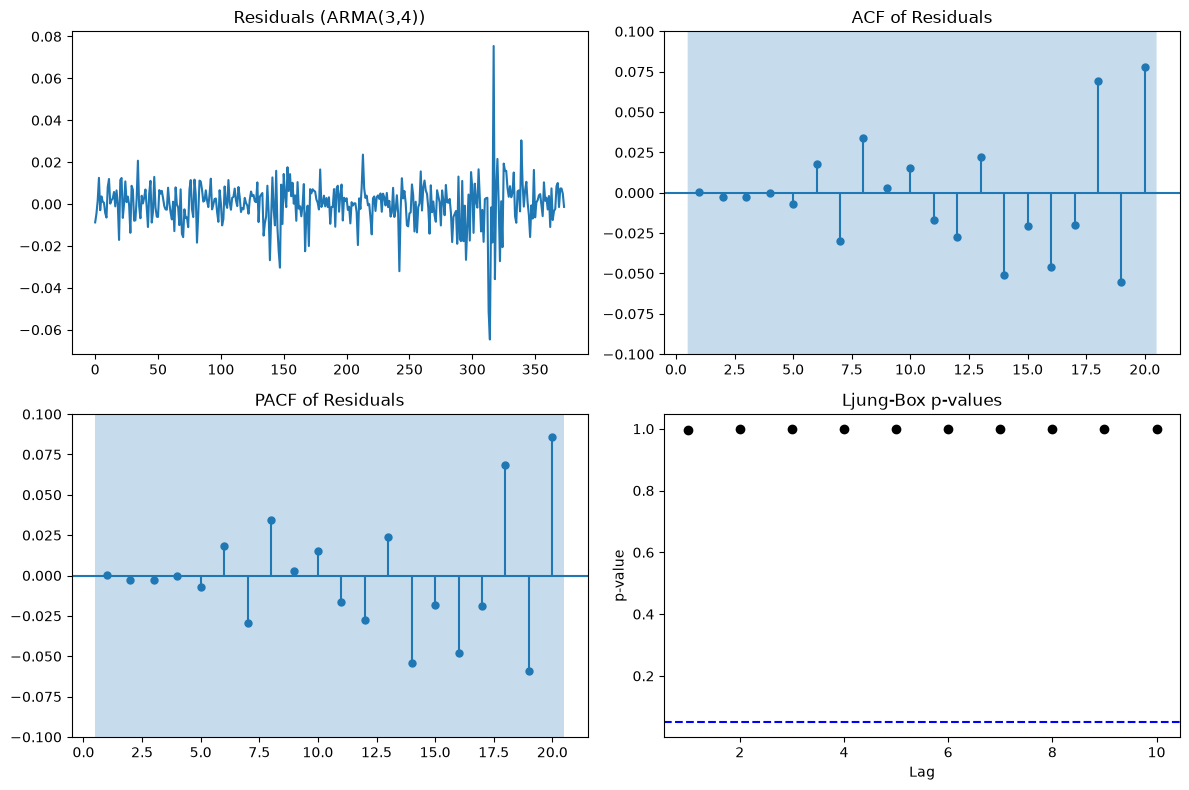

Testing ARMA(4, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(4, 0, 0)   Log Likelihood                1166.332
Date:                Mon, 16 Nov 2026   AIC                          -2320.663
Time:                        17:31:43   BIC                          -2297.117
Sample:                             0   HQIC                         -2311.314
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.184      0.237      -0.000       0.002
ar.L1         -0.0594      0.028     -2.137      0.033      -0.114      -0.005
ar.L2          0.0724      0.052 

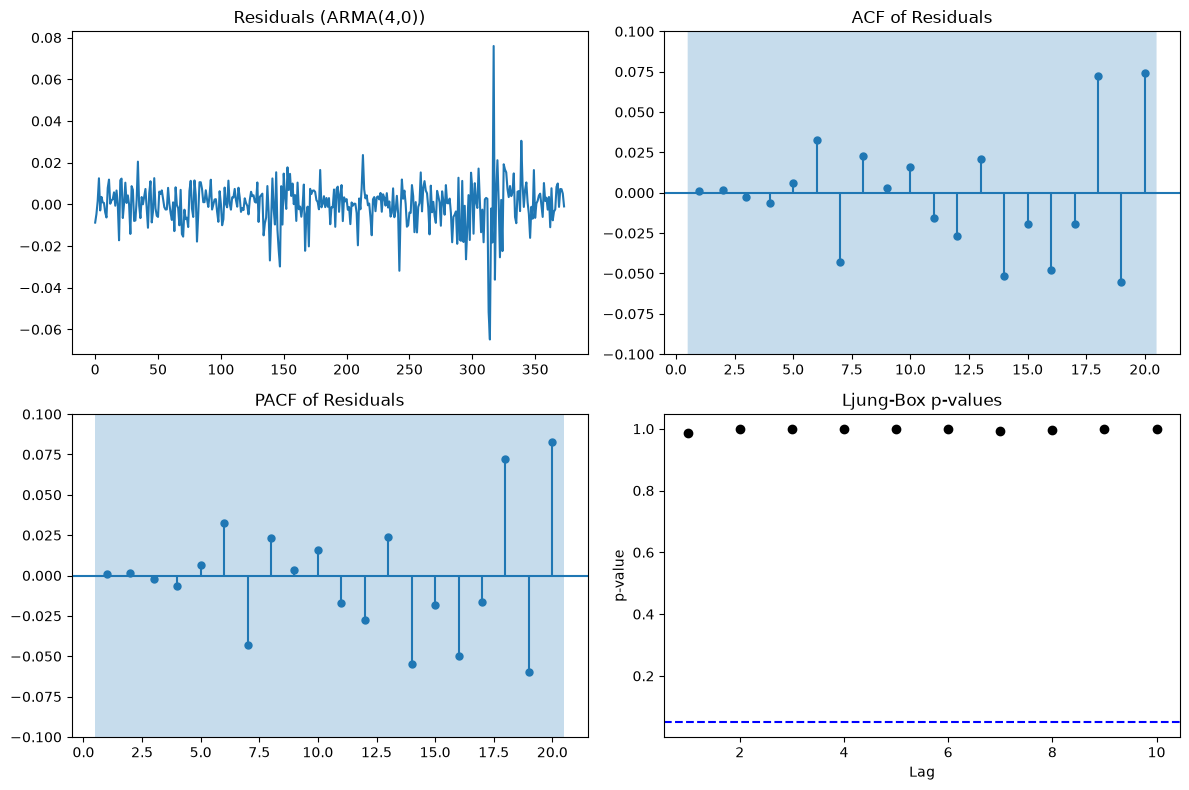

Testing ARMA(4, 1)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(4, 0, 1)   Log Likelihood                1166.331
Date:                Mon, 16 Nov 2026   AIC                          -2318.661
Time:                        17:31:44   BIC                          -2291.191
Sample:                             0   HQIC                         -2307.754
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.188      0.235      -0.000       0.002
ar.L1         -0.0365      0.336     -0.109      0.913      -0.696       0.623
ar.L2          0.0736      0.057 

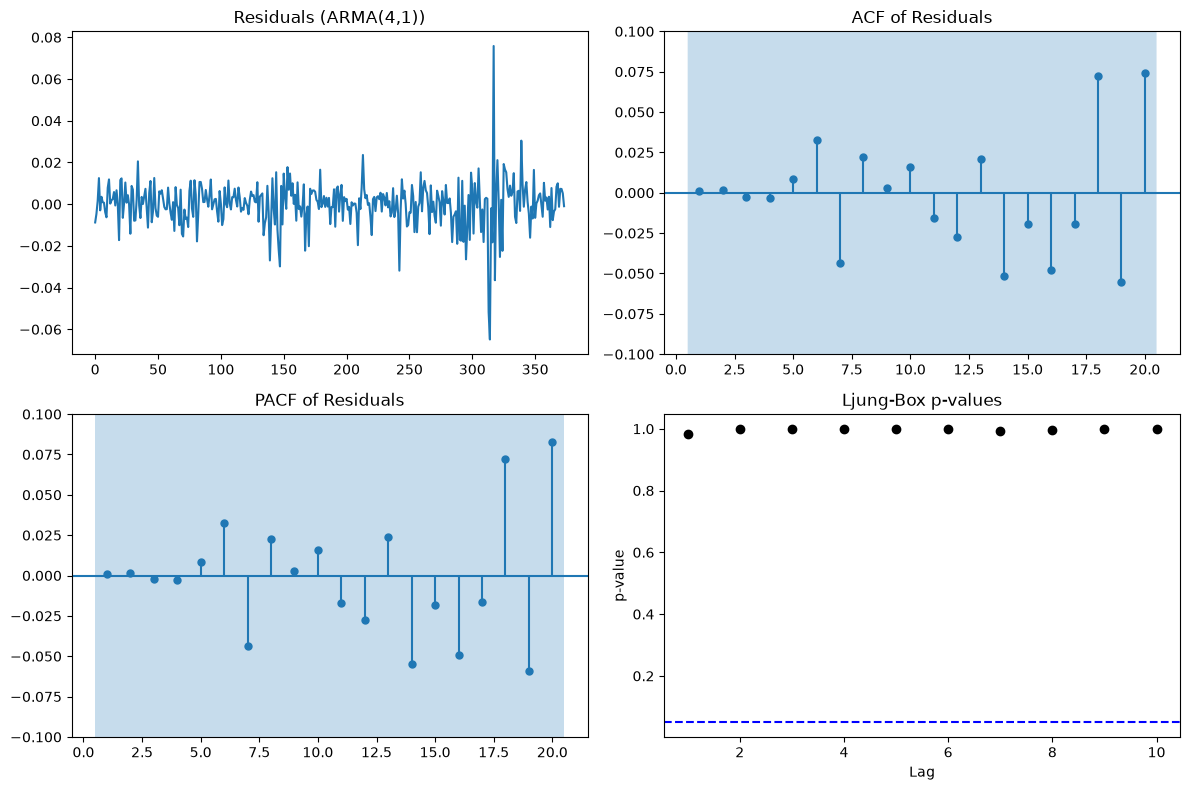

Testing ARMA(4, 2)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(4, 0, 2)   Log Likelihood                1166.142
Date:                Mon, 16 Nov 2026   AIC                          -2316.284
Time:                        17:31:44   BIC                          -2284.890
Sample:                             0   HQIC                         -2303.819
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.153      0.249      -0.000       0.002
ar.L1          0.3976      0.463      0.858      0.391      -0.511       1.306
ar.L2         -0.2449      0.303 

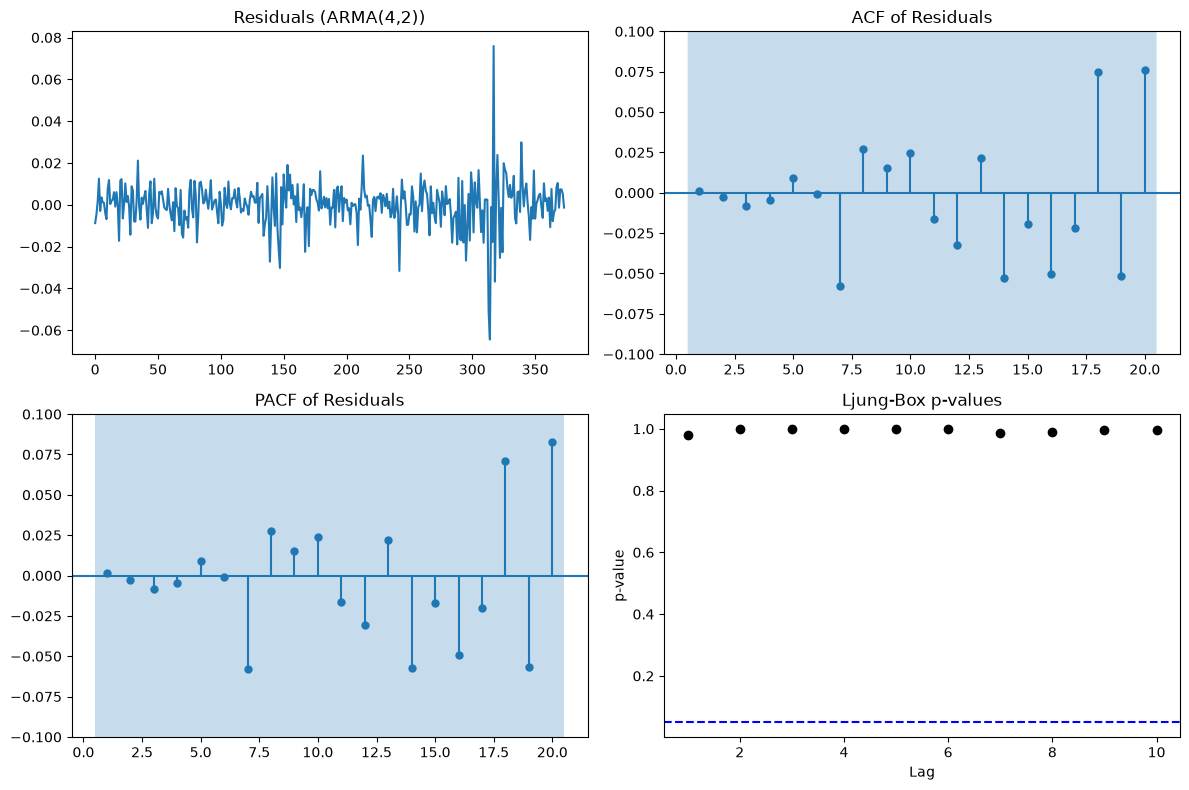

Testing ARMA(4, 3)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(4, 0, 3)   Log Likelihood                1166.363
Date:                Mon, 16 Nov 2026   AIC                          -2314.726
Time:                        17:31:45   BIC                          -2279.408
Sample:                             0   HQIC                         -2300.703
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.148      0.251      -0.001       0.002
ar.L1         -0.1216      0.847     -0.144      0.886      -1.782       1.539
ar.L2          0.0053      0.476 

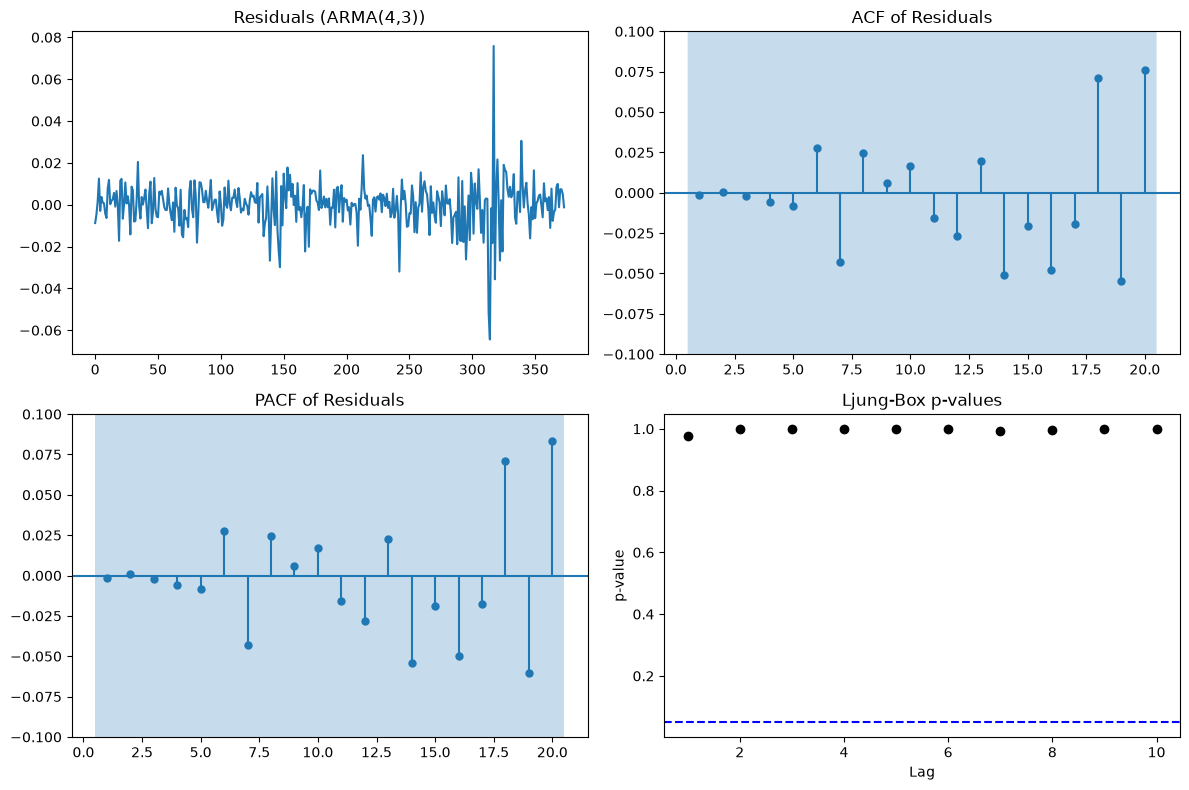

Testing ARMA(4, 4)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  374
Model:                 ARIMA(4, 0, 4)   Log Likelihood                1166.722
Date:                Mon, 16 Nov 2026   AIC                          -2313.445
Time:                        17:31:46   BIC                          -2274.202
Sample:                             0   HQIC                         -2297.864
                                - 374                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0007      0.001      1.165      0.244      -0.000       0.002
ar.L1         -0.3723      1.989     -0.187      0.852      -4.272       3.527
ar.L2          0.0900      0.884 

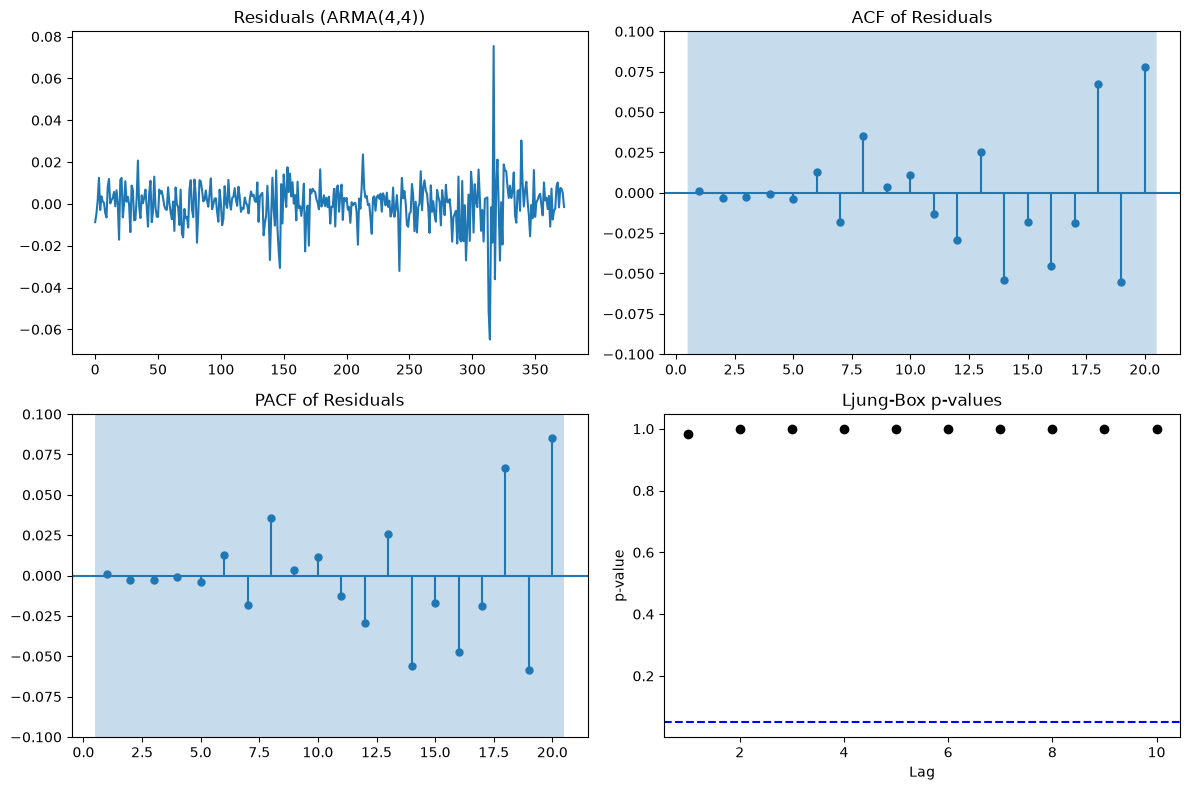


===== Summary =====
Lowest AIC overall: ARMA(0, 4)  AIC = -2321.009
Lowest BIC overall: ARMA(0, 0)  BIC = -2307.286
Lowest AIC (adequate only): ARMA(0, 4)  AIC = -2321.009
Lowest BIC (adequate only): ARMA(0, 3)  BIC = -2300.187


,order,AIC,BIC,adequate
0,"(0, 0, 4)",-2321.008653,-2297.463118,True
1,"(4, 0, 0)",-2320.663016,-2297.117482,True
2,"(1, 0, 3)",-2320.079882,-2296.534347,True
3,"(0, 0, 3)",-2319.807973,-2300.186694,True
4,"(2, 0, 3)",-2319.197791,-2291.728000,True
5,"(1, 0, 4)",-2318.875713,-2291.405922,True
6,"(3, 0, 0)",-2318.783088,-2299.161809,True
7,"(4, 0, 1)",-2318.661013,-2291.191222,True
8,"(3, 0, 2)",-2317.966050,-2290.496259,True
9,"(3, 0, 3)",-2317.235505,-2285.841459,True


In [43]:
sp500_train_arma_results, sp500_train_best_aic, sp500_train_best_bic = arma_diagnostics(sp500_train_lr['log_returns'], p_max=4, q_max=4)
sp500_train_arma_results   # full table, sorted by AIC

In [44]:
res = ARIMA(sp500_train_lr["log_returns"], order=(0, 0, 4)).fit()

print("AR roots:", res.arroots, "| abs:", np.abs(res.arroots))
print("MA roots:", res.maroots, "| abs:", np.abs(res.maroots))

print("Stationary:", np.all(np.abs(res.arroots) > 1))
print("Invertible:", np.all(np.abs(res.maroots) > 1))

AR roots: [] | abs: []
MA roots: [ 1.58391162-0.j         -0.26842126-1.62648002j -0.26842126+1.62648002j
 -2.66023217-0.j        ] | abs: [1.58391162 1.64848028 1.64848028 2.66023217]
Stationary: True
Invertible: True


# Fitting ARMA-GARCH model into each asset

In [45]:
# Error functions
def mae_voliatility(conditional_vol, log_returns_vol):
    return np.mean(
    np.abs(conditional_vol.dropna() - log_returns_vol)
)

def mape_voliatility(conditional_vol, log_returns_vol):
    return np.mean(
    np.abs(conditional_vol.dropna() - log_returns_vol) / np.abs(log_returns_vol))

def rmse_volatility(conditional_vol, log_returns_vol):
    return np.sqrt(np.mean((conditional_vol - log_returns_vol) ** 2))

In [46]:
def sarima_garch_fit(log_returns_df, arima_order, sarima_order, garch_order, scale=100):
    y = log_returns_df["log_returns"]

    if sarima_order != (0,0,0,0):
        sarima_fit = SARIMAX(y, order=arima_order, seasonal_order=sarima_order).fit(disp=False)
    else:
        sarima_fit = ARIMA(y, order=arima_order).fit()

    garch_fit = arch_model(
        scale * sarima_fit.resid,
        mean="Zero",
        vol="Garch",
        p=garch_order[0],
        q=garch_order[1]
    ).fit(disp="off")

    print(garch_fit.summary())
    print("Converged:", garch_fit.convergence_flag == 0)

    log_returns_df['log_returns'] = np.asarray(log_returns_df['log_returns']).reshape(-1)
    log_returns_vol = log_returns_df['log_returns'].rolling(window=20).std()

    garch_vol = pd.Series(
        np.asarray(garch_fit.conditional_volatility).reshape(-1) / scale,
        index=y.index
    )


    plt.figure()
    plt.plot(garch_vol, label="Conditional Volatility")
    plt.plot(log_returns_vol, label="Rolling Volatility (20)", alpha=0.5)
    if sarima_order != (0,0,0,0):
        plt.title(f"SARIMA{arima_order}x{sarima_order} + GARCH{garch_order} Conditional Volatility")
    else:
        plt.title(f"ARIMA{arima_order} + GARCH{garch_order} Conditional Volatility")
    plt.xlabel("Time")
    plt.ylabel("Values")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.legend()
    plt.show()

    aligned = pd.concat([log_returns_vol, garch_vol], axis=1).dropna()
    aligned.columns = ["rolling_vol", "garch_vol"]

    mae = mae_voliatility(aligned["garch_vol"], aligned["rolling_vol"])
    print(f"MAE between GARCH volatility and rolling volatility: {mae:.6f}")
    mape = mape_voliatility(aligned["garch_vol"], aligned["rolling_vol"])
    print(f"MAPE between GARCH volatility and rolling volatility: {mape:.6f}")
    rmse = rmse_volatility(aligned["garch_vol"], aligned["rolling_vol"])
    print(f"RMSE between GARCH volatility and rolling volatility: {rmse:.6f}")

    return sarima_fit, garch_fit, mae, mape, rmse

## S&P 500

### ARMA(0,4) + GARCH(1,1) Model

                       Zero Mean - GARCH Model Results                        
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.002
Vol Model:                      GARCH   Log-Likelihood:               -799.373
Distribution:                  Normal   AIC:                           1604.75
Method:            Maximum Likelihood   BIC:                           1618.05
                                        No. Observations:                  624
Date:                Mon, Nov 16 2026   Df Residuals:                      624
Time:                        17:31:47   Df Model:                            0
                              Volatility Model                             
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.0636  3.701e-02      1.718  8.580e-02 [-8.95

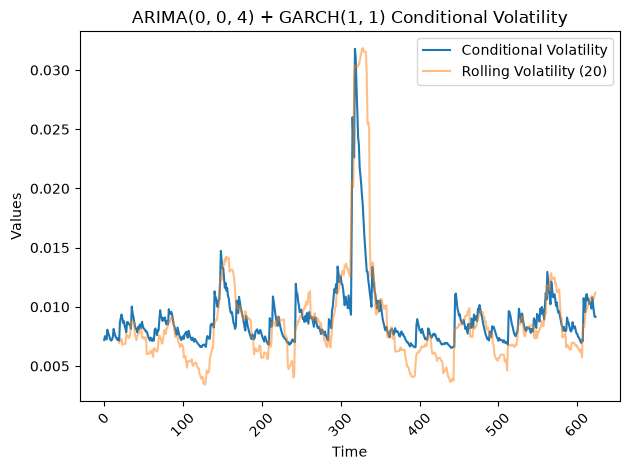

MAE between GARCH volatility and rolling volatility: 0.001601
MAPE between GARCH volatility and rolling volatility: 0.194794
RMSE between GARCH volatility and rolling volatility: 0.002609


In [47]:
# Using ARIMA(0,0,4) + GARCH(1,1)
sarima_model_1, garch_model_1, mae_1, mape_1, rmse_1 = sarima_garch_fit(sp500_log_returns, arima_order=(0, 0, 4), sarima_order=(0, 0, 0, 0), garch_order=(1, 1))

## S&P 500 Train

                       Zero Mean - GARCH Model Results                        
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.003
Vol Model:                      GARCH   Log-Likelihood:               -503.690
Distribution:                  Normal   AIC:                           1013.38
Method:            Maximum Likelihood   BIC:                           1025.15
                                        No. Observations:                  374
Date:                Mon, Nov 16 2026   Df Residuals:                      374
Time:                        17:31:47   Df Model:                            0
                              Volatility Model                             
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.0621  4.353e-02      1.426      0.154 [-2.32

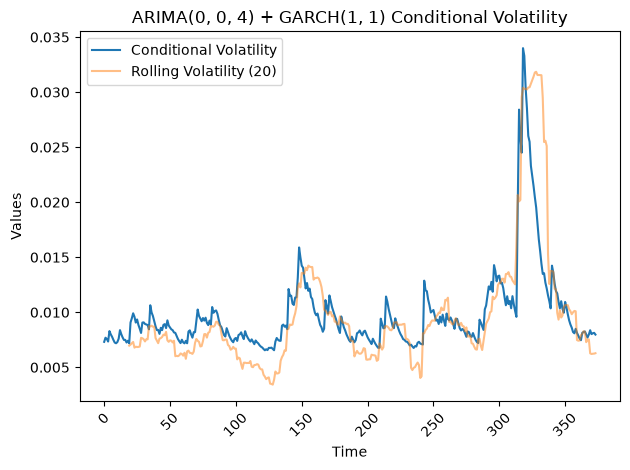

MAE between GARCH volatility and rolling volatility: 0.001937
MAPE between GARCH volatility and rolling volatility: 0.209145
RMSE between GARCH volatility and rolling volatility: 0.003107


In [48]:
# Using ARIMA(0,0,4) + GARCH(1,1)
sarima_model_2, garch_model_2, mae_2, mape_2, rmse_2 = sarima_garch_fit(sp500_train_lr, arima_order=(0, 0, 4), sarima_order=(0, 0, 0, 0), garch_order=(1, 1))

## Plotting predicted and actual S&P 500 prices 

In [49]:
def forecast_val_test(sarima_fit, garch_fit, y_full, adj_close, val_dates, test_dates,
                      garch_order=(1, 1), scale=100, show_band=False, plot=True):
    # ARMA: training parameters run over the full series (no re-estimation)
    res_all = sarima_fit.apply(y_full, refit=False)
    mu_hat  = res_all.fittedvalues

    # GARCH: training parameters run over the full residual series
    am    = arch_model(scale * res_all.resid, mean="Zero", vol="Garch",
                       p=garch_order[0], q=garch_order[1])
    sigma = pd.Series(np.asarray(am.fix(garch_fit.params).conditional_volatility) / scale,
                      index=y_full.index)

    # One-step price forecasts on validation + test dates
    dates  = val_dates.append(test_dates)
    P_prev = adj_close.shift(1).loc[dates]
    out = pd.DataFrame({
        "split":     ["Validation"] * len(val_dates) + ["Test"] * len(test_dates),
        "actual":    adj_close.loc[dates],
        "predicted": P_prev * np.exp(mu_hat.loc[dates]),
        "naive":     P_prev,
        "lower":     P_prev * np.exp(mu_hat.loc[dates] - 1.96 * sigma.loc[dates]),
        "upper":     P_prev * np.exp(mu_hat.loc[dates] + 1.96 * sigma.loc[dates]),
    }, index=dates)

    # Metrics per split
    def m(g):
        e, en = g["actual"] - g["predicted"], g["actual"] - g["naive"]
        rmse, rmse_n = np.sqrt(np.mean(e ** 2)), np.sqrt(np.mean(en ** 2))
        return pd.Series({"RMSE_price": rmse, "MAE_price": np.mean(np.abs(e)),
                          "RMSE_naive": rmse_n, "RMSE_ratio_vs_naive": rmse / rmse_n,
                          "Coverage_95": np.mean((g["actual"] >= g["lower"]) &
                                                 (g["actual"] <= g["upper"]))})
    metrics = out.groupby("split", sort=False).apply(m).T
    print(metrics.round(4))

    if plot:
        hist = adj_close.loc[:val_dates[0]].iloc[-60:]         # last 60 training days for context
        plt.figure(figsize=(13, 5))
        plt.plot(pd.concat([hist, out["actual"]]), label="Actual", lw=1.5)
        plt.plot(out["predicted"], "--", label="Predicted (one-step)", lw=1)
        if show_band:
            plt.fill_between(dates, out["lower"], out["upper"], alpha=0.2, label="95% band")
        plt.axvspan(val_dates[0], val_dates[-1], color="orange", alpha=0.08, label="Validation")
        plt.axvspan(test_dates[0], test_dates[-1], color="green", alpha=0.08, label="Test")
        plt.title("ARMA(0,4)-GARCH(1,1): actual vs predicted (training-fitted parameters)")
        plt.xlabel("Date"); plt.ylabel("Adjusted close")
        plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

    return out, metrics

True True
split                Validation     Test
RMSE_price              34.7491  59.9862
MAE_price               27.3515  45.4696
RMSE_naive              35.7091  59.4083
RMSE_ratio_vs_naive      0.9731   1.0097
Coverage_95              0.9841   0.9572


c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


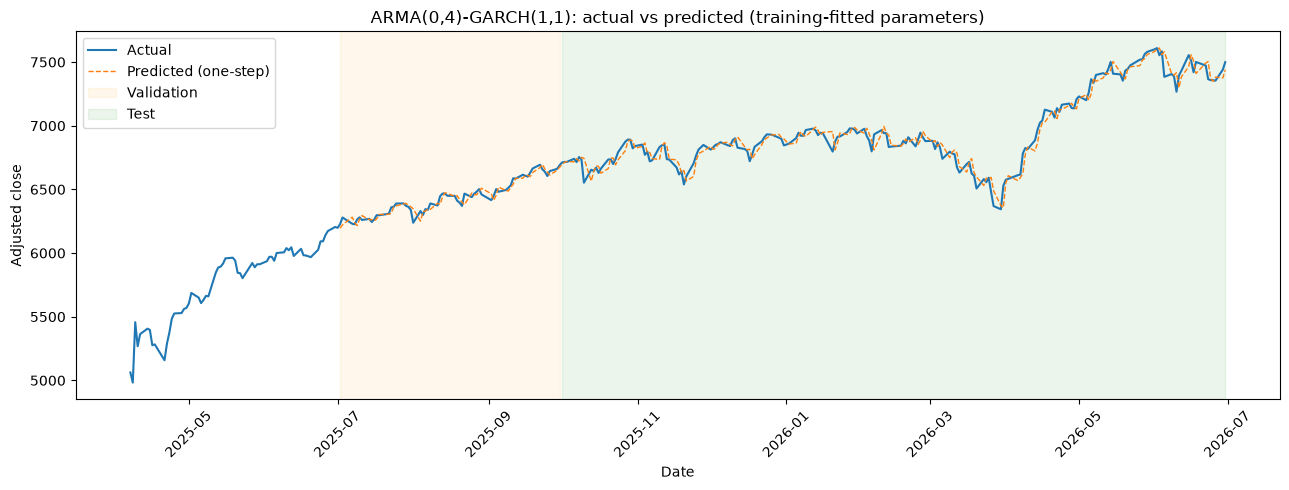

In [50]:
sp = sp500.copy()
sp.index = pd.to_datetime(sp["Date"].squeeze()).dt.tz_localize(None)

adj_close = sp["Adj Close"].squeeze()
y_full    = np.log(adj_close).diff().dropna()
val_dates, test_dates = val_sp500.index, test_sp500.index

print(val_dates.isin(adj_close.index).all(), test_dates.isin(adj_close.index).all())  # both True

pred_df, metrics = forecast_val_test(sarima_model_2, garch_model_2, y_full, adj_close,
                                     val_dates, test_dates)

# Testing validation and test data 

In [51]:
def evaluate_split(sarima_fit, garch_fit, y_full, adj_close, dates,
                   garch_order=(1, 1), scale=100, label="", plot=True):
    # ARMA: training parameters, run over the full return series
    res_all = sarima_fit.apply(y_full, refit=False)
    mu_hat = res_all.fittedvalues

    # GARCH: training parameters, run over the full residual series
    am = arch_model(scale * res_all.resid, mean="Zero", vol="Garch",
                    p=garch_order[0], q=garch_order[1])
    g_full = am.fix(garch_fit.params)
    sigma = pd.Series(np.asarray(g_full.conditional_volatility) / scale,
                      index=y_full.index)

    # Convert to prices on the chosen dates
    P_prev = adj_close.shift(1).loc[dates]
    actual = adj_close.loc[dates]
    mu, sig = mu_hat.loc[dates], sigma.loc[dates]
    P_hat = P_prev * np.exp(mu)
    lo, hi = P_prev * np.exp(mu - 1.96 * sig), P_prev * np.exp(mu + 1.96 * sig)

    r_act = y_full.loc[dates]
    rmse = np.sqrt(np.mean((actual - P_hat) ** 2))
    rmse_naive = np.sqrt(np.mean((actual - P_prev) ** 2))
    metrics = {
        "RMSE_price": rmse,
        "MAE_price": np.mean(np.abs(actual - P_hat)),
        "RMSE_naive": rmse_naive,
        "RMSE_ratio_vs_naive": rmse / rmse_naive,
        "RMSE_return": np.sqrt(np.mean((r_act - mu) ** 2)),
        "Direction_acc": np.mean(np.sign(mu) == np.sign(r_act)),
        "Coverage_95": np.mean((actual >= lo) & (actual <= hi)),
    }

    print(f"\n===== {label} ({len(dates)} days: {dates[0].date()} -> {dates[-1].date()}) =====")
    for k, v in metrics.items():
        print(f"{k:22s}: {v:.6f}")

    if plot:
        plt.figure(figsize=(12, 5))
        plt.plot(actual, label="Actual", lw=1.5)
        plt.plot(P_hat, "--", label="Predicted", lw=1)
        plt.fill_between(dates, lo, hi, alpha=0.2, label="95% band (GARCH)")
        plt.title(f"{label}: actual vs predicted adjusted close")
        plt.xlabel("Date"); plt.ylabel("Price")
        plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

    out = pd.DataFrame({"actual": actual, "predicted": P_hat, "lower": lo, "upper": hi})
    return metrics, out

c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



===== Validation (63 days: 2025-07-02 -> 2025-09-30) =====
RMSE_price            : 34.749130
MAE_price             : 27.351473
RMSE_naive            : 35.709098
RMSE_ratio_vs_naive   : 0.973117
RMSE_return           : 0.005441
Direction_acc         : 0.555556
Coverage_95           : 0.984127


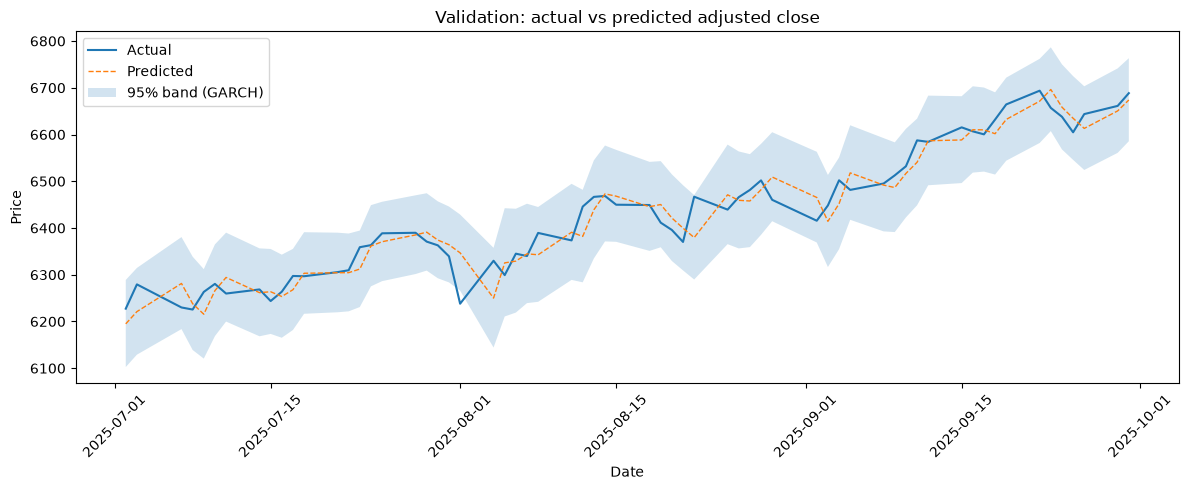

c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



===== Test (187 days: 2025-10-01 -> 2026-06-30) =====
RMSE_price            : 59.986215
MAE_price             : 45.469649
RMSE_naive            : 59.408270
RMSE_ratio_vs_naive   : 1.009728
RMSE_return           : 0.008680
Direction_acc         : 0.508021
Coverage_95           : 0.957219


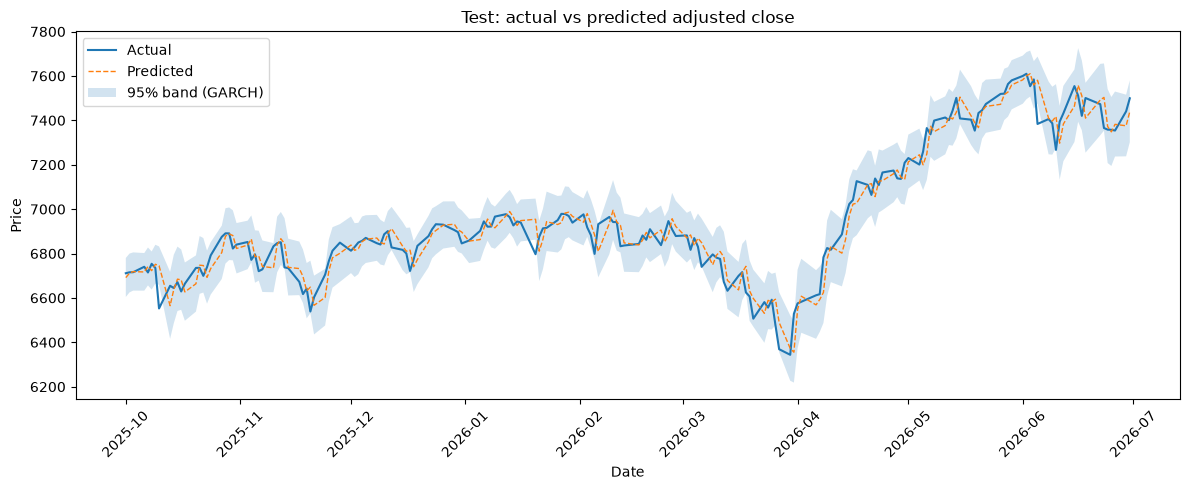

,Validation,Test
RMSE_price,34.749130,59.986215
MAE_price,27.351473,45.469649
RMSE_naive,35.709098,59.408270
RMSE_ratio_vs_naive,0.973117,1.009728
RMSE_return,0.005441,0.008680
Direction_acc,0.555556,0.508021
Coverage_95,0.984127,0.957219


In [52]:
date_col = "Date"       # change to "date" if that's what it's called
sp = sp500.copy()
sp.index = pd.to_datetime(sp[date_col].squeeze()).dt.tz_localize(None)

adj_close = sp["Adj Close"].squeeze()
y_full    = np.log(adj_close).diff().dropna()

val_dates, test_dates = val_sp500.index, test_sp500.index

val_metrics, val_df = evaluate_split(sarima_model_2, garch_model_2, y_full, adj_close,
                                     val_dates, label="Validation")
test_metrics, test_df = evaluate_split(sarima_model_2, garch_model_2, y_full, adj_close,
                                       test_dates, label="Test")

pd.DataFrame({"Validation": val_metrics, "Test": test_metrics})

c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is ava

             actual  predicted   error
Date                                  
2026-04-02  6582.69    6607.58  -24.89
2026-04-06  6611.83    6592.07   19.76
2026-04-07  6616.85    6577.41   39.44
2026-04-08  6782.81    6579.67  203.14
2026-04-09  6824.66    6584.31  240.35
RMSE over 3 days: 142.55


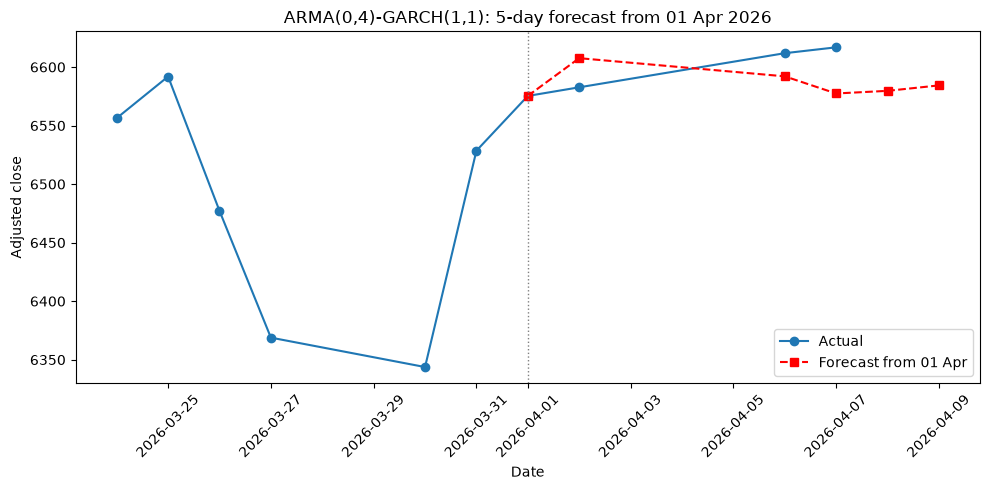

In [53]:
from statsmodels.tsa.arima_process import arma2ma

origin = pd.Timestamp("2026-04-01")
H = 5

# ARMA: training parameters, information up to the origin only
res_o = sarima_model_2.apply(y_full.loc[:origin], refit=False)
mu_f  = np.asarray(res_o.get_forecast(steps=H).predicted_mean)

# Convert to prices
P_T     = adj_close.loc[origin]
f_dates = adj_close.index[adj_close.index > origin][:H]
P_hat   = pd.Series(P_T * np.exp(np.cumsum(mu_f)), index=f_dates)

# Compare with actual values
actual = adj_close.loc["2026-03-24":"2026-04-07"]
comp = pd.DataFrame({"actual": adj_close.loc[f_dates], "predicted": P_hat})
comp["error"] = comp["actual"] - comp["predicted"]
print(comp.round(2))
print("RMSE over 3 days:", np.sqrt(np.mean(comp["error"] ** 2)).round(2))

plt.figure(figsize=(10, 5))
plt.plot(actual, "o-", label="Actual", lw=1.5)
plt.plot(pd.concat([pd.Series([P_T], index=[origin]), P_hat]), "s--",
         color="red", label=f"Forecast from {origin:%d %b}")
plt.axvline(origin, color="grey", ls=":", lw=1)
plt.title(f"ARMA(0,4)-GARCH(1,1): {H}-day forecast from {origin:%d %b %Y}")
plt.xlabel("Date"); plt.ylabel("Adjusted close")
plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

# Navie Forecasting


===== Naive 1-step, Test (187 days: 2025-10-01 -> 2026-06-30) =====
RMSE_price  : 59.408270
MAE_price   : 45.095210
MAPE_price  : 0.650964


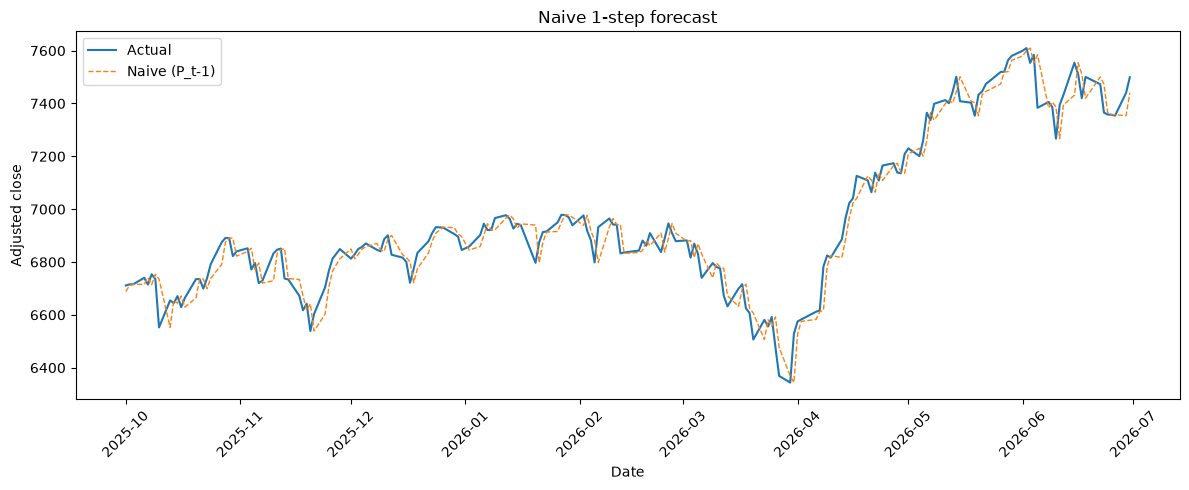

In [54]:
def naive_forecast(adj_close, dates, h=1, label="Test", plot=True):
    P_hat  = adj_close.shift(h).loc[dates]      # last known price, h days earlier
    actual = adj_close.loc[dates]
    err    = actual - P_hat

    metrics = {
        "RMSE_price": np.sqrt(np.mean(err ** 2)),
        "MAE_price":  np.mean(np.abs(err)),
        "MAPE_price": np.mean(np.abs(err / actual)) * 100,
    }

    print(f"\n===== Naive {h}-step, {label} ({len(dates)} days: "
          f"{dates[0].date()} -> {dates[-1].date()}) =====")
    for k, v in metrics.items():
        print(f"{k:12s}: {v:.6f}")

    if plot:
        plt.figure(figsize=(12, 5))
        plt.plot(actual, label="Actual", lw=1.5)
        plt.plot(P_hat, "--", label=f"Naive (P_t-{h})", lw=1)
        plt.title(f"Naive {h}-step forecast")
        plt.xlabel("Date"); plt.ylabel("Adjusted close")
        plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

    return metrics, pd.DataFrame({"actual": actual, "predicted": P_hat})


naive_metrics, naive_df = naive_forecast(adj_close, test_dates, h=1)

             actual  predicted  error
Date                                 
2026-04-02  6582.69    6575.32   7.37
2026-04-06  6611.83    6575.32  36.51
2026-04-07  6616.85    6575.32  41.53
Naive (recursive) RMSE over 3 days: 32.21


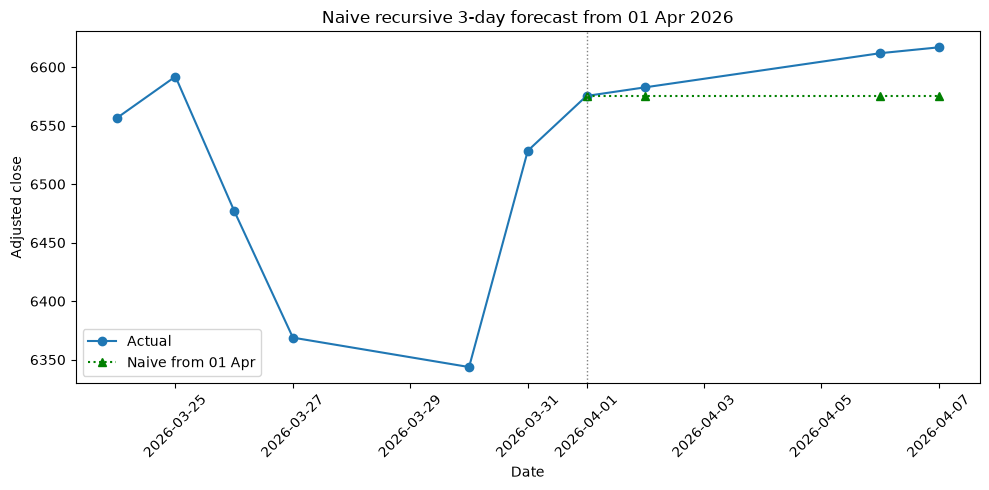

In [55]:
def naive_recursive(adj_close, origin, H=3, window=None, plot=True):
    origin  = pd.Timestamp(origin)
    f_dates = adj_close.index[adj_close.index > origin][:H]

    forecasts = []
    prev = adj_close.loc[origin]          # last actual price at the origin
    for _ in range(H):
        today = prev                      # today's forecast = previous forecast
        forecasts.append(today)
        prev = today

    P_hat = pd.Series(forecasts, index=f_dates)
    comp = pd.DataFrame({"actual": adj_close.loc[f_dates], "predicted": P_hat})
    comp["error"] = comp["actual"] - comp["predicted"]
    rmse = np.sqrt(np.mean(comp["error"] ** 2))
    print(comp.round(2))
    print(f"Naive (recursive) RMSE over {H} days: {rmse:.2f}")

    if plot:
        actual = adj_close.loc[window[0]:window[1]] if window else adj_close.loc[f_dates]
        plt.figure(figsize=(10, 5))
        plt.plot(actual, "o-", label="Actual", lw=1.5)
        plt.plot(pd.concat([pd.Series([adj_close.loc[origin]], index=[origin]), P_hat]),
                 "^:", color="green", label=f"Naive from {origin:%d %b}")
        plt.axvline(origin, color="grey", ls=":", lw=1)
        plt.title(f"Naive recursive {H}-day forecast from {origin:%d %b %Y}")
        plt.xlabel("Date"); plt.ylabel("Adjusted close")
        plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

    return comp, rmse


comp_naive, rmse_naive = naive_recursive(adj_close, "2026-04-01", H=3,
                                         window=("2026-03-24", "2026-04-07"))

In [56]:
def compare_at_origin(craft_values, origin, window, sarima_fit=sarima_model_2,
                      y_full=y_full, adj_close=adj_close):
    origin = pd.Timestamp(origin)
    H = len(craft_values)
    f_dates = adj_close.index[adj_close.index > origin][:H]
    P_T = adj_close.loc[origin]

    # ARMA-GARCH: H-step forecast using data up to the origin only
    res = sarima_fit.apply(y_full.loc[:origin], refit=False)
    mu  = np.asarray(res.get_forecast(steps=H).predicted_mean)

    comp = pd.DataFrame({
        "actual":     adj_close.loc[f_dates],
        "CRAFT":      craft_values,
        "ARMA-GARCH": P_T * np.exp(np.cumsum(mu)),
        "Naive":      P_T,
    }, index=f_dates)
    print(comp.round(2))

    rmse = {m: np.sqrt(np.mean((comp["actual"] - comp[m]) ** 2))
            for m in ["CRAFT", "ARMA-GARCH", "Naive"]}
    print("\nRMSE:", {m: round(v, 2) for m, v in rmse.items()})

    styles = {"CRAFT": ("tab:blue", "o-"), "ARMA-GARCH": ("tab:red", "s--"),
              "Naive": ("tab:green", "^:")}
    start = pd.Series([P_T], index=[origin])

    plt.figure(figsize=(10, 5))
    plt.plot(adj_close.loc[window[0]:window[1]], "o-", color="black", lw=1.5, label="Actual")
    for m, (colour, style) in styles.items():
        plt.plot(pd.concat([start, comp[m]]), style, color=colour, lw=1.2, label=m)
    plt.axvline(origin, color="grey", ls=":", lw=1)
    plt.title(f"{H}-day forecasts from {origin:%d %b %Y}")
    plt.xlabel("Date"); plt.ylabel("Adjusted close")
    plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

    return comp, rmse

c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is ava

             actual    CRAFT  ARMA-GARCH    Naive
Date                                             
2026-04-02  6582.69  6613.45     6607.58  6575.32
2026-04-06  6611.83  6638.20     6592.07  6575.32
2026-04-07  6616.85  6644.71     6577.41  6575.32

RMSE: {'CRAFT': np.float64(28.39), 'ARMA-GARCH': np.float64(29.24), 'Naive': np.float64(32.21)}


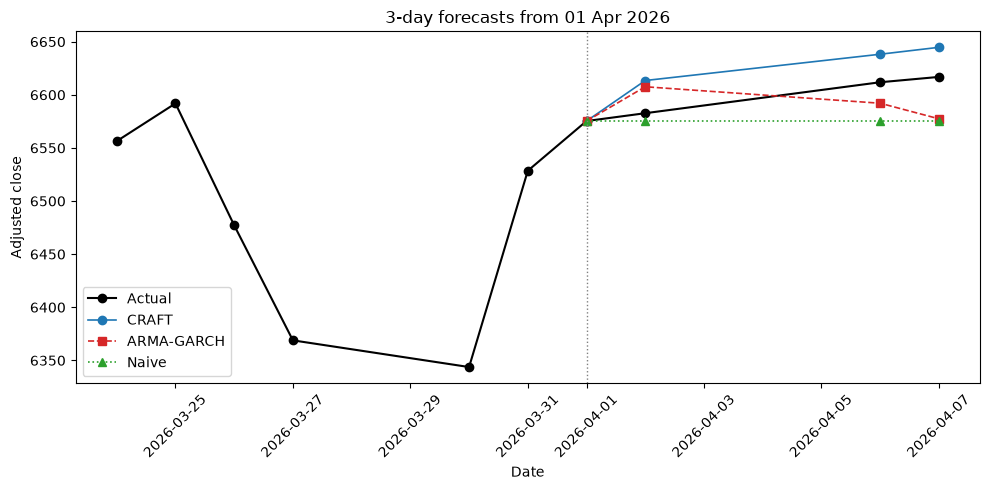

In [58]:
comp, rmse = compare_at_origin(
    craft_values=[6613.45, 6638.20, 6644.71],    # replace with CRAFT's 23, 24, 25 Mar forecasts
    origin="2026-04-01",
    window=("2026-03-24", "2026-04-07"))

c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Glenn\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


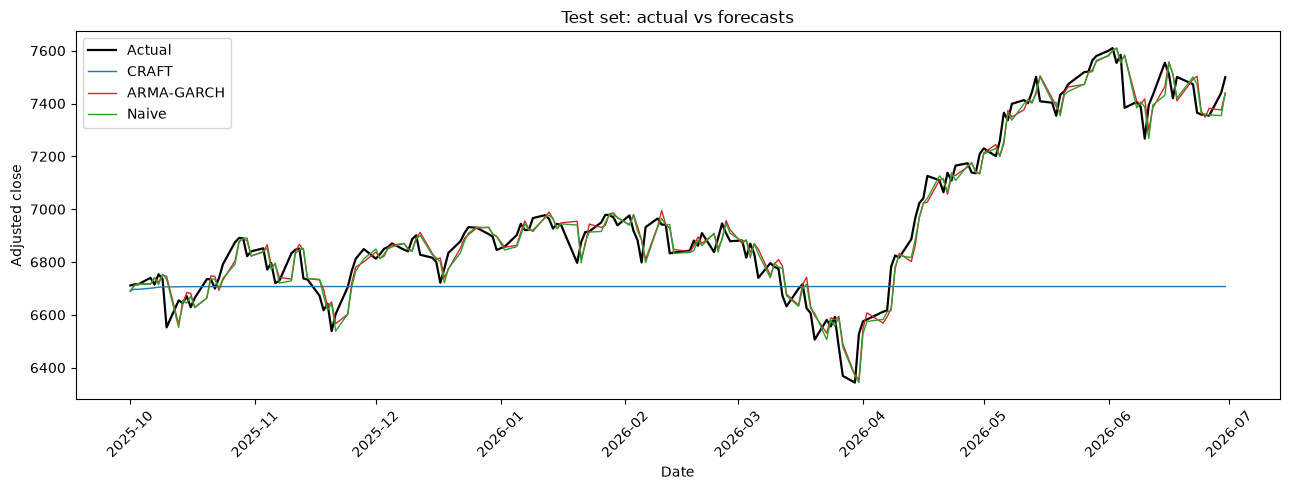

In [59]:
def plot_full_test(craft_values, test_dates, craft_dates=None,
                   sarima_fit=sarima_model_2, y_full=y_full, adj_close=adj_close):
    dates = test_dates if craft_dates is None else pd.DatetimeIndex(craft_dates)

    mu_hat = sarima_fit.apply(y_full, refit=False).fittedvalues
    P_prev = adj_close.shift(1).loc[dates]

    plt.figure(figsize=(13, 5))
    plt.plot(adj_close.loc[dates], color="black", lw=1.6, label="Actual")
    plt.plot(dates, np.asarray(craft_values, dtype=float).ravel(),
             color="tab:blue", lw=1, label="CRAFT")
    plt.plot(P_prev * np.exp(mu_hat.loc[dates]), color="tab:red", lw=1, label="ARMA-GARCH")
    plt.plot(P_prev, color="tab:green", lw=1, label="Naive")
    plt.title("Test set: actual vs forecasts")
    plt.xlabel("Date"); plt.ylabel("Adjusted close")
    plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

craft_test = [6691.27001953125, 6697.10888671875, 6696.73681640625, 6701.21533203125, 6702.31982421875, 6704.92529296875, 6705.14501953125, 6706.0302734375, 6706.07861328125, 6706.58984375, 6706.66162109375, 6706.93310546875, 6706.95068359375, 6707.0625, 6707.068359375, 6707.12646484375, 6707.130859375, 6707.16064453125, 6707.16162109375, 6707.17529296875, 6707.17529296875, 6707.181640625, 6707.181640625, 6707.18505859375, 6707.185546875, 6707.18798828125, 6707.1884765625, 6707.189453125, 6707.18896484375, 6707.189453125, 6707.18896484375, 6707.189453125, 6707.18896484375, 6707.1884765625, 6707.18798828125, 6707.18798828125, 6707.18798828125, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875, 6707.1875]

plot_full_test(craft_test, test_dates)